# Assistant multi-agent pour la sélection intelligente de portefeuilles financiers

**Projet de Machine Learning** – École Centrale de Casablanca – cours « Introduction aux techniques d'apprentissage automatique ».
Notebook principal, version 4 (refonte alignée sur le cours).

## Problématique
Un conseiller doit proposer à chaque client un portefeuille **adapté à son profil** et **à l'état des marchés**, puis **justifier** sa recommandation. Nous construisons un système de plusieurs agents spécialisés qui coopèrent, chacun s'appuyant sur une famille de méthodes du cours :

| Agent | Question traitée | Paradigme du cours | Méthodes |
|---|---|---|---|
| **Profil** | Le client peut-il supporter des pertes ? | Supervisé – classification binaire | Logistique, KNN, SVM, arbres, forêts, boosting, MLP ; SMOTE / ADASYN |
| **Prévision** | Quels actifs vont surperformer le mois prochain ? | Supervisé – régression sur **données temporelles** | Ridge, Lasso, Elastic Net, KNN, SVR, arbres, boosting, MLP ; ACP |
| **Régime** | Le marché est-il calme ou stressé ? | Non supervisé – clustering | K-means, CAH, DBSCAN, mélange gaussien (EM) |
| **Alerte** | La journée est-elle anormale ? | Non supervisé – détection d'anomalies | z-score, Grubbs, gaussienne multivariée, Isolation Forest, LOF, One-Class SVM |
| **Risque** | Quel est le risque du portefeuille ? | Statistique | Covariance de Ledoit-Wolf, VaR, CVaR |
| **Allocation** | Quel portefeuille choisir ? | Optimisation / renforcement | Moyenne-variance (Black-Litterman), parité de risque, HRP, agent PPO |
| **Explication** | Pourquoi cette recommandation ? | Interprétabilité | Coefficients, permutation, SHAP global et local |

Les agents échangent par un **tableau noir** partagé, coordonnés par un **orchestrateur** : c'est une architecture d'**IA agentique**.

## Démarche (processus de développement d'un algorithme supervisé, cours 1)
compréhension du problème → collecte et nettoyage → compréhension des données (EDA) → préparation → séparation entraînement / validation / test → entraînement → évaluation → optimisation des hyperparamètres → déploiement.

## Plan du notebook
0. Configuration
1. Collecte des données réelles (open data)
2. Prétraitement et analyse exploratoire des marchés
3. **Agent Profil** – classification supervisée et classes déséquilibrées
4. **Agent Prévision** – apprentissage supervisé sur données temporelles (fenêtre glissante, ACP, régression régularisée, 3 méthodes d'évaluation, test de Diebold-Mariano)
5. **Agent Régime et Agent Alerte** – clustering et détection d'anomalies
6. Système multi-agent – orchestration et allocation
7. Backtest walk-forward sur la période de test
8. **Agent d'apprentissage par renforcement** (PPO)
9. Sauvegarde des artefacts pour l'application
10. Synthèse des résultats et conclusion

> **Règle de prévention des fuites de données** : les jeux d'entraînement, de validation et de test sont séparés **avant** tout prétraitement. Toute transformation qui apprend quelque chose des données (imputation, standardisation, ACP, rééchantillonnage SMOTE…) est placée dans un `Pipeline` et ajustée **sur l'entraînement uniquement**. La période de test ne sert à **aucun** choix.

## 0. Configuration

`QUICK_RUN = True` exécute le notebook en mode rapide (grilles réduites, moins de simulations), pour vérifier que tout fonctionne. Les résultats du rapport sont obtenus avec `QUICK_RUN = False`.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from src.config import *
from src import data_download as dl

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 30)
np.random.seed(RANDOM_STATE)

QUICK_RUN = False    # True : mise au point rapide | False : résultats finaux du rapport
N_ITER = 3 if QUICK_RUN else 10   # combinaisons d'hyperparamètres testées par modèle (recherche aléatoire)
N_JOBS = -1
RESULTS = {}         # tableaux collectés pour la synthèse finale

_T0 = _TLAST = time.time()
DUREES = {}


def chrono(etape: str):
    # Affiche le temps de calcul de l'étape qui vient de se terminer (objectif : notebook < 1 h 30)
    global _TLAST
    now = time.time()
    DUREES[etape] = now - _TLAST
    print(f"⏱ {etape} : {now - _TLAST:.0f} s (cumul {(now - _T0) / 60:.1f} min)")
    _TLAST = now


def savefig(name: str):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print(f"Racine du projet : {ROOT} | mode rapide : {QUICK_RUN}")

Racine du projet : C:\Users\HP\Downloads\Projet_MultiAgent_Portefeuille | mode rapide : False


## 1. Collecte des données réelles

Toutes les données sont **ouvertes** (open data) et téléchargées automatiquement par `src/data_download.py`.

| Source | Contenu | Fréquence | Utilisée par |
|---|---|---|---|
| **Yahoo Finance** (`yfinance`) | Cours de clôture ajustés (dividendes, divisions) de 25 actifs : ETF actions, secteurs, obligations, immobilier, matières premières, monétaire, Bitcoin | Quotidienne, 2010 → aujourd'hui | Prévision, Régime, Alerte, Risque, Allocation |
| **FRED** (Federal Reserve Bank of St. Louis) | Taux 3 mois / 2 ans / 10 ans, pente de courbe, spread de crédit Baa, VIX, inflation, chômage, production industrielle | Quotidienne / mensuelle | Prévision, Régime |
| **Survey of Consumer Finances 2022** (Réserve fédérale) | ~4 600 ménages américains (× 5 imputations) : âge, revenus, patrimoine, dettes, éducation, connaissances financières, **tolérance au risque déclarée** | Coupe transversale | Profil |
| **Survey of Consumer Finances 2019** | Autre vague de la même enquête | Coupe transversale | Validation externe du Profil |

Les fichiers bruts sont mis en cache dans `data/raw/` : une nouvelle exécution ne retélécharge rien, ce qui garantit la **reproductibilité**.

In [2]:
univers = pd.DataFrame([(t, n, c) for t, (n, c) in UNIVERSE.items()],
                       columns=["Ticker", "Libellé", "Classe d'actifs"]).set_index("Ticker")
display(univers.groupby("Classe d'actifs").size().rename("nb actifs").to_frame().T)
univers

Classe d'actifs,Actions,Crypto,Immobilier,Matières premières,Monétaire,Obligations
nb actifs,13,1,1,3,1,6


,Libellé,Classe d'actifs
Ticker,,
SPY,S&P 500,Actions
QQQ,Nasdaq 100,Actions
IWM,Russell 2000 (petites capitalisations),Actions
EFA,Actions pays développés hors US,Actions
EEM,Actions pays émergents,Actions
XLK,Secteur Technologie,Actions
XLF,Secteur Finance,Actions
XLV,Secteur Santé,Actions
XLE,Secteur Énergie,Actions


In [3]:
close_raw, volume_raw = dl.download_yahoo()
fred_raw = dl.download_fred()
scf_raw = dl.download_scf()

print("Cours Yahoo :", close_raw.shape, close_raw.index.min().date(), "→", close_raw.index.max().date())
print("Séries FRED :", fred_raw.shape)
print("SCF 2022    :", scf_raw.shape)
chrono("1. Collecte des données")

[Yahoo] cache chargé : 5634 dates x 25 actifs
[FRED] cache chargé : 9 séries
[SCF 2022] cache chargé : (22975, 362)
Cours Yahoo : (5634, 25) 2010-01-04 → 2026-11-22
Séries FRED : (4993, 9)
SCF 2022    : (22975, 362)
⏱ 1. Collecte des données : 0 s (cumul 0.0 min)


## 2. Prétraitement et analyse exploratoire des marchés

> **Rappel du cours (défis du ML)** : « des données de mauvaise qualité génèrent de faux résultats, donc de mauvaises décisions ». La qualité et la préparation des données passent avant le choix du modèle.

### 2.1 Diagnostic de qualité des données brutes
Problèmes typiques des données financières réelles :
- **calendriers différents** : le Bitcoin cote 7 jours sur 7, les ETF seulement les jours ouvrés de la bourse de New York (NYSE) ;
- **historiques de longueurs différentes** (Bitcoin disponible à partir de septembre 2014) ;
- **valeurs manquantes** ponctuelles (jours fériés, trous de l'API) ;
- **valeurs aberrantes** (pics isolés dus à des erreurs de cotation).

In [4]:
from src.preprocessing import clean_prices, compute_returns, build_macro_features, risk_free_daily

first = close_raw.apply(lambda s: s.first_valid_index())
quality = pd.DataFrame({
    "Première cotation": first.dt.date,
    "Nb observations": close_raw.count(),
    "% manquants après 1re cotation": [close_raw.loc[first[c]:, c].isna().mean() * 100 for c in close_raw],
    "Jours à volume nul": (volume_raw == 0).sum(),
})
quality

,Première cotation,Nb observations,% manquants après 1re cotation,Jours à volume nul
SPY,2010-01-04,4248,24.6006,0
QQQ,2010-01-04,4248,24.6006,0
IWM,2010-01-04,4248,24.6006,0
EFA,2010-01-04,4248,24.6006,0
EEM,2010-01-04,4248,24.6006,0
XLK,2010-01-04,4248,24.6006,0
XLF,2010-01-04,4248,24.6006,0
XLV,2010-01-04,4248,24.6006,0
XLE,2010-01-04,4248,24.6006,0
XLY,2010-01-04,4248,24.6006,0


**Nettoyage** (`clean_prices`) : (1) tri et suppression des dates en double ; (2) alignement sur le calendrier NYSE ; (3) suppression des prix nuls ou négatifs ; (4) suppression des pics aberrants « aller-retour » de plus de 40 % en deux jours (hors Bitcoin) ; (5) propagation de la dernière valeur connue sur 5 jours au plus. Le remplissage se fait **uniquement vers l'avant** : remplir vers l'arrière utiliserait une information future.

dates_brutes                : 5634
dates_calendrier_NYSE       : 4248
prix_non_positifs           : 0
pics_aberrants              : 0


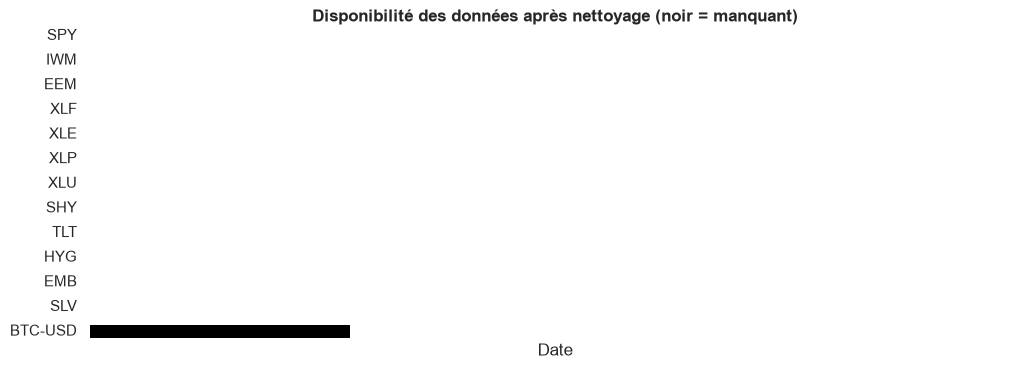

In [5]:
prices, clean_report = clean_prices(close_raw)
for k in ("dates_brutes", "dates_calendrier_NYSE", "prix_non_positifs", "pics_aberrants"):
    print(f"{k:<28}: {clean_report[k]}")
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(prices.isna().T.astype(int).iloc[:, ::5], cbar=False, cmap="Greys", ax=ax)
ax.set_title("Disponibilité des données après nettoyage (noir = manquant)")
ax.set_xticks([])
savefig("01_disponibilite_donnees")
plt.show()

### 2.2 Rendements et valeurs extrêmes
On travaille sur les **rendements** $r_t = P_t / P_{t-1} - 1$, à peu près stationnaires, et non sur les prix, qui ne le sont pas.

Une valeur extrême n'est pas forcément une erreur. Le **z-score** (méthode statistique de détection d'anomalies du cours) repère les rendements à plus de 6 écarts-types. Ce sont de vrais événements de marché (krach de mars 2020…) : ils sont **conservés**, car ce sont précisément les risques que le système doit apprendre à gérer.

In [6]:
returns = compute_returns(prices)
z = (returns - returns.mean()) / returns.std()
extremes = (z.abs() > 6).sum().sort_values(ascending=False)
print("Nombre de rendements à plus de 6 écarts-types (conservés) :")
display(extremes[extremes > 0].to_frame("nb").T)
spy_ext = returns["SPY"][z["SPY"].abs() > 6].sort_values()
print("Exemples (S&P 500) :")
display(spy_ext.head(6).to_frame("rendement du jour"))

Nombre de rendements à plus de 6 écarts-types (conservés) :


,HYG,LQD,EMB,EFA,SHY,XLP,XLF,VNQ,SPY,XLU,XLE,XLI,SLV,IWM,XLK,XLV,XLY,QQQ,EEM,TIP,TLT,DBC,IEF,GLD,BTC-USD
nb,11,10,10,8,8,8,8,8,8,7,7,7,6,6,6,6,5,4,4,4,4,4,3,3,2


Exemples (S&P 500) :


,rendement du jour
Date,
2020-03-16,-0.1094
2020-03-12,-0.0957
2020-03-09,-0.0781
2011-08-08,-0.0651
2020-04-06,0.0672
2020-03-13,0.0855


### 2.3 Variables macroéconomiques sans fuite temporelle
Une donnée macroéconomique n'est utilisable qu'à sa **date de publication**, pas à sa date de référence. Sinon, le modèle utiliserait une information qui n'existait pas encore : c'est une **fuite de données**.
- Séries quotidiennes (taux, VIX) : décalées d'un jour ouvré (publiées à J+1).
- Séries mensuelles (inflation, chômage) : la valeur du mois M n'est disponible qu'à partir du 15 du mois M+1.

In [7]:
macro = build_macro_features(fred_raw, prices.index)
rf_daily = risk_free_daily(macro)
display(macro.describe().T[["count", "mean", "std", "min", "max"]])

prices.to_csv(DATA_PROC / "prices_clean.csv")
returns.to_csv(DATA_PROC / "returns_daily.csv")
macro.to_csv(DATA_PROC / "macro_features.csv")
print("Données nettoyées enregistrées dans", DATA_PROC)

,count,mean,std,min,max
DGS10,"4,247.0000",2.7129,1.0713,0.5200,5.3100
DGS2,"4,247.0000",1.7539,1.6045,0.0900,5.1900
DTB3,"4,247.0000",1.5085,1.8361,-0.0500,5.3600
T10Y2Y,"4,247.0000",0.9591,0.9325,-1.0800,2.9100
BAA10Y,"4,247.0000",2.3246,0.5468,1.3600,4.3100
VIX,"4,247.0000",18.4103,6.7381,9.1400,82.6900
CPI_yoy,"4,248.0000",2.6380,1.8605,-0.2299,8.9794
UNRATE,"4,248.0000",5.6662,2.1832,3.4000,14.8000
UNRATE_chg3m,"4,248.0000",-0.0824,1.3069,-4.8000,11.2000
INDPRO_yoy,"4,248.0000",1.0133,3.6569,-17.3183,16.5521


Données nettoyées enregistrées dans C:\Users\HP\Downloads\Projet_MultiAgent_Portefeuille\data\processed


### 2.4 Analyse exploratoire
Pour ne pas orienter nos choix de modélisation avec des informations de la période de test, les statistiques qui **guident la modélisation** sont calculées sur la période d'entraînement (2010-2019). Les graphiques de contexte couvrent toute la période.

In [8]:
train_mask = returns.index <= TRAIN_END
R_tr = returns[train_mask]


def describe_returns(R: pd.DataFrame) -> pd.DataFrame:
    w = (1 + R.fillna(0)).cumprod()
    out = pd.DataFrame({
        "Classe": pd.Series(ASSET_CLASS),
        "Rdt annualisé": R.mean() * 252,
        "Vol annualisée": R.std() * np.sqrt(252),
        "Asymétrie": R.skew(),
        "Kurtosis (excès)": R.kurt(),
        "Max drawdown": (w / w.cummax() - 1).min(),
        "p-val Jarque-Bera": [stats.jarque_bera(R[c].dropna()).pvalue for c in R],
    })
    out["Sharpe (rf=0)"] = out["Rdt annualisé"] / out["Vol annualisée"]
    return out.loc[R.columns]


stats_train = describe_returns(R_tr)
stats_train.to_csv(RESULTS_DIR / "stats_actifs_train.csv")
stats_train.sort_values("Classe")

,Classe,Rdt annualisé,Vol annualisée,Asymétrie,Kurtosis (excès),Max drawdown,p-val Jarque-Bera,Sharpe (rf=0)
SPY,Actions,0.1355,0.1469,-0.4256,4.3939,-0.1935,0.0000,0.9221
QQQ,Actions,0.1779,0.1725,-0.3151,3.0882,-0.2280,0.0000,1.0312
IWM,Actions,0.1281,0.1923,-0.2406,3.7437,-0.2891,0.0000,0.6663
EFA,Actions,0.0661,0.1774,-0.4661,5.9975,-0.2586,0.0000,0.3728
EEM,Actions,0.0481,0.2106,-0.1921,2.9114,-0.3750,0.0000,0.2283
XLK,Actions,0.1682,0.1701,-0.3264,3.0710,-0.2378,0.0000,0.9892
XLF,Actions,0.1316,0.1970,-0.2870,4.6780,-0.3368,0.0000,0.6679
XLV,Actions,0.1459,0.1485,-0.3552,2.4812,-0.1733,0.0000,0.9821
XLE,Actions,0.0528,0.2161,-0.1952,2.5107,-0.4675,0.0000,0.2441
XLY,Actions,0.1711,0.1625,-0.3753,3.2614,-0.2137,0.0000,1.0525


**Lecture** : tous les rendements journaliers ont une kurtosis en excès positive (**queues épaisses**), et la normalité est rejetée (p-valeurs de Jarque-Bera ≈ 0). Conséquences pour la suite : (i) mesurer le risque aussi par des quantiles historiques (VaR, CVaR), pas seulement par la volatilité ; (ii) écrêter les variables extrêmes (winsorisation) dans les pipelines ; (iii) préférer des modèles robustes aux valeurs extrêmes, comme les arbres.

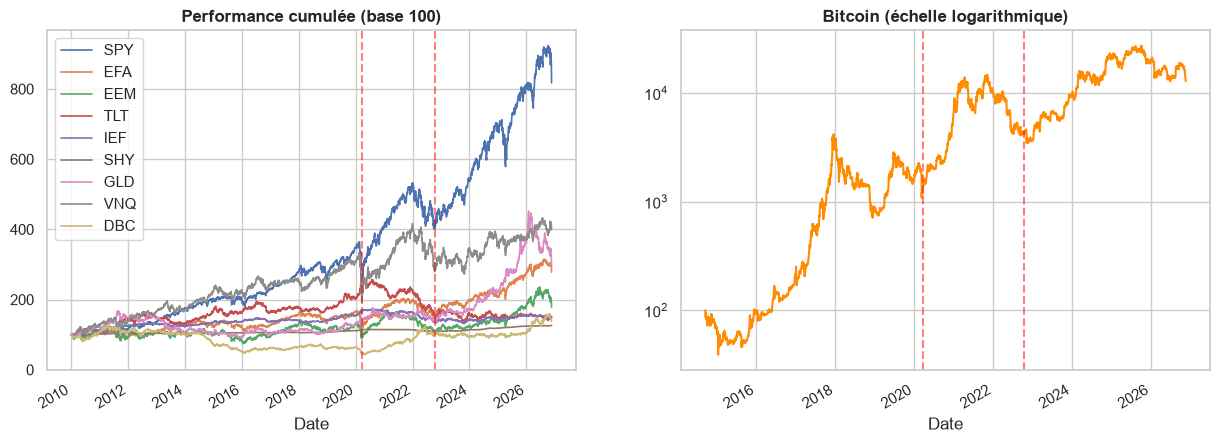

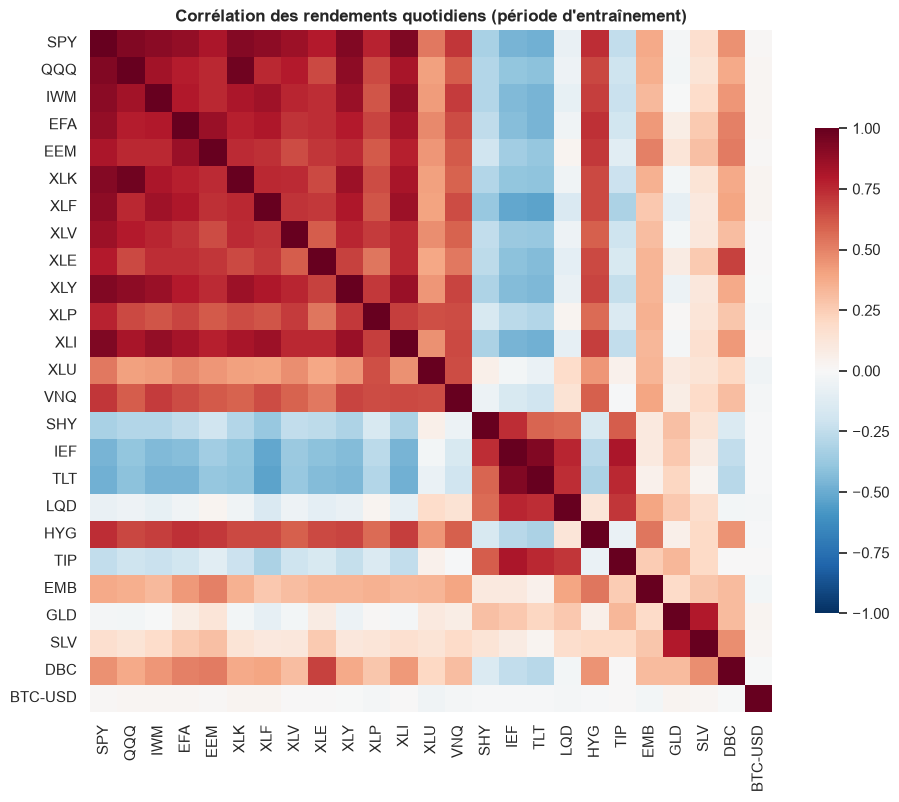

In [9]:
show = ["SPY", "EFA", "EEM", "TLT", "IEF", "SHY", "GLD", "VNQ", "DBC"]
norm = prices[show].dropna().pipe(lambda d: d / d.iloc[0] * 100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
norm.plot(ax=axes[0], lw=1.2)
axes[0].set_title("Performance cumulée (base 100)")
(prices["BTC-USD"].dropna() / prices["BTC-USD"].dropna().iloc[0] * 100).plot(ax=axes[1], logy=True, color="darkorange")
axes[1].set_title("Bitcoin (échelle logarithmique)")
for d in ("2020-03-23", "2022-10-12"):
    for ax in axes:
        ax.axvline(pd.Timestamp(d), color="red", ls="--", alpha=.5)
savefig("02_performances_cumulees")
plt.show()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(R_tr.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={"shrink": .7})
ax.set_title("Corrélation des rendements quotidiens (période d'entraînement)")
savefig("03_correlations")
plt.show()

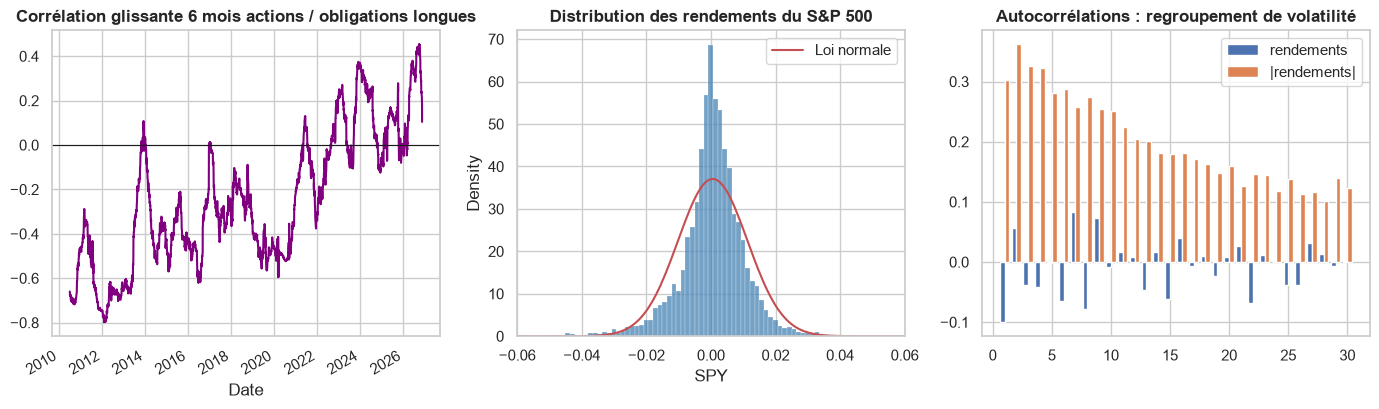

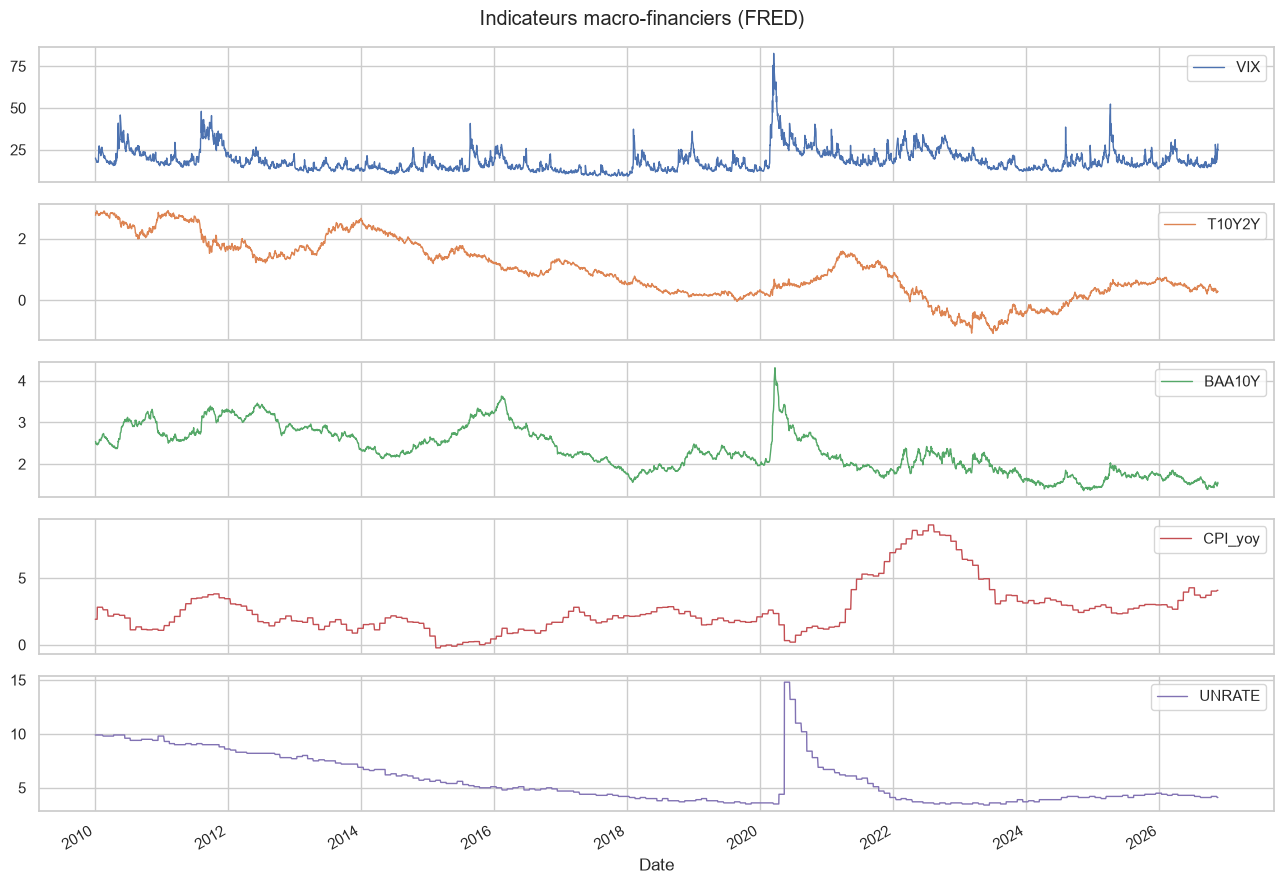

⏱ 2. Prétraitement et EDA : 5 s (cumul 0.1 min)


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
returns["SPY"].rolling(126).corr(returns["TLT"]).plot(ax=axes[0], color="purple")
axes[0].axhline(0, color="k", lw=.8)
axes[0].set_title("Corrélation glissante 6 mois actions / obligations longues")

r = returns["SPY"].dropna()
sns.histplot(r, bins=150, stat="density", ax=axes[1], color="steelblue")
xx = np.linspace(r.min(), r.max(), 300)
axes[1].plot(xx, stats.norm.pdf(xx, r.mean(), r.std()), "r", label="Loi normale")
axes[1].set_xlim(-0.06, 0.06)
axes[1].legend()
axes[1].set_title("Distribution des rendements du S&P 500")

lags = range(1, 31)
axes[2].bar([l - .2 for l in lags], [r.autocorr(l) for l in lags], width=.4, label="rendements")
axes[2].bar([l + .2 for l in lags], [r.abs().autocorr(l) for l in lags], width=.4, label="|rendements|")
axes[2].set_title("Autocorrélations : regroupement de volatilité")
axes[2].legend()
savefig("04_faits_stylises")
plt.show()

cols = [c for c in ["VIX", "T10Y2Y", "BAA10Y", "CPI_yoy", "UNRATE"] if c in macro]
macro[cols].plot(subplots=True, figsize=(13, 9), lw=1, title="Indicateurs macro-financiers (FRED)")
plt.tight_layout()
savefig("05_macro")
plt.show()
chrono("2. Prétraitement et EDA")

**Faits stylisés et conséquences pour la modélisation**
1. **Diversification instable** : la corrélation actions / obligations, négative pendant les années 2010, devient positive en 2022 (choc d'inflation). La covariance doit donc être réestimée en continu (fenêtre glissante d'un an).
2. **Queues épaisses** : voir ci-dessus.
3. **Regroupement de volatilité** : les rendements sont presque non autocorrélés, mais leurs valeurs absolues le sont fortement. Le **niveau de risque** est donc prévisible, beaucoup plus que la **direction** des prix. Cela justifie un agent Régime, et laisse attendre un pouvoir prédictif faible pour l'agent Prévision.
4. **Non-stationnarité des niveaux macro** : la courbe des taux s'est inversée de 2022 à 2024 (T10Y2Y < 0), un niveau jamais observé dans l'entraînement. Les modèles utiliseront de préférence des **variations** et des **logarithmes**, plus stables dans le temps.

## 3. Agent Profil – classification supervisée de l'aversion au risque

### 3.1 Problématique et formulation
À partir de la situation d'un ménage (âge, revenus, patrimoine, dettes, éducation, connaissances financières, comportements d'épargne), on cherche à estimer **sa capacité à supporter des pertes**. La cible vient d'une question réelle du SCF : le ménage est-il prêt à prendre des risques financiers ?

- `NOFINRISK = 1` (« aucun risque ») → classe **Prudent** (≈ 32 % des ménages) ;
- sinon → classe **Non prudent**.

C'est une **classification binaire** (cours 1). La version à 3 classes (Prudent / Équilibré / Dynamique) a été testée dans la version précédente du projet : la classe « Dynamique » ne représente que 5 % des ménages et n'est pas séparable avec ces variables (F1 macro plafonné à 0,50 quel que soit le modèle). Le passage Équilibré → Dynamique est donc décidé par un **questionnaire noté de 7 questions** (horizon, réaction à une baisse, perte acceptable…), comme dans les questionnaires réglementaires MiFID II.

**Décision finale** : profil retenu = le plus prudent entre la *tolérance déclarée* (questionnaire) et la *capacité estimée* (modèle ML). Toute divergence déclenche une alerte pour le conseiller.

**Piège de fuite propre au SCF** : chaque ménage apparaît sur **5 lignes quasi identiques** (imputation multiple des valeurs manquantes). Un découpage aléatoire ligne par ligne placerait des copies d'un même ménage dans l'entraînement et dans le test. Le découpage se fait donc **par ménage**.

In [11]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, RandomizedSearchCV, learning_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, f1_score, balanced_accuracy_score, precision_score, recall_score,
                             accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, ADASYN
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
from src.preprocessing import prepare_scf, Winsorizer, SignedLog, MONEY_FEATURES

X_p, y_p, groups_p, w_p, scf_report = prepare_scf(scf_raw)
num_p, cat_p = scf_report["variables_numeriques"], scf_report["variables_categorielles"]
print(f"{scf_report['lignes_finales']} lignes | {scf_report['menages_uniques']} ménages | "
      f"{len(num_p)} variables numériques + {len(cat_p)} catégorielles")
print("Répartition de la cible :", scf_report["repartition_cible"])

22975 lignes | 4595 ménages | 13 variables numériques + 42 catégorielles
Répartition de la cible : {'Non prudent': 0.682, 'Prudent': 0.318}


### 3.2 Découpage entraînement / validation / test (70 / 15 / 15) **avant** tout prétraitement
Méthode « *three-way holdout* » du cours : l'entraînement sert à ajuster les modèles, la validation à **choisir** un modèle et un seuil, et le test à mesurer une seule fois la performance du modèle choisi. Le découpage est stratifié sur la classe et fait **par ménage**.

In [12]:
hh = pd.DataFrame({"g": groups_p.values, "y": y_p.astype(str).values}).groupby("g")["y"].agg(lambda s: s.mode().iloc[0])
hh_train, hh_tmp = train_test_split(hh.index, test_size=0.30, stratify=hh.values, random_state=RANDOM_STATE)
hh_val, hh_test = train_test_split(hh_tmp, test_size=0.50, stratify=hh.loc[hh_tmp].values, random_state=RANDOM_STATE)
m_tr, m_va, m_te = (groups_p.isin(h).values for h in (hh_train, hh_val, hh_test))
assert not (set(hh_train) & set(hh_val) or set(hh_train) & set(hh_test) or set(hh_val) & set(hh_test))

# Codage : 0 = Prudent, 1 = Non prudent (ordre de PROFILE_ML_CLASSES, utilisé par l'agent)
CLS_TO_INT = {c: i for i, c in enumerate(PROFILE_ML_CLASSES)}
y_int = y_p.astype(str).map(CLS_TO_INT).astype(int)
Xp_tr, Xp_va, Xp_te = X_p[m_tr], X_p[m_va], X_p[m_te]
yp_tr, yp_va, yp_te = y_int[m_tr], y_int[m_va], y_int[m_te]
gp_tr = groups_p[m_tr]
pd.DataFrame({"lignes": [m_tr.sum(), m_va.sum(), m_te.sum()],
              "ménages": [len(hh_train), len(hh_val), len(hh_test)],
              "% Prudent": [(y == 0).mean() * 100 for y in (yp_tr, yp_va, yp_te)]},
             index=["entraînement", "validation", "test"])

,lignes,ménages,% Prudent
entraînement,16080,3216,31.7662
validation,3445,689,31.7852
test,3450,690,31.6812


### 3.3 Analyse exploratoire (entraînement uniquement)

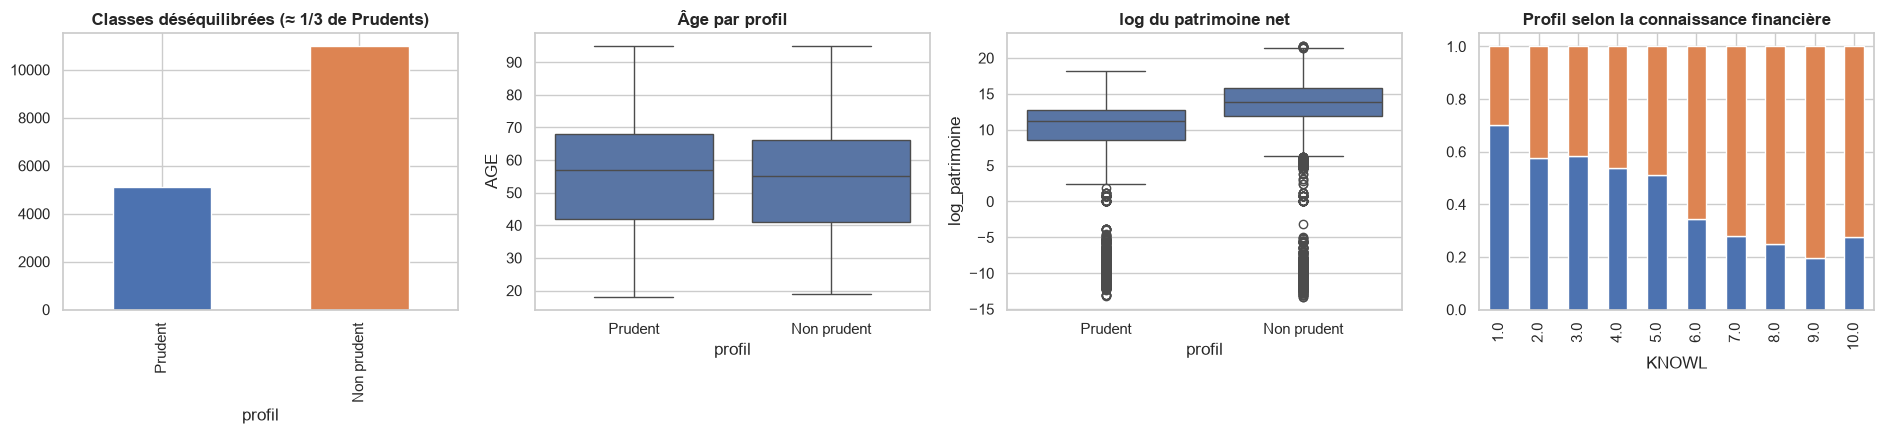

In [13]:
eda = Xp_tr.copy()
eda["profil"] = yp_tr.map({v: k for k, v in CLS_TO_INT.items()})
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
eda["profil"].value_counts().reindex(PROFILE_ML_CLASSES).plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Classes déséquilibrées (≈ 1/3 de Prudents)")
sns.boxplot(data=eda, x="profil", y="AGE", order=PROFILE_ML_CLASSES, ax=axes[1])
axes[1].set_title("Âge par profil")
eda["log_patrimoine"] = np.sign(eda["NETWORTH"]) * np.log1p(eda["NETWORTH"].abs())
sns.boxplot(data=eda, x="profil", y="log_patrimoine", order=PROFILE_ML_CLASSES, ax=axes[2])
axes[2].set_title("log du patrimoine net")
pd.crosstab(eda["KNOWL"], eda["profil"], normalize="index")[PROFILE_ML_CLASSES].plot.bar(stacked=True, ax=axes[3], legend=False)
axes[3].set_title("Profil selon la connaissance financière")
plt.tight_layout()
savefig("06_eda_profils")
plt.show()

**Lecture** : les Prudents sont plus âgés, nettement moins aisés et déclarent moins de connaissances financières. Les montants (revenu, patrimoine, dettes) sont **très asymétriques**, d'où une transformation logarithmique signée $\text{sign}(x)\ln(1+|x|)$. Les classes sont **déséquilibrées** : l'*accuracy* serait trompeuse (prédire toujours « Non prudent » donne déjà 68 %). On utilise l'**AUC ROC**, le **rappel**, la **précision** et le **F1**, comme le recommande le cours.

### 3.4 Pipeline de prétraitement (cours : imputation, standardisation, one-hot encoding)
- **Montants** : imputation par la médiane → log signé → standardisation.
- **Autres variables numériques** : imputation par la médiane → écrêtage aux quantiles 1 % / 99 % → standardisation.
- **Variables catégorielles** : imputation par la modalité la plus fréquente → encodage one-hot (modalités rares regroupées).

Toutes ces étapes sont **apprises sur l'entraînement** (médianes, quantiles, moyennes, écarts-types).

In [14]:
money_p = [c for c in MONEY_FEATURES if c in num_p]
other_p = [c for c in num_p if c not in money_p]
pre_profile = ColumnTransformer([
    ("montants", SkPipeline([("imp", SimpleImputer(strategy="median")), ("log", SignedLog()),
                             ("sc", StandardScaler())]), money_p),
    ("num", SkPipeline([("imp", SimpleImputer(strategy="median")), ("win", Winsorizer(0.01, 0.99)),
                        ("sc", StandardScaler())]), other_p),
    ("cat", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=20))]), cat_p),
])

### 3.5 Modèles comparés

| Modèle | Idée | Fonction de coût / principe |
|---|---|---|
| **Baseline** classe majoritaire | Niveau « sans apprentissage » | — |
| **Régression logistique** | $p(y=1\mid x)=\sigma(\beta_0+\sum_j\beta_j x_j)$ ; coefficients interprétables | Entropie croisée binaire (BCE) + pénalité $\lambda\lVert\beta\rVert_2^2$ (C = 1/λ) |
| **KNN** | Vote des k plus proches voisins | Distance euclidienne ; pas d'apprentissage |
| **SVM** (noyau RBF) | Frontière de marge maximale dans un espace transformé | Perte charnière + régularisation (C) |
| **Arbre de décision** | Questions successives sur les variables | Impureté de Gini |
| **Forêt aléatoire** | Moyenne d'arbres décorrélés (*bagging*) | Réduit la variance |
| **LightGBM, XGBoost, CatBoost** | Arbres ajoutés un à un pour corriger les erreurs (*boosting*) | Descente de gradient sur la BCE |
| **MLP** | Réseau de neurones à 2 couches cachées | BCE minimisée par **Adam** |

**Réglage des hyperparamètres** : recherche aléatoire (au plus `N_ITER` combinaisons) avec **validation croisée stratifiée par groupes** (ménages) sur l'entraînement, critère AUC ROC. Les modèles qui l'acceptent utilisent des **poids de classes équilibrés** ; KNN et MLP n'en acceptent pas et utilisent **SMOTE** (voir 3.6). La SVM, coûteuse (complexité au moins quadratique en n), est entraînée sur un sous-échantillon de 4 000 lignes.

**Règle de choix fixée à l'avance** : on retient le modèle de meilleure AUC de validation. Si la régression logistique est à moins de 0,005 de ce meilleur score, on la préfère (principe de parcimonie : c'est le modèle le plus simple et le plus explicable).

In [15]:
spw = float((yp_tr == 1).sum() / (yp_tr == 0).sum())   # poids de la classe 0 (Prudent) pour XGBoost


def profile_models():
    rs = RANDOM_STATE
    m = {
        "Baseline – classe majoritaire": ([("m", DummyClassifier(strategy="most_frequent"))], {}),
        "Régression logistique": ([("m", LogisticRegression(max_iter=3000, class_weight="balanced"))],
                                  {"m__C": [0.003, 0.01, 0.03, 0.1, 1]}),
        "KNN (+SMOTE)": ([("smote", SMOTE(random_state=rs)), ("m", KNeighborsClassifier())],
                         {"m__n_neighbors": [50, 100, 150, 250]}),
        "SVM (noyau RBF)": ([("m", SVC(probability=True, class_weight="balanced", random_state=rs))],
                            {"m__C": [0.1, 0.3, 1]}),
        "Arbre de décision": ([("m", DecisionTreeClassifier(class_weight="balanced", random_state=rs))],
                              {"m__max_depth": [3, 4, 6, 8], "m__min_samples_leaf": [20, 50, 100]}),
        "Forêt aléatoire": ([("m", RandomForestClassifier(200, class_weight="balanced_subsample", n_jobs=1, random_state=rs))],
                            {"m__max_depth": [8, 12, 16], "m__min_samples_leaf": [10, 20, 50]}),
        "LightGBM": ([("m", lgb.LGBMClassifier(n_estimators=300, class_weight="balanced", subsample=0.8, subsample_freq=1,
                                               colsample_bytree=0.8, verbose=-1, n_jobs=1, random_state=rs))],
                     {"m__learning_rate": [0.02, 0.05, 0.1], "m__num_leaves": [7, 15, 31], "m__min_child_samples": [20, 50]}),
        "XGBoost": ([("m", xgb.XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1 / spw,
                                             tree_method="hist", n_jobs=1, random_state=rs))],
                    {"m__learning_rate": [0.02, 0.05, 0.1], "m__max_depth": [2, 3, 5], "m__min_child_weight": [1, 10]}),
        "CatBoost": ([("m", cb.CatBoostClassifier(iterations=300, auto_class_weights="Balanced", verbose=0, thread_count=1,
                                                  allow_writing_files=False, random_seed=rs))],
                     {"m__learning_rate": [0.03, 0.1], "m__depth": [4, 6]}),
        "MLP (Adam)": ([("smote", SMOTE(random_state=rs)),
                        ("m", MLPClassifier((64, 32), solver="adam", early_stopping=True, max_iter=500, random_state=rs))],
                       {"m__alpha": [1e-3, 1e-2, 1e-1, 1.0]}),
    }
    return m


def eval_profile(model, X, y, threshold=0.5, sample_weight=None) -> dict:
    # Classe d'intérêt = Prudent (codée 0) : on prédit « Prudent » si P(Prudent) ≥ seuil
    p_prud = model.predict_proba(X)[:, 0]
    pred_prud = (p_prud >= threshold).astype(int)
    y_prud = (np.asarray(y) == 0).astype(int)
    sw = sample_weight
    return {"ROC-AUC": roc_auc_score(y_prud, p_prud, sample_weight=sw),
            "F1 macro": f1_score(y_prud, pred_prud, average="macro", sample_weight=sw),
            "Balanced acc.": balanced_accuracy_score(y_prud, pred_prud, sample_weight=sw),
            "Précision Prudent": precision_score(y_prud, pred_prud, sample_weight=sw, zero_division=0),
            "Rappel Prudent": recall_score(y_prud, pred_prud, sample_weight=sw),
            "Accuracy": accuracy_score(y_prud, pred_prud, sample_weight=sw)}


cv_p = StratifiedGroupKFold(n_splits=3 if QUICK_RUN else 5, shuffle=True, random_state=RANDOM_STATE)
sub = Xp_tr.sample(4000, random_state=RANDOM_STATE).index      # sous-échantillon pour la SVM
profile_fitted, rows = {}, {}
for name, (steps, grid) in profile_models().items():
    t0 = time.time()
    Xf, yf, gf = (Xp_tr.loc[sub], yp_tr.loc[sub], gp_tr.loc[sub]) if name.startswith("SVM") else (Xp_tr, yp_tr, gp_tr)
    pipe = Pipeline([("pre", pre_profile)] + steps)
    if grid:
        n_comb = int(np.prod([len(v) for v in grid.values()]))
        search = RandomizedSearchCV(pipe, grid, n_iter=min(N_ITER, n_comb), cv=cv_p, scoring="roc_auc",
                                    n_jobs=N_JOBS, random_state=RANDOM_STATE).fit(Xf, yf, groups=gf)
        best, cv_auc, params = search.best_estimator_, search.best_score_, search.best_params_
    else:
        best, cv_auc, params = pipe.fit(Xf, yf), 0.5, {}
    profile_fitted[name] = best
    rows[name] = {"AUC CV (train)": cv_auc, **eval_profile(best, Xp_va, yp_va), "Durée (s)": time.time() - t0,
                  "Hyperparamètres": {k.replace("m__", ""): v for k, v in params.items()}}
    print(f"✓ {name:<32} AUC validation = {rows[name]['ROC-AUC']:.4f}  ({time.time() - t0:.0f} s)")

profile_comparison = pd.DataFrame(rows).T.sort_values("ROC-AUC", ascending=False)
profile_comparison.to_csv(RESULTS_DIR / "agent_profil_comparaison_validation.csv")
RESULTS["profil_validation"] = profile_comparison.drop(columns="Hyperparamètres")
profile_comparison

✓ Baseline – classe majoritaire    AUC validation = 0.5000  (1 s)


✓ Régression logistique            AUC validation = 0.8598  (12 s)


✓ KNN (+SMOTE)                     AUC validation = 0.8493  (11 s)


✓ SVM (noyau RBF)                  AUC validation = 0.8526  (27 s)


✓ Arbre de décision                AUC validation = 0.8147  (15 s)


✓ Forêt aléatoire                  AUC validation = 0.8489  (40 s)


✓ LightGBM                         AUC validation = 0.8417  (23 s)


✓ XGBoost                          AUC validation = 0.8492  (30 s)


✓ CatBoost                         AUC validation = 0.8497  (29 s)


✓ MLP (Adam)                       AUC validation = 0.7870  (36 s)


,AUC CV (train),ROC-AUC,F1 macro,Balanced acc.,Précision Prudent,Rappel Prudent,Accuracy,Durée (s),Hyperparamètres
Régression logistique,0.8386,0.8598,0.7669,0.7913,0.6219,0.8128,0.7835,11.5849,{'C': 0.003}
SVM (noyau RBF),0.8419,0.8526,0.7633,0.7571,0.7042,0.6393,0.8000,26.9849,{'C': 0.3}
CatBoost,0.8392,0.8497,0.7456,0.7801,0.5835,0.8393,0.7585,28.8958,"{'learning_rate': 0.03, 'depth': 4}"
KNN (+SMOTE),0.8329,0.8493,0.7522,0.7834,0.5949,0.8301,0.7663,11.3599,{'n_neighbors': 250}
XGBoost,0.8368,0.8492,0.7558,0.7849,0.6017,0.8237,0.7707,30.2787,"{'min_child_weight': 10, 'max_depth': 5, 'lear..."
Forêt aléatoire,0.8387,0.8489,0.7541,0.7815,0.6020,0.8137,0.7698,39.8615,"{'min_samples_leaf': 20, 'max_depth': 12}"
LightGBM,0.8390,0.8417,0.7504,0.7693,0.6106,0.7662,0.7704,22.9275,"{'num_leaves': 31, 'min_child_samples': 50, 'l..."
Arbre de décision,0.7933,0.8147,0.7242,0.7517,0.5664,0.7826,0.7405,14.5838,"{'min_samples_leaf': 50, 'max_depth': 4}"
MLP (Adam),0.7912,0.7870,0.7020,0.7063,0.5793,0.6237,0.7364,35.7719,{'alpha': 1.0}
Baseline – classe majoritaire,0.5000,0.5000,0.4055,0.5000,0.0000,0.0000,0.6821,0.5900,{}


**Lecture** : tous les modèles appris battent largement la baseline (AUC 0,5). Les écarts entre les meilleurs modèles sont faibles (quelques millièmes d'AUC) : la relation entre situation financière et aversion au risque est **essentiellement monotone**, et un modèle linéaire la capte presque aussi bien que des ensembles d'arbres. Le MLP, plus flexible, est le moins bon : avec ~16 000 lignes bruitées, il souffre de **variance** (surapprentissage).

### 3.6 Classes déséquilibrées : poids de classes, SMOTE et ADASYN (cours 1)
Avec 1/3 de Prudents, un modèle non corrigé favorise la classe majoritaire et **rate des Prudents**, l'erreur la plus grave pour un conseiller.
- **Poids de classes** : chaque erreur sur la classe minoritaire compte davantage dans la fonction de coût.
- **SMOTE** : crée des exemples synthétiques de la classe minoritaire par interpolation entre un point et l'un de ses k voisins : $x_{new} = x_i + \lambda\,(x_{voisin} - x_i)$, avec $\lambda \sim U(0,1)$.
- **ADASYN** : variante de SMOTE qui génère davantage d'exemples là où la classe minoritaire est difficile à apprendre.

Le rééchantillonnage est placé dans un `imblearn.Pipeline` : il n'est appliqué **qu'aux plis d'entraînement**, jamais à la validation ni au test (sinon fuite de données). On compare les 4 stratégies sur la logistique et LightGBM, avec les hyperparamètres trouvés en 3.5.

In [16]:
def strip_weights(model):
    m = clone(model)
    if hasattr(m, "class_weight"):
        m.set_params(class_weight=None)
    return m


imb_rows = {}
for mname in ("Régression logistique", "LightGBM"):
    base_m = profile_fitted[mname].named_steps["m"]
    for strat, steps in (("aucune correction", [("m", strip_weights(base_m))]),
                         ("poids de classes", [("m", clone(base_m))]),
                         ("SMOTE", [("s", SMOTE(random_state=RANDOM_STATE)), ("m", strip_weights(base_m))]),
                         ("ADASYN", [("s", ADASYN(random_state=RANDOM_STATE)), ("m", strip_weights(base_m))])):
        p = Pipeline([("pre", pre_profile)] + steps).fit(Xp_tr, yp_tr)
        imb_rows[(mname, strat)] = eval_profile(p, Xp_va, yp_va)
imb_tab = pd.DataFrame(imb_rows).T
imb_tab.to_csv(RESULTS_DIR / "agent_profil_desequilibre.csv")
RESULTS["profil_desequilibre"] = imb_tab
imb_tab[["ROC-AUC", "Rappel Prudent", "Précision Prudent", "F1 macro", "Balanced acc."]]

ROC-AUC  Rappel Prudent  \
Régression logistique aucune correction   0.8596          0.5626   
                      poids de classes    0.8598          0.8128   
                      SMOTE               0.8592          0.8237   
                      ADASYN              0.8570          0.8283   
LightGBM              aucune correction   0.8429          0.6055   
                      poids de classes    0.8417          0.7662   
                      SMOTE               0.8441          0.7626   
                      ADASYN              0.8444          0.7397   

                                         Précision Prudent  F1 macro  \
Régression logistique aucune correction             0.7540    0.7539   
                      poids de classes              0.6219    0.7669   
                      SMOTE                         0.6251    0.7711   
                      ADASYN                        0.6095    0.7619   
LightGBM              aucune correction             0.7114    0.7550   
                      poids de classes              0.6106    0.7504   
                      SMOTE                         0.6236    0.7573   
                      ADASYN                        0.6240    0.7525   

                                         Balanced acc.  
Régression logistique aucune correction         0.7385  
                      poids de classes          0.7913  
                      SMOTE                     0.7968  
                      ADASYN                    0.7905  
LightGBM              aucune correction         0.7455  
                      poids de classes          0.7693  
                      SMOTE                     0.7740  
                      ADASYN                    0.7660

**Lecture** : les 4 stratégies donnent presque la **même AUC**, car l'AUC mesure la qualité du **classement** des clients, indépendamment du seuil. Ce qui change, c'est le compromis rappel / précision au seuil de 0,5 : sans correction, plus de 40 % des Prudents sont manqués ; avec les poids de classes, SMOTE ou ADASYN, le rappel des Prudents dépasse 75-80 %. Ces trois corrections ont un effet comparable à un simple **déplacement du seuil de décision** (3.8). On garde les poids de classes, la solution la plus simple, qui ne crée aucune donnée artificielle.

### 3.7 Choix du modèle (règle fixée en 3.5)

In [17]:
learned = profile_comparison.drop(index=[i for i in profile_comparison.index if i.startswith("Baseline")])
best_auc = learned["ROC-AUC"].max()
logit_auc = learned.loc["Régression logistique", "ROC-AUC"]
best_profile_name = "Régression logistique" if logit_auc >= best_auc - 0.005 else learned["ROC-AUC"].idxmax()
print(f"Meilleure AUC de validation : {best_auc:.4f} ({learned['ROC-AUC'].idxmax()}) | "
      f"logistique : {logit_auc:.4f}")
print("Modèle retenu pour l'agent Profil :", best_profile_name)

Meilleure AUC de validation : 0.8598 (Régression logistique) | logistique : 0.8598
Modèle retenu pour l'agent Profil : Régression logistique


### 3.8 Seuil de décision (choisi sur la validation)
Règle métier : ne pas repérer un client prudent est l'erreur la plus coûteuse. On exige un **rappel d'au moins 80 %** sur la classe Prudent, puis on maximise l'accuracy équilibrée.

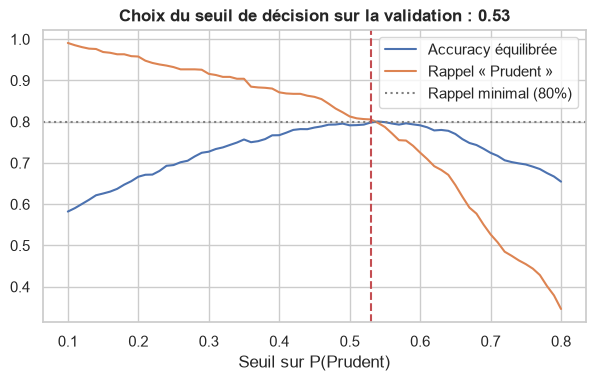

,seuil,rappel Prudent,précision Prudent,% clients classés Prudent,% non-prudents classés Prudent
rappel visé,,,,,
0.8000,0.5300,0.8055,0.6419,0.3988,0.2094
0.8500,0.4600,0.8548,0.5894,0.4610,0.2774
0.9000,0.3500,0.9041,0.5191,0.5536,0.3902
0.9500,0.2000,0.9580,0.4168,0.7306,0.6247


In [18]:
p_val = profile_fitted[best_profile_name].predict_proba(Xp_va)[:, 0]
yv_prud = (yp_va.values == 0)
grid_t = np.round(np.arange(0.10, 0.81, 0.01), 2)
bal_t = np.array([balanced_accuracy_score(yv_prud, p_val >= t) for t in grid_t])
rec_t = np.array([recall_score(yv_prud, p_val >= t) for t in grid_t])
ok = rec_t >= PRUDENT_RECALL_MIN
THRESH = float(grid_t[ok][np.argmax(bal_t[ok])]) if ok.any() else float(grid_t[np.argmax(rec_t)])
plt.figure(figsize=(7, 3.8))
plt.plot(grid_t, bal_t, label="Accuracy équilibrée")
plt.plot(grid_t, rec_t, label="Rappel « Prudent »")
plt.axhline(PRUDENT_RECALL_MIN, color="grey", ls=":", label=f"Rappel minimal ({PRUDENT_RECALL_MIN:.0%})")
plt.axvline(THRESH, color="r", ls="--")
plt.xlabel("Seuil sur P(Prudent)")
plt.legend()
plt.title(f"Choix du seuil de décision sur la validation : {THRESH:.2f}")
savefig("07b_profil_seuil")
plt.show()

# Compromis : que coûterait un rappel plus élevé ?
rows_t = []
for target in (0.80, 0.85, 0.90, 0.95):
    t = grid_t[rec_t >= target].max()
    pred = p_val >= t
    rows_t.append({"rappel visé": target, "seuil": t, "rappel Prudent": recall_score(yv_prud, pred),
                   "précision Prudent": precision_score(yv_prud, pred), "% clients classés Prudent": pred.mean(),
                   "% non-prudents classés Prudent": pred[~yv_prud].mean()})
display(pd.DataFrame(rows_t).set_index("rappel visé"))

**Lecture du compromis** : exiger 90 % ou 95 % de rappel ferait classer « Prudent » plus de la moitié des clients (alors qu'ils ne sont qu'environ un tiers) : le modèle perdrait son pouvoir de discrimination et proposerait des portefeuilles trop défensifs à de nombreux clients. Le seuil de 80 % est conservé. Le modèle n'est d'ailleurs qu'une des deux sécurités : le questionnaire déclaratif et la validation par le conseiller complètent le dispositif.

### 3.9 Diagnostic biais / variance : courbe d'apprentissage (cours 1)
On trace l'AUC sur l'entraînement ($J_{train}$) et en validation croisée ($J_{cv}$) quand la taille de l'entraînement augmente.
- Les deux courbes basses et proches → **biais élevé** (sous-apprentissage) : il faudrait un modèle plus riche ou de meilleures variables.
- Un grand écart entre les deux → **variance élevée** (surapprentissage) : il faudrait plus de données ou plus de régularisation.

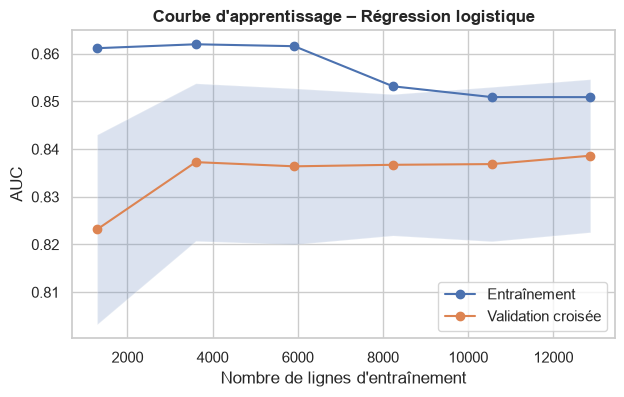

Écart final entraînement – validation : 0.012


In [19]:
sizes, sc_tr, sc_cv = learning_curve(clone(profile_fitted[best_profile_name]), Xp_tr, yp_tr, groups=gp_tr, cv=cv_p,
                                     train_sizes=np.linspace(0.1, 1.0, 4 if QUICK_RUN else 6),
                                     scoring="roc_auc", n_jobs=N_JOBS)
plt.figure(figsize=(7, 4))
plt.plot(sizes, sc_tr.mean(1), "o-", label="Entraînement")
plt.plot(sizes, sc_cv.mean(1), "o-", label="Validation croisée")
plt.fill_between(sizes, sc_cv.mean(1) - sc_cv.std(1), sc_cv.mean(1) + sc_cv.std(1), alpha=.2)
plt.xlabel("Nombre de lignes d'entraînement")
plt.ylabel("AUC")
plt.legend()
plt.title(f"Courbe d'apprentissage – {best_profile_name}")
savefig("07c_profil_courbe_apprentissage")
plt.show()
print(f"Écart final entraînement – validation : {sc_tr.mean(1)[-1] - sc_cv.mean(1)[-1]:.3f}")

### 3.10 Évaluation unique sur le test
Étape 4 de la méthode du cours : on ré-entraîne le modèle retenu sur **entraînement + validation**, avec les hyperparamètres choisis, puis on l'évalue **une seule fois** sur le test. La ligne « pondéré WGT » applique les poids d'enquête du SCF, qui rendent l'échantillon représentatif de la population américaine.

,ROC-AUC,F1 macro,Balanced acc.,Précision Prudent,Rappel Prudent,Accuracy
"Régression logistique (seuil 0,5)",0.8667,0.7728,0.8005,0.6238,0.8344,0.7881
Régression logistique (seuil 0.53),0.8667,0.7761,0.7969,0.6393,0.8042,0.7942
"Régression logistique (seuil 0.53, pondéré WGT)",0.8232,0.7219,0.7447,0.5896,0.8035,0.7282
Baseline – classe majoritaire,0.5000,0.4059,0.5000,0.0000,0.0000,0.6832


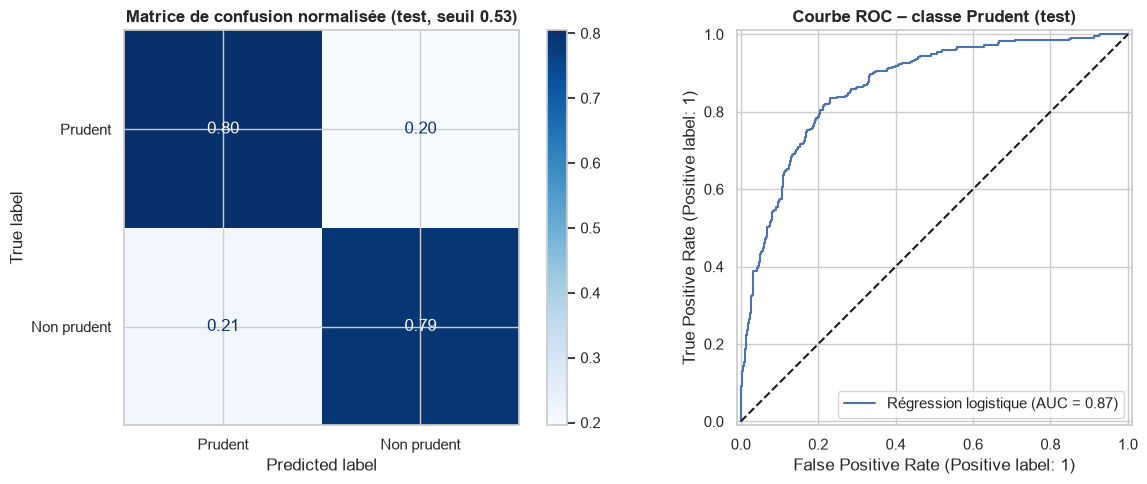

In [20]:
best_profile = clone(profile_fitted[best_profile_name]).fit(pd.concat([Xp_tr, Xp_va]), pd.concat([yp_tr, yp_va]))
profile_test = pd.DataFrame({
    f"{best_profile_name} (seuil 0,5)": eval_profile(best_profile, Xp_te, yp_te),
    f"{best_profile_name} (seuil {THRESH:.2f})": eval_profile(best_profile, Xp_te, yp_te, THRESH),
    f"{best_profile_name} (seuil {THRESH:.2f}, pondéré WGT)": eval_profile(best_profile, Xp_te, yp_te, THRESH,
                                                                           w_p[m_te].values),
    "Baseline – classe majoritaire": eval_profile(profile_fitted["Baseline – classe majoritaire"], Xp_te, yp_te),
}).T
profile_test.to_csv(RESULTS_DIR / "agent_profil_test.csv")
RESULTS["profil_test"] = profile_test
display(profile_test)

p_te_prud = best_profile.predict_proba(Xp_te)[:, 0]
pred_te_p = np.where(p_te_prud >= THRESH, 0, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(yp_te, pred_te_p, display_labels=PROFILE_ML_CLASSES, normalize="true",
                                        cmap="Blues", ax=axes[0], values_format=".2f")
axes[0].set_title(f"Matrice de confusion normalisée (test, seuil {THRESH:.2f})")
RocCurveDisplay.from_predictions((yp_te == 0).astype(int), p_te_prud, name=best_profile_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Courbe ROC – classe Prudent (test)")
plt.tight_layout()
savefig("07_profil_confusion_roc")
plt.show()

### 3.11 Validation externe sur une autre vague de l'enquête (SCF 2019)
Test plus exigeant : le modèle entraîné sur 2022, **sans ré-entraînement ni nouveau seuil**, est appliqué aux ménages de l'enquête **2019** (échantillon indépendant, interrogé avant le COVID). Les montants de 2019 sont convertis en dollars de 2022 avec l'indice des prix (CPI) de la FRED.

In [21]:
try:
    scf_ext = dl.download_scf(year=SCF_EXTERNAL_YEAR)
except Exception as exc:
    scf_ext = None
    print("⚠ SCF 2019 indisponible, validation externe ignorée :", exc)
if scf_ext is not None:
    X_ext, y_ext, g_ext, w_ext, rep_ext = prepare_scf(scf_ext)
    cpi = fred_raw["CPIAUCSL"].dropna()
    infl = cpi.loc[str(SCF_YEAR)].mean() / cpi.loc[str(SCF_EXTERNAL_YEAR)].mean()
    for c in [c for c in MONEY_FEATURES if c in X_ext.columns]:
        X_ext[c] = X_ext[c] * infl
    X_ext = X_ext.reindex(columns=X_p.columns)
    y_ext_int = y_ext.astype(str).map(CLS_TO_INT).astype(int)
    profil_externe = pd.DataFrame({
        f"Test interne – SCF {SCF_YEAR}": eval_profile(best_profile, Xp_te, yp_te, THRESH),
        f"Validation externe – SCF {SCF_EXTERNAL_YEAR}": eval_profile(best_profile, X_ext, y_ext_int, THRESH),
        f"Validation externe – SCF {SCF_EXTERNAL_YEAR} (pondéré WGT)": eval_profile(best_profile, X_ext, y_ext_int, THRESH,
                                                                                     w_ext.values),
    }).T
    profil_externe.to_csv(RESULTS_DIR / "agent_profil_validation_externe.csv")
    RESULTS["profil_externe"] = profil_externe
    display(profil_externe)
chrono("3. Agent Profil (modèles, test, validation externe)")

[SCF 2019] cache chargé : (28885, 362)


,ROC-AUC,F1 macro,Balanced acc.,Précision Prudent,Rappel Prudent,Accuracy
Test interne – SCF 2022,0.8667,0.7761,0.7969,0.6393,0.8042,0.7942
Validation externe – SCF 2019,0.8435,0.7458,0.7611,0.6109,0.7404,0.7687
Validation externe – SCF 2019 (pondéré WGT),0.8120,0.7217,0.7335,0.6218,0.7693,0.7258


⏱ 3. Agent Profil (modèles, test, validation externe) : 245 s (cumul 4.2 min)


### 3.12 Interprétabilité de l'agent Profil (cours 1)
1. **Interprétabilité intrinsèque** : les coefficients de la régression logistique. Un coefficient $\beta_j > 0$ augmente le log-odds de la classe modélisée.
2. **Explicabilité globale** : importance par permutation (baisse de l'AUC quand on mélange une variable) et valeurs SHAP moyennes.
3. **Explicabilité locale** : décomposition SHAP d'une prédiction individuelle, $\text{prédiction}_i = \text{valeur de base} + \sum_j \text{contribution}_j$. C'est elle qui est affichée au client dans l'application (« pourquoi ce profil ? »).
4. **Analyse des erreurs** par tranche d'âge.

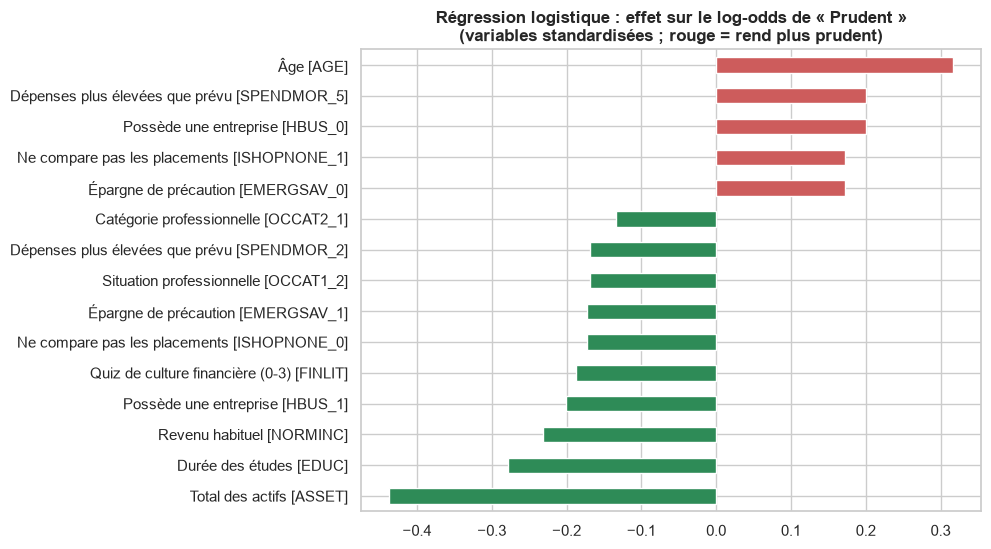

In [22]:
from src.explain import make_explainer, shap_values, global_importance, local_explanation, original_name

logit_pipe = profile_fitted["Régression logistique"]
names = logit_pipe.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(-logit_pipe.named_steps["m"].coef_[0], index=names)   # signe inversé : effet sur P(Prudent)
coefs.index = [f"{SCF_LABELS.get(original_name(n, list(X_p.columns)), n)} [{n.split('__', 1)[-1]}]" for n in coefs.index]
top_coef = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
top_coef.sort_values().plot.barh(figsize=(8, 6), color=np.where(top_coef.sort_values() > 0, "indianred", "seagreen"))
plt.title("Régression logistique : effet sur le log-odds de « Prudent »\n(variables standardisées ; rouge = rend plus prudent)")
savefig("08a_profil_coefficients")
plt.show()

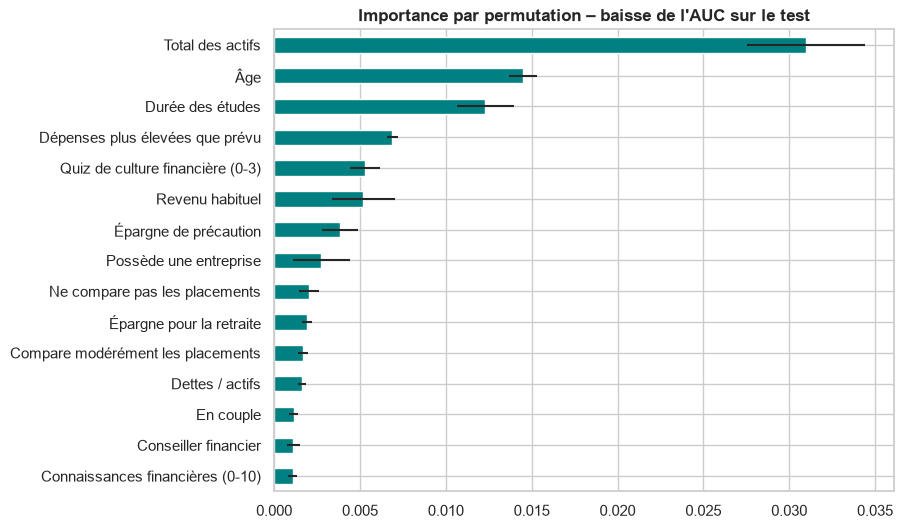

In [23]:
pi = permutation_importance(best_profile, Xp_te, yp_te, scoring="roc_auc", n_repeats=3 if QUICK_RUN else 10,
                            random_state=RANDOM_STATE, n_jobs=N_JOBS)
pi_profile = pd.DataFrame({"importance": pi.importances_mean, "écart-type": pi.importances_std},
                          index=[SCF_LABELS.get(c, c) for c in Xp_te.columns]).sort_values("importance")
pi_profile.tail(15).plot.barh(y="importance", xerr="écart-type", legend=False, figsize=(8, 6), color="teal")
plt.title("Importance par permutation – baisse de l'AUC sur le test")
savefig("08_profil_permutation")
plt.show()
pi_profile.sort_values("importance", ascending=False).to_csv(RESULTS_DIR / "agent_profil_importance_permutation.csv")

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


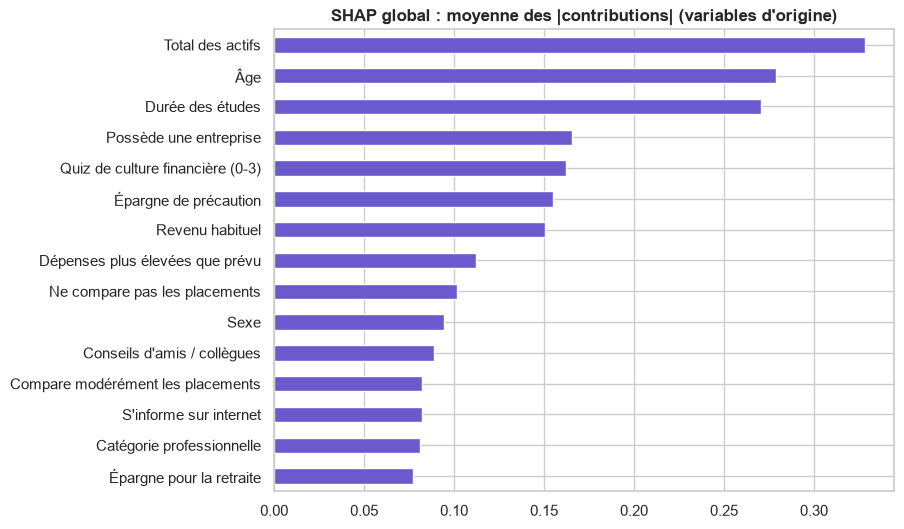

Variables les plus influentes (SHAP global) :
Total des actifs                   0.3280
Âge                                0.2790
Durée des études                   0.2700
Possède une entreprise             0.1660
Quiz de culture financière (0-3)   0.1620
Épargne de précaution              0.1550
Revenu habituel                    0.1500
Dépenses plus élevées que prévu    0.1120


In [24]:
explainer_p = make_explainer(best_profile, Xp_tr)
X_shap = Xp_te.sample(300 if QUICK_RUN else 1500, random_state=RANDOM_STATE)
sv_p = shap_values(best_profile, explainer_p, X_shap, class_idx=0)    # contributions au log-odds de « Prudent »
imp = global_importance(sv_p).head(15).rename(index=lambda c: SCF_LABELS.get(c, c))
imp.sort_values().plot.barh(figsize=(8, 6), color="slateblue")
plt.title("SHAP global : moyenne des |contributions| (variables d'origine)")
savefig("09_profil_shap_global")
plt.show()
print("Variables les plus influentes (SHAP global) :")
print(imp.head(8).round(3).to_string())

**Explication locale de deux ménages du test** : un ménage classé Prudent et un ménage classé Non prudent. Barres rouges : la variable pousse vers « Prudent » ; barres vertes : elle en éloigne.

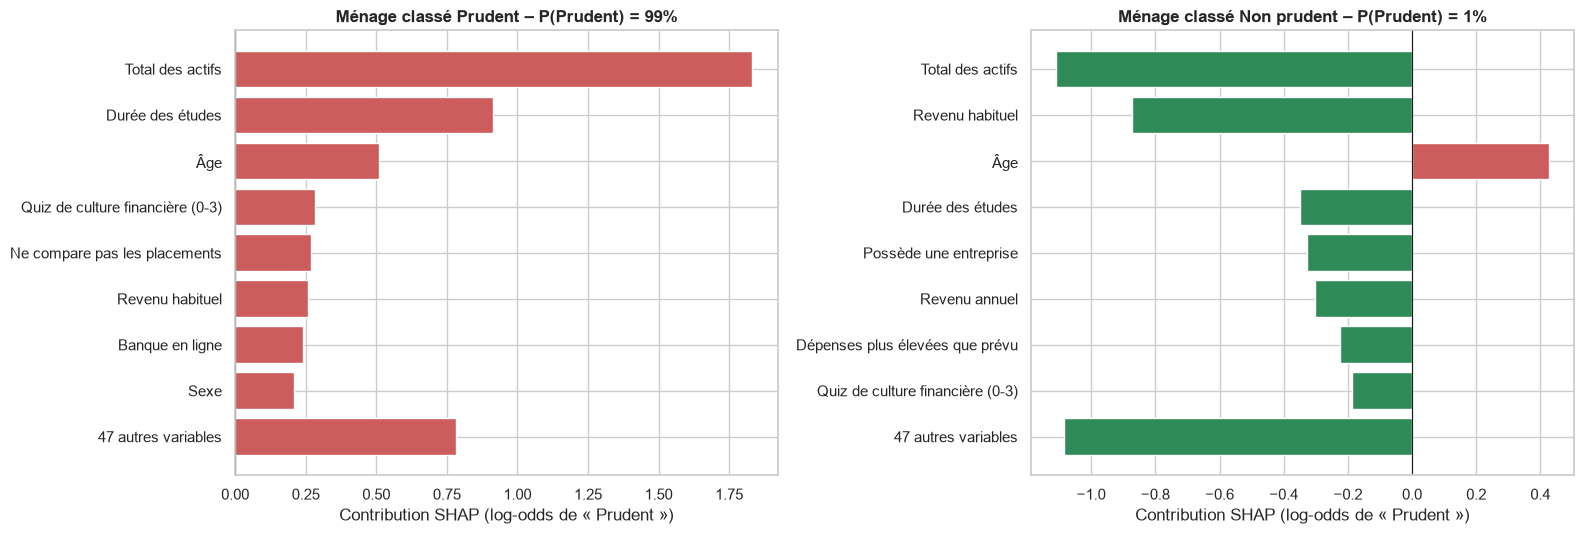

In [25]:
p_all = best_profile.predict_proba(Xp_te)[:, 0]
exemples = {"Ménage classé Prudent": Xp_te.index[np.argmax(p_all)],
            "Ménage classé Non prudent": Xp_te.index[np.argmin(p_all)]}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (titre, idx) in zip(axes, exemples.items()):
    row = Xp_te.loc[[idx]]
    s = shap_values(best_profile, explainer_p, row, class_idx=0).iloc[0]
    loc = local_explanation(s, row.iloc[0], labels=SCF_LABELS, top=8)
    loc = loc.iloc[::-1]
    ax.barh(loc["libellé"], loc["contribution"], color=np.where(loc["contribution"] > 0, "indianred", "seagreen"))
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{titre} – P(Prudent) = {best_profile.predict_proba(row)[0, 0]:.0%}")
    ax.set_xlabel("Contribution SHAP (log-odds de « Prudent »)")
plt.tight_layout()
savefig("09b_profil_shap_local")
plt.show()

In [26]:
err = pd.DataFrame({"age": Xp_te["AGE"], "vrai": yp_te, "prédit": pred_te_p})
err["tranche d'âge"] = pd.cut(err["age"], [0, 35, 50, 65, 120], labels=["<35", "35-50", "50-65", "65+"])
err_tab = err.groupby("tranche d'âge", observed=True).apply(lambda g: pd.Series({
    "n": len(g), "% Prudent réel": (g["vrai"] == 0).mean(),
    "rappel Prudent": recall_score(g["vrai"] == 0, g["prédit"] == 0),
    "F1 macro": f1_score(g["vrai"], g["prédit"], average="macro")}))
display(err_tab)

# Bundle de l'agent Profil, utilisé par l'orchestrateur (section 6) et l'application
profile_bundle = {"pipeline": best_profile, "num": num_p, "cat": cat_p, "classes": PROFILE_ML_CLASSES,
                  "mode": PROFILE_TARGET_MODE, "threshold": THRESH,
                  "defaults": {**Xp_tr[num_p].median().to_dict(), **{c: Xp_tr[c].mode().iloc[0] for c in cat_p}},
                  "model_name": best_profile_name, "background": Xp_tr.sample(200, random_state=RANDOM_STATE)}
chrono("3. Agent Profil (interprétabilité)")

,n,% Prudent réel,rappel Prudent,F1 macro
tranche d'âge,,,,
<35,500.0000,0.3200,0.6687,0.7083
35-50,880.0000,0.3295,0.8276,0.7927
50-65,"1,115.0000",0.2646,0.7763,0.7773
65+,955.0000,0.3644,0.8707,0.7854


⏱ 3. Agent Profil (interprétabilité) : 10 s (cumul 4.3 min)


**Lecture** : les variables les plus influentes (SHAP global) sont le **total des actifs**, l'**âge**, la **durée des études**, le fait de **posséder une entreprise**, la **culture financière** (quiz), l'**épargne de précaution** et le **revenu**. Un patrimoine et un revenu faibles, moins d'études et moins de culture financière rendent plus prudent. C'est cohérent avec la notion de **capacité à supporter des pertes** : un ménage peu aisé n'a pas de marge pour absorber une baisse de ses placements. **Analyse des erreurs** : le rappel des Prudents est nettement plus faible chez les **moins de 35 ans** : les jeunes prudents ont souvent une situation financière modeste mais « normale » pour leur âge, et le modèle les distingue mal des jeunes non prudents. C'est une raison supplémentaire de croiser le modèle avec le questionnaire déclaratif. La tolérance au risque reste en partie psychologique et n'est qu'en partie expliquée par ces variables : dans l'application, la prédiction est donc **proposée** au conseiller, qui peut la corriger (principe de l'humain dans la boucle).

## 4. Agent Prévision – apprentissage supervisé sur données temporelles

### 4.1 Formulation (cours 2, « cas des données temporelles »)
Pour chaque actif *i* et chaque date *t*, on prédit son **rendement excédentaire futur** sur un mois :

$$y_{i,t} = r_{i,\,t\to t+H} \;-\; \frac{1}{N_t}\sum_{j} r_{j,\,t\to t+H}$$

C'est une **régression**. On retire la moyenne de tous les actifs à la même date : l'effet « marché » commun disparaît et seul compte le **classement relatif**, l'information utile pour choisir *entre* les actifs.

Les données sont préparées par **fenêtre glissante** (cours 2) : à chaque date, les variables résument le passé observé (*lookback*), et la cible porte sur l'horizon futur (*forecast horizon*).

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from src.features import (compute_asset_features, compute_market_features, sample_dates, temporal_split,
                          ASSET_NUM_FEATURES, MACRO_FEATURES, CAT_FEATURES, REGIME_FEATURES)
from src.temporal import (window_table, TemporalCV, describe_splits, regression_metrics, information_coefficient,
                          newey_west_tstat, quintile_spread, forecast_report, evaluate_three_ways,
                          loss_by_date, diebold_mariano, dm_table, H_STEPS)
from src.pca_analysis import kmo, bartlett_sphericity, ACP

panel = compute_asset_features(prices, macro)
FEATS = ASSET_NUM_FEATURES + [c for c in MACRO_FEATURES if c in panel.columns] + CAT_FEATURES
NUM_F = [c for c in FEATS if c not in CAT_FEATURES]
panel.to_csv(DATA_PROC / "panel_features.csv.gz", compression="gzip")
print("Panel (date × actif) :", panel.shape)
window_table(lookback=252, horizon=HORIZON, stride=SAMPLE_EVERY, input_size=len(FEATS))

Panel (date × actif) : (98716, 34)


,Définition,Valeur dans le projet
Terme,,
Lookback (L),Nombre de pas de temps passés utilisés en entrée,252 jours de bourse (variable la plus longue :...
Forecast horizon (H),Nombre de pas de temps futurs à prédire,"21 jours de bourse, méthode directe à H (on pr..."
Stride (S),Décalage de la fenêtre entre deux échantillons,5 jours (un échantillon par semaine)
Input size,Nombre de variables (features) par pas de temps,31
Chevauchement,Nombre d'échantillons dont les cibles se recou...,⌈H/S⌉ − 1 = 4 (corrigé par Newey-West et Diebo...


**Variables d'entrée** (toutes calculées avec l'information disponible en *t*) :

| Famille | Variables |
|---|---|
| Momentum | rendements passés à 5 j, 1, 3, 6 et 12 mois ; momentum 12-1 (12 mois sauf le dernier) |
| Risque | volatilités à 1 et 3 mois, leur rapport, drawdown sur 1 an, asymétrie |
| Tendance | écarts aux moyennes mobiles 50 et 200 jours, RSI |
| Lien au marché | bêta et corrélation au S&P 500 sur 3 mois |
| Position relative | rangs transversaux du momentum et de la volatilité |
| Macro (FRED, décalée) | VIX et sa variation, pente de courbe, spread de crédit et sa variation, variation du taux 10 ans, inflation, chômage, production industrielle |
| Catégorielle | classe d'actifs (one-hot) |

**Choix du stride S = 5 jours** : avec S = 1, deux échantillons consécutifs auraient 20 jours de cible en commun (quasi-doublons) ; avec S = 21, il resterait trop peu de dates (≈ 110 en entraînement). Le chevauchement résiduel (4 échantillons) est corrigé dans les statistiques de test (Newey-West, Diebold-Mariano).

### 4.2 Découpage temporel purgé (avant tout prétraitement)
- **Entraînement** : 2011 → 2019 | **Validation** : 2020-2021 (choc COVID) | **Test** : 2022 → fin (inflation, hausse des taux).
- **Purge / embargo de 35 jours** avant chaque frontière : la cible d'une observation du 20 décembre 2019 dépend des prix de janvier 2020 (validation). Elle est supprimée, sinon le modèle apprendrait sur des rendements de la validation.
- Aucun mélange aléatoire : on ne prédit jamais le passé avec le futur.

In [28]:
panel_s = sample_dates(panel).dropna(subset=["target_reg"])
tr, va, te = temporal_split(panel_s)
for nm, d in (("entraînement", tr), ("validation", va), ("test", te)):
    dd = d.index.get_level_values("date")
    print(f"{nm:<13}: {dd.min().date()} → {dd.max().date()} | {len(d):>6} obs | {dd.nunique():>4} dates")
gap = va.index.get_level_values("date").min() - tr.index.get_level_values("date").max()
assert gap.days >= EMBARGO_DAYS
print(f"Écart entraînement → validation : {gap.days} jours (≥ embargo de {EMBARGO_DAYS} jours)")
d_tr = tr.index.get_level_values("date")
print(f"Écart-type de la cible (entraînement) : {tr['target_reg'].std():.4f} soit ±{tr['target_reg'].std():.1%} par mois")

entraînement : 2011-01-03 → 2019-11-26 |  10988 obs |  449 dates
validation   : 2020-01-03 → 2021-11-19 |   2400 obs |   96 dates
test         : 2022-01-04 → 2026-10-16 |   6025 obs |  241 dates
Écart entraînement → validation : 38 jours (≥ embargo de 35 jours)
Écart-type de la cible (entraînement) : 0.0511 soit ±5.1% par mois


### 4.3 Analyse exploratoire du pouvoir prédictif (entraînement)
Le **coefficient d'information (IC)** d'une variable est la corrélation de rang (Spearman) entre cette variable et le rendement futur, calculée date par date puis moyennée. En gestion d'actifs, un IC de 0,03 à 0,05 **stable** est déjà considéré comme exploitable.

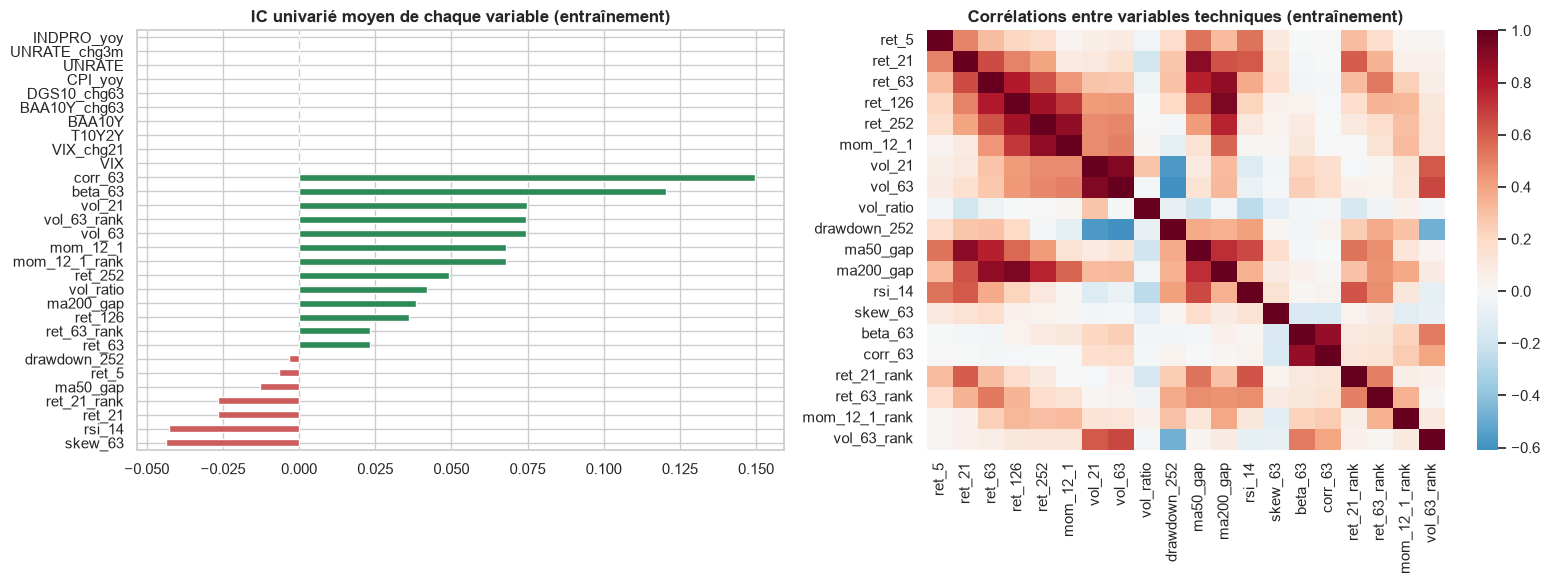

IC univariés les plus forts (en valeur absolue) :
corr_63         0.1500
beta_63         0.1210
vol_21          0.0750
vol_63          0.0740
vol_63_rank     0.0740
mom_12_1_rank   0.0680
Médiane des |IC| : 0.042


In [29]:
ic_uni = pd.Series({f: information_coefficient(tr[f], tr["fwd_ret"]).mean() for f in NUM_F}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ic_uni.plot.barh(ax=axes[0], color=np.where(ic_uni > 0, "seagreen", "indianred"))
axes[0].set_title("IC univarié moyen de chaque variable (entraînement)")
sns.heatmap(tr[ASSET_NUM_FEATURES].corr(), cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Corrélations entre variables techniques (entraînement)")
plt.tight_layout()
savefig("10_prevision_ic_univarie")
plt.show()
print("IC univariés les plus forts (en valeur absolue) :")
print(ic_uni.reindex(ic_uni.abs().sort_values(ascending=False).index).head(6).round(3).to_string())
print(f"Médiane des |IC| : {ic_uni.abs().median():.3f}")

**Lecture** : la plupart des IC univariés sont faibles (médiane de |IC| ≈ 0,04), ce qui est **normal en finance**, les marchés étant proches de l'efficience. Les variables les plus « prédictives » (corrélation et bêta au S&P 500, volatilité, toutes de signe positif) repèrent en réalité **les actions par opposition aux obligations** : sur 2011-2019, marché haussier, les actifs risqués ont nettement battu les actifs défensifs. Il s'agit d'une **prime de classe d'actifs propre à la période d'entraînement**, pas d'un signal de sélection garanti : si le contexte change (2022 : actions et obligations baissent ensemble), ce signal peut disparaître. C'est un risque de **dérive des données** (*data drift*, cours 1). Les variables techniques sont par ailleurs **fortement corrélées entre elles** (différents horizons de momentum, différentes mesures de volatilité). D'où deux conséquences : il faudra des modèles **régularisés**, et une **réduction de dimension** est envisageable.

### 4.4 Réduction de dimension : Analyse en Composantes Principales (cours 2)
L'ACP remplace des variables corrélées par de nouvelles variables **non corrélées**, les composantes principales $F_k = X V_k$, où les $V_k$ sont les vecteurs propres de la matrice de variance-covariance $S = \frac{1}{n-1}X^tX$ des variables standardisées, rangés par valeur propre $\lambda_k$ décroissante. La part de variance expliquée par $F_k$ vaut $\lambda_k / \sum_j \lambda_j$.

**Vérification préalable** (N.B. du cours) : l'ACP n'a d'intérêt que si les variables sont corrélées → indice **KMO ≥ 0,6** et **test de sphéricité de Bartlett** significatif. Tout est calculé sur l'entraînement.

In [30]:
X_acp = tr[ASSET_NUM_FEATURES].dropna()
X_acp = X_acp.clip(X_acp.quantile(0.005), X_acp.quantile(0.995), axis=1)
kmo_global, kmo_var = kmo(X_acp)
bart = bartlett_sphericity(X_acp)
print(f"KMO global = {kmo_global:.3f}  (≥ 0,6 : ACP justifiée)")
print(f"Bartlett : χ² = {bart['chi2']:,.0f}, ddl = {bart['ddl']}, p-valeur = {bart['p-valeur']:.2g}")
acp = ACP().fit(X_acp)
var_tab = acp.variance_table()
crit = acp.n_components()
display(var_tab.head(10))
print("Nombre de facteurs selon chaque critère :", crit)

KMO global = 0.746  (≥ 0,6 : ACP justifiée)
Bartlett : χ² = 254,994, ddl = 190, p-valeur = 0


,valeur propre,% variance,% cumulé
F1,6.3848,31.9239,31.9239
F2,3.8072,19.0361,50.9601
F3,2.3144,11.5721,62.5321
F4,1.8592,9.2960,71.8281
F5,1.0622,5.3111,77.1392
F6,0.9550,4.7751,81.9143
F7,0.8295,4.1475,86.0619
F8,0.6276,3.1381,89.2000
F9,0.5284,2.6421,91.8421
F10,0.3727,1.8633,93.7054


Nombre de facteurs selon chaque critère : {'Kaiser (λ ≥ 1)': 5, '80 % de variance': 6, '90 % de variance': 9, 'Coude': 2}


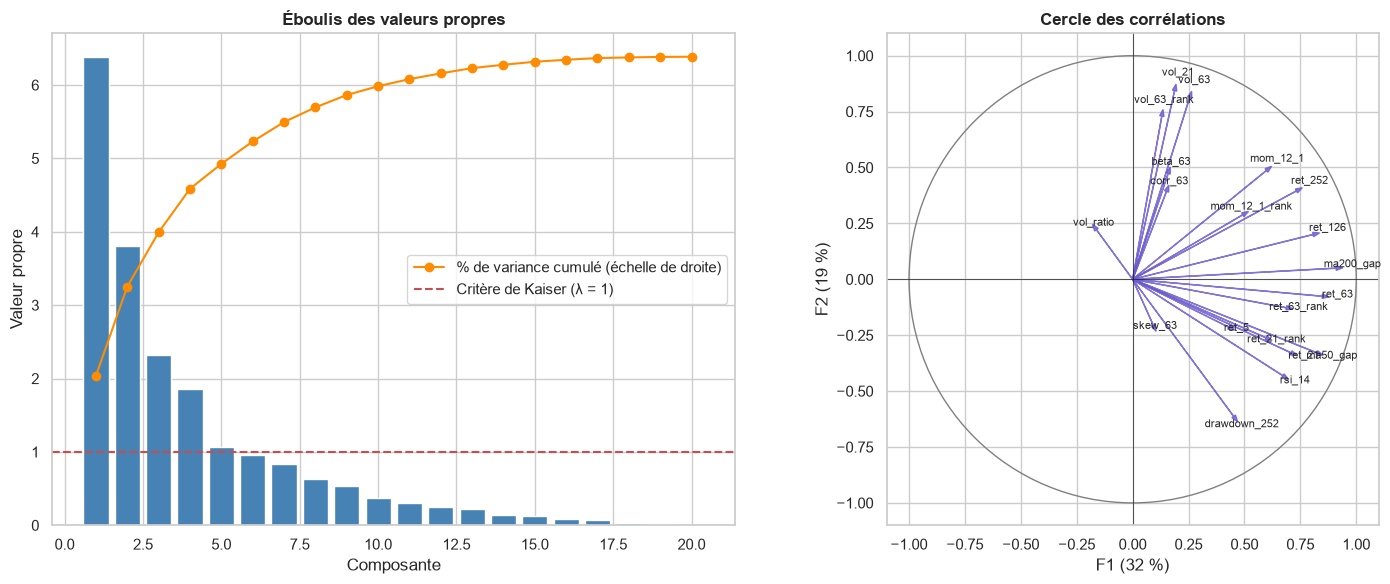

,F1,F2,F3,F4
ret_5,0.430000,-0.210000,-0.340000,-0.150000
ret_21,0.710000,-0.330000,-0.420000,-0.180000
ret_63,0.850000,-0.080000,0.090000,-0.120000
ret_126,0.810000,0.200000,0.330000,-0.080000
ret_252,0.730000,0.400000,0.410000,-0.050000
mom_12_1,0.600000,0.490000,0.510000,-0.010000
vol_21,0.190000,0.840000,-0.160000,-0.350000
vol_63,0.250000,0.810000,-0.260000,-0.370000
vol_ratio,-0.160000,0.220000,0.240000,0.000000
drawdown_252,0.450000,-0.610000,0.300000,0.450000


⏱ 4a. Prévision : données, EDA, ACP : 17 s (cumul 4.6 min)


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
lam = var_tab["valeur propre"]
axes[0].bar(range(1, len(lam) + 1), lam, color="steelblue")
axes[0].plot(range(1, len(lam) + 1), var_tab["% cumulé"] / 100 * lam.max(), "o-", color="darkorange",
             label="% de variance cumulé (échelle de droite)")
axes[0].axhline(1, color="r", ls="--", label="Critère de Kaiser (λ = 1)")
axes[0].set_xlabel("Composante")
axes[0].set_ylabel("Valeur propre")
axes[0].set_title("Éboulis des valeurs propres")
axes[0].legend()

C = acp.correlations(2)
axes[1].add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for var, (a, b) in C.iterrows():
    axes[1].arrow(0, 0, a, b, head_width=0.02, color="slateblue", alpha=.8)
    axes[1].text(a * 1.08, b * 1.08, var, fontsize=8, ha="center")
axes[1].axhline(0, color="k", lw=.5)
axes[1].axvline(0, color="k", lw=.5)
axes[1].set_xlim(-1.1, 1.1)
axes[1].set_ylim(-1.1, 1.1)
axes[1].set_aspect("equal")
axes[1].set_xlabel(f"F1 ({var_tab.iloc[0, 1]:.0f} %)")
axes[1].set_ylabel(f"F2 ({var_tab.iloc[1, 1]:.0f} %)")
axes[1].set_title("Cercle des corrélations")
plt.tight_layout()
savefig("10b_acp")
plt.show()
display(acp.correlations(4).round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))
chrono("4a. Prévision : données, EDA, ACP")

**Interprétation financière des composantes** (corrélations variables–facteurs) :
- **F1 – « Tendance »** : corrélé à tous les rendements passés (1 à 12 mois) et aux écarts aux moyennes mobiles. Un actif à F1 élevé est en tendance haussière.
- **F2 – « Risque »** : corrélé aux volatilités (1 et 3 mois) et à leur rang. Il oppose les actifs agités aux actifs calmes.
- **F3 – « Retournement »** : oppose le momentum long (6-12 mois) au momentum court (1 mois) ; il capte les actifs qui corrigent après une longue hausse.
- **F4 – « Sensibilité au marché »** : corrélé au bêta et à la corrélation au S&P 500.

Les critères ne s'accordent pas sur le nombre de facteurs (Kaiser : 5 ; 80 % de variance : 6 ; 90 % : 9 ; coude : 2). On testera en 4.6 les modèles **avec et sans ACP** dans le pipeline. L'ACP y est ajustée sur l'entraînement uniquement, comme toute autre étape de préparation.

### 4.5 Baselines et modèles

**Baselines** (aucun apprentissage, ou un seul paramètre) : toute méthode plus complexe doit faire mieux qu'elles.
- **Prévision nulle** : $\hat y = 0$ (« aucun actif ne fera mieux que la moyenne »).
- **Moyenne historique par actif** : rendement excédentaire moyen de chaque actif sur l'entraînement.
- **Momentum 12-1** (Jegadeesh & Titman, 1993) : « les gagnants des 12 derniers mois continuent de gagner ». Rang transversal du momentum, mis à l'échelle de la cible par une régression à une variable.

**Modèles** (tous dans un `Pipeline` : prétraitement → modèle) :

| Famille | Modèle | Fonction de coût (cours 1) | Hyperparamètres réglés |
|---|---|---|---|
| Linéaire | Régression linéaire (MCO) | $J(\beta)=\frac{1}{2n}\lVert y-X\beta\rVert_2^2$ (MSE) | — |
| Linéaire régularisé | **Ridge** | MSE $+\lambda\lVert\beta\rVert_2^2$ | λ |
| | **Lasso** | MSE $+\lambda\lVert\beta\rVert_1$ (met des coefficients à 0) | λ |
| | **Elastic Net** | MSE $+\lambda[\alpha\lVert\beta\rVert_1+(1-\alpha)\lVert\beta\rVert_2^2]$ | λ, α |
| Voisinage | KNN | moyenne des k voisins | k |
| Noyau | SVR (RBF) | perte ε-insensible + régularisation | C, ε |
| Arbre | Arbre de décision | MSE dans chaque feuille | profondeur, taille des feuilles |
| Bagging | Forêt aléatoire | moyenne d'arbres décorrélés | profondeur, taille des feuilles |
| Boosting | Gradient Boosting, LightGBM, XGBoost, CatBoost | descente de gradient sur la MSE | taux d'apprentissage, profondeur, régularisation |
| Réseau | MLP | MSE minimisée par **Adam** | taille, pénalité L2 α |

**Réglage des hyperparamètres** : recherche aléatoire (au plus `N_ITER` combinaisons par modèle), en **validation croisée temporelle à fenêtre croissante purgée** sur l'entraînement, critère MSE. Jamais de validation croisée mélangée (KFold aléatoire) : elle mettrait des dates futures dans l'apprentissage. Les réglages trouvés sont **réutilisés tels quels** pour toutes les comparaisons qui suivent. La SVR, dont le coût croît au moins comme le carré du nombre d'observations, est entraînée sur un sous-échantillon de 3 000 lignes.

In [32]:
from sklearn.base import clone
from sklearn.model_selection import learning_curve
from src.model_zoo import regression_models, make_pipeline

# --- Baselines ---
asset_mean = tr.groupby(level="ticker")["target_reg"].mean()
m_tr = tr["mom_12_1_rank"] - 0.5
beta_mom = float((m_tr * tr["target_reg"]).sum() / (m_tr ** 2).sum())


def baseline_preds(data):
    return {"Baseline – prévision nulle": np.zeros(len(data)),
            "Baseline – moyenne par actif": data.index.get_level_values("ticker").map(asset_mean).fillna(0).values,
            "Baseline – momentum 12-1": beta_mom * (data["mom_12_1_rank"].fillna(0.5) - 0.5).values}


# --- Modèles appris : un seul réglage des hyperparamètres, en CV expanding purgée ---
cv_exp = TemporalCV(n_splits=3 if QUICK_RUN else 5, mode="expanding")
sub_svr = tr.sample(3000, random_state=RANDOM_STATE).sort_index()
fc_fitted, fc_info = {}, {}
for name, (famille, est, grid) in regression_models(quick=QUICK_RUN).items():
    t0 = time.time()
    data = sub_svr if name.startswith("SVR") else tr
    pipe = make_pipeline(est, NUM_F, CAT_FEATURES)
    if grid:
        n_comb = int(np.prod([len(v) for v in grid.values()]))
        search = RandomizedSearchCV(pipe, grid, n_iter=min(N_ITER, n_comb), cv=cv_exp, scoring="neg_mean_squared_error",
                                    n_jobs=N_JOBS, random_state=RANDOM_STATE)
        search.fit(data[FEATS], data["target_reg"], groups=data.index.get_level_values("date"))
        best, params = search.best_estimator_, {k.replace("m__", ""): v for k, v in search.best_params_.items()}
    else:
        best, params = pipe.fit(data[FEATS], data["target_reg"]), {}
    fc_fitted[name] = best
    fc_info[name] = {"famille": famille, "hyperparamètres": params, "durée (s)": round(time.time() - t0, 1)}
    print(f"✓ {name:<26} {time.time() - t0:5.0f} s  {params}")

✓ Régression linéaire (MCO)      0 s  {}


✓ Ridge                          1 s  {'alpha': np.float64(31622.776601683792)}


✓ Lasso                          1 s  {'alpha': np.float64(0.01)}


✓ Elastic Net                    2 s  {'l1_ratio': 0.2, 'alpha': np.float64(0.01)}


✓ KNN                            2 s  {'weights': 'uniform', 'n_neighbors': 500}


✓ SVR (noyau RBF)                1 s  {'gamma': 'scale', 'epsilon': 0.05, 'C': 0.01}


... (3 outputs left out)

✓ MLP (Adam)                    14 s  {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64, 32), 'alpha': 1.0}


✓ LightGBM                       5 s  {'reg_lambda': 10, 'num_leaves': 7, 'min_child_samples': 500, 'learning_rate': 0.01}


✓ XGBoost                        5 s  {'reg_lambda': 1, 'min_child_weight': 200, 'max_depth': 2, 'learning_rate': 0.01}


✓ CatBoost                      18 s  {'learning_rate': 0.02, 'l2_leaf_reg': 30, 'depth': 5}


In [33]:
val_preds = {**baseline_preds(va), **{n: m.predict(va[FEATS]) for n, m in fc_fitted.items()}}
fc_val = pd.DataFrame({n: forecast_report(p, va) for n, p in val_preds.items()}).T
fc_val.insert(0, "famille", [fc_info.get(n, {}).get("famille", "Baseline") for n in fc_val.index])
fc_val = fc_val.sort_values("MSE")
fc_val.to_csv(RESULTS_DIR / "agent_prevision_comparaison_validation.csv")
RESULTS["prevision_validation"] = fc_val
pd.DataFrame(fc_info).T.to_csv(RESULTS_DIR / "agent_prevision_hyperparametres.csv")
fc_val

,famille,MSE,RMSE,MAE,R² hors échantillon,IC moyen,IC t-stat (Newey-West),% dates IC>0,Spread Q5-Q1 net (annualisé),Spread Q5-Q1 brut (annualisé)
Baseline – moyenne par actif,Baseline,0.0048,0.0691,0.0406,0.0844,0.1964,3.2977,0.7188,0.2913,0.2923
Elastic Net,Linéaire régularisé,0.0050,0.0707,0.0416,0.0412,0.1634,2.6368,0.6562,0.3628,0.3716
Ridge,Linéaire régularisé,0.0050,0.0709,0.0414,0.0360,0.1566,2.3708,0.6354,0.3572,0.3656
XGBoost,Ensemble (boosting),0.0050,0.0710,0.0424,0.0338,0.1588,2.5143,0.6771,0.2486,0.2630
LightGBM,Ensemble (boosting),0.0051,0.0712,0.0417,0.0291,0.1257,2.1305,0.6875,0.2634,0.2800
Forêt aléatoire,Ensemble (bagging),0.0051,0.0714,0.0414,0.0230,0.1618,2.4609,0.6771,0.3502,0.3617
Gradient Boosting,Ensemble (boosting),0.0051,0.0715,0.0415,0.0219,0.0981,1.7025,0.6771,0.1553,0.1723
Arbre de décision,Arbre,0.0051,0.0717,0.0421,0.0151,0.1151,2.1107,0.6667,-0.0115,-0.0039
Régression linéaire (MCO),Linéaire,0.0051,0.0717,0.0419,0.0140,0.0227,0.3852,0.5208,0.1657,0.1885
KNN,Voisinage,0.0052,0.0719,0.0412,0.0105,0.0781,1.2500,0.6146,-0.0001,0.0213


**Comment lire ce tableau** : un **R² hors échantillon** positif signifie que le modèle fait mieux que la prévision nulle en MSE. L'**IC** mesure la qualité du classement des actifs, qui est ce qui compte pour l'allocation. Le **spread Q5 − Q1 net** est le rendement annualisé d'un portefeuille qui achète les 20 % d'actifs les mieux notés et vend les 20 % les moins bien notés, après 10 points de base de coûts par transaction. Tous ces chiffres portent sur **une seule** période de validation de 2 ans (96 dates) : ils sont bruités, et la section 4.7 vérifiera leur stabilité.

**Lecture** : sur la validation 2020-2021, le meilleur « modèle » est une **baseline**, la moyenne historique par actif (R² ≈ 8 %, IC ≈ 0,20). Les meilleurs modèles appris (Elastic Net, Ridge, XGBoost, forêt aléatoire) obtiennent un R² de 2 à 4 % et un IC de 0,13 à 0,16. Les modèles les plus flexibles (MLP, SVR, KNN, CatBoost) font moins bien que la prévision nulle : avec un signal aussi faible, la **variance** domine. La recherche d'hyperparamètres choisit d'ailleurs presque toujours la régularisation la plus forte.

### 4.6 Régularisation : chemin de λ et réduction de dimension (cours 1 et 2)
**Chemin de régularisation du Lasso** : quand λ augmente, la pénalité $\lambda\lVert\beta\rVert_1$ prend le pas sur l'erreur et les coefficients sont progressivement ramenés **exactement à zéro**. Le Lasso fait ainsi une **sélection de variables**. La droite verticale indique le λ choisi par validation croisée.

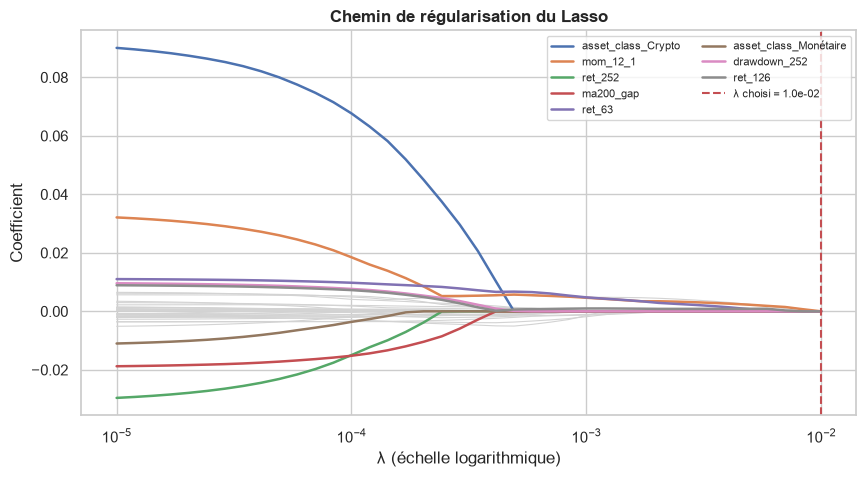

Lasso retenu : 0 coefficients non nuls sur 36


In [34]:
from sklearn.linear_model import lasso_path

pre_fit = make_pipeline(None, NUM_F, CAT_FEATURES).named_steps["pre"].fit(tr[FEATS])
Xt_tr = pre_fit.transform(tr[FEATS])
alphas, coefs, _ = lasso_path(Xt_tr, tr["target_reg"].values, alphas=np.logspace(-5, -2, 40))
names_t = [n.split("__", 1)[-1] for n in pre_fit.get_feature_names_out()]
top_idx = np.argsort(-np.abs(coefs).max(1))[:8]
plt.figure(figsize=(10, 5))
for i in range(coefs.shape[0]):
    plt.plot(alphas, coefs[i], color="lightgrey", lw=.8)
for i in top_idx:
    plt.plot(alphas, coefs[i], lw=1.8, label=names_t[i])
lasso_alpha = fc_info["Lasso"]["hyperparamètres"].get("alpha")
if lasso_alpha is not None:
    plt.axvline(lasso_alpha, color="r", ls="--", label=f"λ choisi = {lasso_alpha:.1e}")
plt.xscale("log")
plt.xlabel("λ (échelle logarithmique)")
plt.ylabel("Coefficient")
plt.title("Chemin de régularisation du Lasso")
plt.legend(fontsize=8, ncol=2)
savefig("10c_lasso_chemin")
plt.show()
n_nonzero = int((np.abs(fc_fitted["Lasso"].named_steps["m"].coef_) > 1e-10).sum())
print(f"Lasso retenu : {n_nonzero} coefficients non nuls sur {len(names_t)}")

**Lecture** : la validation croisée retient un λ pour lequel **tous les coefficients du Lasso sont nuls** : le meilleur Lasso prédit 0 pour tous les actifs, c'est-à-dire la prévision nulle. Autrement dit, d'après la validation croisée, aucune variable n'apporte assez d'information pour justifier un coefficient non nul. C'est une illustration directe de la faiblesse du signal.

**Modèles avec ACP dans le pipeline** : on reprend les deux meilleurs modèles appris de la validation, avec leurs hyperparamètres, en ajoutant une ACP qui conserve **90 % de la variance** (critère du cours). L'ACP est ajustée sur l'entraînement uniquement.

In [35]:
learned_val = fc_val.drop(index=[i for i in fc_val.index if i.startswith("Baseline")])
top2 = learned_val.index[:2].tolist()
for name in top2:
    m = clone(fc_fitted[name].named_steps["m"])
    data = sub_svr if name.startswith("SVR") else tr
    pipe_acp = make_pipeline(m, NUM_F, CAT_FEATURES, n_pca=0.90).fit(data[FEATS], data["target_reg"])
    k = pipe_acp.named_steps["acp"].n_components_
    fc_fitted[f"{name} + ACP"] = pipe_acp
    fc_info[f"{name} + ACP"] = {**fc_info[name], "famille": fc_info[name]["famille"] + " + ACP"}
    val_preds[f"{name} + ACP"] = pipe_acp.predict(va[FEATS])
    print(f"{name} + ACP : {k} composantes conservées")
acp_tab = pd.DataFrame({n: forecast_report(val_preds[n], va) for n in top2 + [f"{n} + ACP" for n in top2]}).T
acp_tab[["MSE", "R² hors échantillon", "IC moyen", "IC t-stat (Newey-West)", "Spread Q5-Q1 net (annualisé)"]]

Elastic Net + ACP : 15 composantes conservées
Ridge + ACP : 15 composantes conservées


,MSE,R² hors échantillon,IC moyen,IC t-stat (Newey-West),Spread Q5-Q1 net (annualisé)
Elastic Net,0.0050,0.0412,0.1634,2.6368,0.3628
Ridge,0.0050,0.0360,0.1566,2.3708,0.3572
Elastic Net + ACP,0.0050,0.0403,0.1606,2.4587,0.3382
Ridge + ACP,0.0050,0.0354,0.1548,2.4406,0.3300


### 4.7 Diagnostic biais / variance : courbe d'apprentissage (cours 1)
Pour le meilleur modèle appris, on trace l'erreur (MSE) sur l'entraînement ($J_{train}$) et en validation croisée ($J_{cv}$) selon la taille de l'entraînement :
- $J_{train}$ et $J_{cv}$ élevés et proches → **biais élevé** (sous-apprentissage) ;
- $J_{train}$ faible et $J_{cv}$ élevé → **variance élevée** (surapprentissage).

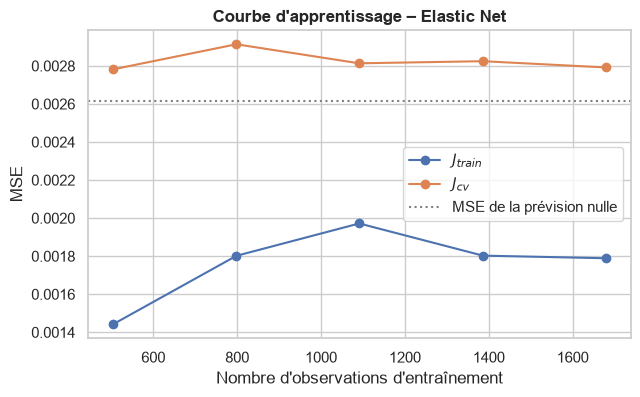

J_train = 0.00179 | J_cv = 0.00279 | prévision nulle ≈ 0.00261
⏱ 4b. Prévision : modèles, régularisation, ACP : 70 s (cumul 5.8 min)


In [36]:
best_learned = learned_val.index[0]
data_lc = sub_svr if best_learned.startswith("SVR") else tr
sizes, sc_tr, sc_cv = learning_curve(clone(fc_fitted[best_learned]), data_lc[FEATS], data_lc["target_reg"],
                                     groups=data_lc.index.get_level_values("date"), cv=cv_exp,
                                     train_sizes=np.linspace(0.3, 1.0, 3 if QUICK_RUN else 5),
                                     scoring="neg_mean_squared_error", n_jobs=N_JOBS)
J_tr, J_cv = -sc_tr.mean(1), -sc_cv.mean(1)
J_null = float((tr["target_reg"] ** 2).mean())
plt.figure(figsize=(7, 4))
plt.plot(sizes, J_tr, "o-", label="$J_{train}$")
plt.plot(sizes, J_cv, "o-", label="$J_{cv}$")
plt.axhline(J_null, color="grey", ls=":", label="MSE de la prévision nulle")
plt.xlabel("Nombre d'observations d'entraînement")
plt.ylabel("MSE")
plt.legend()
plt.title(f"Courbe d'apprentissage – {best_learned}")
savefig("10d_prevision_courbe_apprentissage")
plt.show()
print(f"J_train = {J_tr[-1]:.5f} | J_cv = {J_cv[-1]:.5f} | prévision nulle ≈ {J_null:.5f}")
chrono("4b. Prévision : modèles, régularisation, ACP")

### 4.8 Trois méthodes d'évaluation et leur comparaison (cours 2)
Avec les **mêmes hyperparamètres** (réglés en 4.5), on évalue chaque modèle de trois façons, sur la période entraînement + validation (2011-2021). La période de test reste intacte.
1. **Hold-out temporel** : apprentissage 2011-2019, évaluation 2020-2021 (un seul découpage).
2. **Validation croisée expanding window** : 5 plis ; la fenêtre d'apprentissage grandit à chaque pli.
3. **Validation croisée rolling (sliding) window** : mêmes blocs de validation ; la fenêtre d'apprentissage garde une taille fixe et glisse.

**Grille de lecture du cours** :
- évaluations proches → modèle **stable** ;
- erreur du hold-out plus faible que celle des CV → le découpage unique était **trop optimiste** ;
- rolling meilleur que expanding → les données anciennes dégradent la prévision : une **mémoire courte** est préférable ; l'inverse → l'historique apporte de l'information utile.

In [37]:
from sklearn.ensemble import VotingRegressor
from src.model_zoo import BASELINES
from src.temporal import oof_predictions

learned_names = [n for n in learned_val.index if "+ ACP" not in n]
three_models = {"Baseline – moyenne par actif": BASELINES["Baseline – moyenne par actif"],
                **{n: fc_fitted[n] for n in learned_names[:3] if not n.startswith("SVR")}}
if "Ridge" not in three_models:
    three_models["Ridge"] = fc_fitted["Ridge"]
rows3 = []
for name, model in three_models.items():
    t3 = evaluate_three_ways(model, tr, va, FEATS, n_splits=3 if QUICK_RUN else 5)
    t3.index = pd.MultiIndex.from_product([[name], t3.index], names=["modèle", "méthode"])
    rows3.append(t3)
three_tab = pd.concat(rows3)
three_tab.to_csv(RESULTS_DIR / "agent_prevision_trois_evaluations.csv")
RESULTS["prevision_trois_evaluations"] = three_tab
three_tab[["MSE", "R² hors échantillon", "IC moyen", "écart-type IC", "nb plis"]]

MSE  R² hors échantillon  \
modèle                       méthode                                           
Baseline – moyenne par actif Hold-out temporel   0.0048               0.0844   
                             CV expanding window 0.0033              -0.0299   
                             CV rolling window   0.0035              -0.0870   
Elastic Net                  Hold-out temporel   0.0050               0.0412   
                             CV expanding window 0.0034              -0.0165   
                             CV rolling window   0.0035              -0.0479   
Ridge                        Hold-out temporel   0.0050               0.0360   
                             CV expanding window 0.0033              -0.0011   
                             CV rolling window   0.0034              -0.0058   
XGBoost                      Hold-out temporel   0.0050               0.0338   
                             CV expanding window 0.0034              -0.0344   
                             CV rolling window   0.0035              -0.0735   

                                                  IC moyen  écart-type IC  \
modèle                       méthode                                        
Baseline – moyenne par actif Hold-out temporel      0.1964            NaN   
                             CV expanding window    0.1166         0.0872   
                             CV rolling window      0.0458         0.0380   
Elastic Net                  Hold-out temporel      0.1634            NaN   
                             CV expanding window    0.0345         0.1551   
                             CV rolling window     -0.0058         0.1404   
Ridge                        Hold-out temporel      0.1566            NaN   
                             CV expanding window    0.0414         0.1760   
                             CV rolling window     -0.0149         0.1479   
XGBoost                      Hold-out temporel      0.1588            NaN   
                             CV expanding window    0.0426         0.1793   
                             CV rolling window     -0.0211         0.1443   

                                                  nb plis  
modèle                       méthode                       
Baseline – moyenne par actif Hold-out temporel     1.0000  
                             CV expanding window   5.0000  
                             CV rolling window     5.0000  
Elastic Net                  Hold-out temporel     1.0000  
                             CV expanding window   5.0000  
                             CV rolling window     5.0000  
Ridge                        Hold-out temporel     1.0000  
                             CV expanding window   5.0000  
                             CV rolling window     5.0000  
XGBoost                      Hold-out temporel     1.0000  
                             CV expanding window   5.0000  
                             CV rolling window     5.0000

**Lecture (grille du cours)** :
- **Le hold-out seul était trop optimiste** : tous les modèles ont un R² positif sur la validation 2020-2021, mais un R² **négatif ou nul** en validation croisée. Leur IC chute aussi (de 0,16 à environ 0,04 pour Ridge). Un découpage unique, sur une période favorable, aurait fait croire à un modèle prédictif.
- **Expanding meilleur que rolling** pour tous les modèles : l'historique long apporte de l'information utile ; une mémoire courte (fenêtre glissante) dégrade la prévision.
- Les écarts entre plis sont importants : les modèles sont **instables** d'une période à l'autre.

### 4.9 Test de Diebold-Mariano (cours 2)
Pour affirmer qu'un modèle est **meilleur** qu'un autre, il ne suffit pas d'une MSE un peu plus faible : il faut que l'écart soit **statistiquement significatif**.

- Différentiel de perte à chaque date : $d_t = L(e_{1,t}) - L(e_{2,t})$, où $L$ est l'erreur quadratique moyenne des 25 actifs à la date *t*.
- $H_0 : \mathbb{E}[d_t] = 0$ (même précision) contre $H_1 : \mathbb{E}[d_t] \neq 0$.
- $DM = \bar d / \sqrt{\widehat{Var}(\bar d)}$ avec $\widehat{Var}(\bar d) = \frac{1}{T}\left(\hat\gamma_0 + 2\sum_{k=1}^{h-1}\hat\gamma_k\right)$, où les autocovariances $\hat\gamma_k$ corrigent le chevauchement des cibles ($h$ = 5 pas). On applique la correction de petit échantillon de Harvey, Leybourne et Newbold.
- Lecture : modèle 1 = référence, modèle 2 = candidat. **DM > 0 et p < 0,05 → le candidat est meilleur** ; p > 0,05 → les deux sont statistiquement équivalents.

Deux jeux de prévisions sont testés :
- **(a) la validation 2020-2021** : 96 dates seulement, donc un test peu puissant ;
- **(b) les prévisions hors pli de la CV expanding sur 2013-2021** : environ 400 dates. Chaque date y est prédite par un modèle entraîné uniquement sur le passé, donc sans fuite, et toujours sans toucher au test.

In [38]:
losses_val = {n: loss_by_date(va["target_reg"], p) for n, p in val_preds.items()}
dm_val = dm_table(losses_val, "Baseline – prévision nulle")
print("(a) Validation 2020-2021 – référence : prévision nulle")
display(dm_val[["DM", "p-valeur", "T", "verdict"]])

(a) Validation 2020-2021 – référence : prévision nulle


,DM,p-valeur,T,verdict
Baseline – moyenne par actif,1.1482,0.2538,96,équivalent (H0 non rejetée)
Forêt aléatoire,1.1371,0.2584,96,équivalent (H0 non rejetée)
Gradient Boosting,1.0518,0.2956,96,équivalent (H0 non rejetée)
Baseline – momentum 12-1,0.9459,0.3466,96,équivalent (H0 non rejetée)
Ridge + ACP,0.9049,0.3678,96,équivalent (H0 non rejetée)
Ridge,0.8691,0.3870,96,équivalent (H0 non rejetée)
Elastic Net + ACP,0.8179,0.4155,96,équivalent (H0 non rejetée)
Elastic Net,0.7697,0.4434,96,équivalent (H0 non rejetée)
LightGBM,0.7559,0.4516,96,équivalent (H0 non rejetée)
XGBoost,0.5263,0.5999,96,équivalent (H0 non rejetée)


In [39]:
trva = pd.concat([tr, va])
cv_oof = TemporalCV(n_splits=3 if QUICK_RUN else 5, mode="expanding")
oof = {n: oof_predictions(b, trva, FEATS, cv_oof) for n, b in BASELINES.items()}
for n in learned_names:
    oof[n] = oof_predictions(fc_fitted[n], trva, FEATS, cv_oof, max_rows=3000 if n.startswith("SVR") else None,
                             seed=RANDOM_STATE)
    print(f"✓ prévisions hors pli : {n}")
y_oof = trva.loc[oof["Baseline – prévision nulle"].index, "target_reg"]
oof_mse = pd.Series({n: float(((y_oof - p.reindex(y_oof.index)) ** 2).mean()) for n, p in oof.items()})

# Ensemble : moyenne des prévisions des 3 meilleurs modèles appris (MSE hors pli)
top3_oof = oof_mse.drop([n for n in oof_mse.index if n.startswith("Baseline")]).sort_values().index[:3].tolist()
oof["Ensemble (moyenne des 3 meilleurs)"] = sum(oof[n] for n in top3_oof) / 3
print("Ensemble construit avec :", top3_oof)

✓ prévisions hors pli : Elastic Net


✓ prévisions hors pli : Ridge


✓ prévisions hors pli : XGBoost


✓ prévisions hors pli : LightGBM


✓ prévisions hors pli : Forêt aléatoire


✓ prévisions hors pli : Gradient Boosting


... (3 outputs left out)

✓ prévisions hors pli : Lasso


✓ prévisions hors pli : SVR (noyau RBF)


✓ prévisions hors pli : CatBoost


✓ prévisions hors pli : MLP (Adam)
Ensemble construit avec : ['Ridge', 'Arbre de décision', 'Forêt aléatoire']


In [40]:
trva_oof = trva.loc[y_oof.index]
oof_report = pd.DataFrame({n: forecast_report(p.reindex(y_oof.index), trva_oof) for n, p in oof.items()}).T.sort_values("MSE")
losses_oof = {n: loss_by_date(y_oof, p.reindex(y_oof.index)) for n, p in oof.items()}
dm_null = dm_table(losses_oof, "Baseline – prévision nulle")
dm_asset = dm_table(losses_oof, "Baseline – moyenne par actif")
dm_oof = pd.DataFrame({"MSE hors pli": oof_report["MSE"], "IC moyen": oof_report["IC moyen"],
                       "IC t-stat (NW)": oof_report["IC t-stat (Newey-West)"],
                       "DM vs prévision nulle": dm_null["DM"], "p vs nulle": dm_null["p-valeur"],
                       "DM vs moyenne par actif": dm_asset["DM"], "p vs moyenne par actif": dm_asset["p-valeur"]})
dm_oof = dm_oof.sort_values("MSE hors pli")
dm_oof.to_csv(RESULTS_DIR / "agent_prevision_diebold_mariano.csv")
RESULTS["prevision_diebold_mariano"] = dm_oof
print(f"(b) Prévisions hors pli : {y_oof.index.get_level_values('date').nunique()} dates, "
      f"{y_oof.index.get_level_values('date').min().date()} → {y_oof.index.get_level_values('date').max().date()}")
dm_oof.style.format("{:.4f}").background_gradient(subset=["p vs nulle"], cmap="RdYlGn_r", vmin=0, vmax=0.2)

(b) Prévisions hors pli : 454 dates, 2012-10-22 → 2021-11-19


,MSE hors pli,IC moyen,IC t-stat (NW),DM vs prévision nulle,p vs nulle,DM vs moyenne par actif,p vs moyenne par actif
Baseline – moyenne par actif,0.0033,0.1164,3.8929,0.3707,0.7110,nan,nan
Ensemble (moyenne des 3 meilleurs),0.0033,0.0472,1.3108,0.8207,0.4122,-0.2238,0.8230
Ridge,0.0033,0.0411,1.1996,0.6153,0.5386,-0.2433,0.8079
Arbre de décision,0.0034,0.0237,0.7815,0.3905,0.6963,-0.3288,0.7425
Forêt aléatoire,0.0034,0.0396,1.1052,0.3599,0.7191,-0.3511,0.7257
Baseline – prévision nulle,0.0034,nan,nan,nan,nan,-0.3707,0.7110
LightGBM,0.0034,0.0279,0.7973,-0.0518,0.9587,-0.4717,0.6374
Elastic Net,0.0034,0.0342,1.0217,-0.1076,0.9143,-0.5029,0.6153
XGBoost,0.0034,0.0423,1.2080,-0.1039,0.9173,-0.5428,0.5875
Lasso,0.0034,-0.0372,-0.5922,-1.6304,0.1037,-0.4321,0.6659


**Lecture** : sur les ~400 dates hors pli, **aucun modèle ne bat la prévision nulle** de façon significative (meilleure p-valeur ≈ 0,4). Certains font même significativement moins bien (SVR face à la prévision nulle ; régression linéaire non régularisée face à la moyenne par actif). La baseline « moyenne par actif » a l'IC le plus élevé et le plus significatif (≈ 0,12, t ≈ 3,9) : le signal le plus robuste de 2013-2021 est la **prime de classe d'actifs** (actions > obligations), pas un signal de sélection appris par un modèle.

### 4.10 Choix du modèle (règle fixée avant de voir les résultats)
1. **Critère** : la MSE hors pli sur 2013-2021, plus fiable que la seule validation 2020-2021 (quatre fois plus de dates).
2. **Garde-fou** : l'agent Prévision n'influence l'allocation que si le modèle retenu bat la **prévision nulle** au test de Diebold-Mariano (DM > 0, p < 0,05). Sinon, son poids est mis à zéro ($\alpha = 0$) et l'allocation repose uniquement sur le risque et l'allocation stratégique du profil. Le modèle reste affiché à titre d'information.
3. Si le modèle est activé, son signal entre dans l'allocation par la loi fondamentale de la gestion active (Grinold & Kahn) : $\alpha_i = IC \times \sigma_i \times z_i$, avec $z_i$ la prévision standardisée entre actifs, $\sigma_i$ la volatilité de l'actif, et un IC divisé par deux par prudence (l'IC mesuré surestime en général la performance future).

In [41]:
cands = dm_oof.drop(index=[i for i in dm_oof.index if i.startswith("Baseline")])
best_fc_name = cands["MSE hors pli"].idxmin()
dm_best = cands.loc[best_fc_name]
FC_ACTIVE = bool(dm_best["DM vs prévision nulle"] > 0 and dm_best["p vs nulle"] < 0.05)
IC_VAL = float(dm_best["IC moyen"])
IC_USED = IC_SHRINK * IC_VAL if (FC_ACTIVE and IC_VAL > 0) else 0.0
print(f"Modèle retenu : {best_fc_name}")
print(f"  MSE hors pli = {dm_best['MSE hors pli']:.5f} | IC = {IC_VAL:.4f} (t = {dm_best['IC t-stat (NW)']:.2f})")
print(f"  DM vs prévision nulle : {dm_best['DM vs prévision nulle']:.2f} (p = {dm_best['p vs nulle']:.3f})")
print(f"  DM vs moyenne par actif : {dm_best['DM vs moyenne par actif']:.2f} (p = {dm_best['p vs moyenne par actif']:.3f})")
print("→ Agent Prévision", "ACTIVÉ" if FC_ACTIVE else "NON ACTIVÉ (α = 0)", f"| IC utilisé = {IC_USED:.4f}")


def build_forecast_model(name):
    # Pipeline du modèle retenu (un ensemble est un VotingRegressor des 3 meilleurs pipelines)
    if name.startswith("Ensemble"):
        return VotingRegressor([(f"m{i}", clone(fc_fitted[n])) for i, n in enumerate(top3_oof)])
    return clone(fc_fitted[name])


chrono("4c. Prévision : 3 évaluations, Diebold-Mariano, choix")

Modèle retenu : Ensemble (moyenne des 3 meilleurs)
  MSE hors pli = 0.00334 | IC = 0.0472 (t = 1.31)
  DM vs prévision nulle : 0.82 (p = 0.412)
  DM vs moyenne par actif : -0.22 (p = 0.823)
→ Agent Prévision NON ACTIVÉ (α = 0) | IC utilisé = 0.0000
⏱ 4c. Prévision : 3 évaluations, Diebold-Mariano, choix : 58 s (cumul 6.8 min)


### 4.11 Évaluation unique sur le test (2022 → fin)
Le modèle retenu et les baselines sont ré-entraînés sur **entraînement + validation** (étape 4 de la méthode du cours), puis évalués **une seule fois** sur le test. Aucun choix n'est modifié après cette étape.

In [42]:
best_fc = build_forecast_model(best_fc_name).fit(trva[FEATS], trva["target_reg"])
test_models = {best_fc_name: best_fc, **{n: clone(b).fit(trva[FEATS], trva["target_reg"]) for n, b in BASELINES.items()}}
test_preds = {n: m.predict(te[FEATS]) for n, m in test_models.items()}
fc_test = pd.DataFrame({n: forecast_report(p, te) for n, p in test_preds.items()}).T
losses_te = {n: loss_by_date(te["target_reg"], p) for n, p in test_preds.items()}
for ref in ("Baseline – prévision nulle", "Baseline – moyenne par actif"):
    d = dm_table(losses_te, ref)
    fc_test[f"DM vs {ref.split('– ')[1]}"] = d["DM"]
    fc_test[f"p vs {ref.split('– ')[1]}"] = d["p-valeur"]
fc_test.to_csv(RESULTS_DIR / "agent_prevision_test.csv")
RESULTS["prevision_test"] = fc_test
fc_test

,MSE,RMSE,MAE,R² hors échantillon,IC moyen,IC t-stat (Newey-West),% dates IC>0,Spread Q5-Q1 net (annualisé),Spread Q5-Q1 brut (annualisé),DM vs prévision nulle,p vs prévision nulle,DM vs moyenne par actif,p vs moyenne par actif
Ensemble (moyenne des 3 meilleurs),0.0025,0.0496,0.0331,0.0015,0.1002,2.3523,0.5934,0.0984,0.1048,0.0759,0.9396,2.0856,0.0381
Baseline – prévision nulle,0.0025,0.0497,0.0332,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.5991,0.1111
Baseline – moyenne par actif,0.0027,0.0520,0.0340,-0.0978,0.0485,1.0266,0.5643,-0.0172,-0.0168,-1.5991,0.1111,NaN,NaN
Baseline – momentum 12-1,0.0025,0.0496,0.0331,0.0038,0.0537,1.6440,0.5975,0.0935,0.1054,0.7049,0.4816,1.6776,0.0947


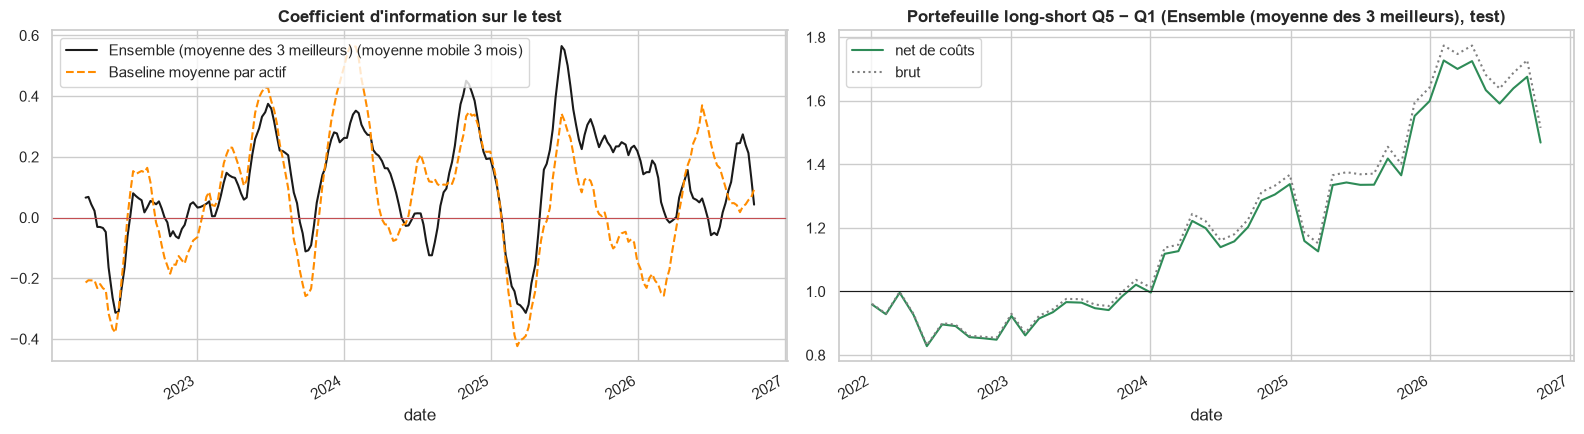

In [43]:
s_te = pd.Series(test_preds[best_fc_name], index=te.index)
ic_te = information_coefficient(s_te, te["fwd_ret"])
ls_te = quintile_spread(s_te, te["fwd_ret"])
ic_base = information_coefficient(pd.Series(test_preds["Baseline – moyenne par actif"], index=te.index), te["fwd_ret"])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ic_te.rolling(13).mean().plot(ax=axes[0], color="k", label=f"{best_fc_name} (moyenne mobile 3 mois)")
ic_base.rolling(13).mean().plot(ax=axes[0], color="darkorange", ls="--", label="Baseline moyenne par actif")
axes[0].axhline(0, color="r", lw=.8)
axes[0].legend()
axes[0].set_title("Coefficient d'information sur le test")
(1 + ls_te["net"].fillna(0)).cumprod().plot(ax=axes[1], color="seagreen", label="net de coûts")
(1 + ls_te["brut"].fillna(0)).cumprod().plot(ax=axes[1], color="grey", ls=":", label="brut")
axes[1].axhline(1, color="k", lw=.8)
axes[1].legend()
axes[1].set_title(f"Portefeuille long-short Q5 − Q1 ({best_fc_name}, test)")
plt.tight_layout()
savefig("11_prevision_test")
plt.show()

**Lecture** : sur le test, le modèle retenu (moyenne de Ridge, de l'arbre de décision et de la forêt aléatoire) obtient une MSE **identique** à celle de la prévision nulle (R² ≈ 0, DM non significatif), même s'il garde un classement des actifs légèrement informatif (IC ≈ 0,10). La baseline « moyenne par actif », la meilleure sur 2013-2021, devient **nettement moins bonne** que la prévision nulle (R² ≈ −10 %) : la prime de classe d'actifs s'est retournée en 2022 (actions et obligations ont baissé ensemble). C'est la **dérive des données** annoncée en 4.3. Le garde-fou de 4.10, décidé avant le test, a donc eu raison de ne pas laisser ces prévisions guider l'allocation.

### 4.12 Interprétabilité de l'agent Prévision (cours 1)
1. **Interprétabilité intrinsèque** : coefficients du modèle Ridge (variables standardisées, donc comparables entre elles).
2. **Explicabilité globale** : importance par permutation sur le test (hausse de la MSE quand on mélange une variable) et valeurs SHAP moyennes.
3. **Explicabilité locale** : contribution de chaque variable à la prévision d'un actif à la dernière date disponible.
4. **Analyse des erreurs** : par classe d'actifs et par année.

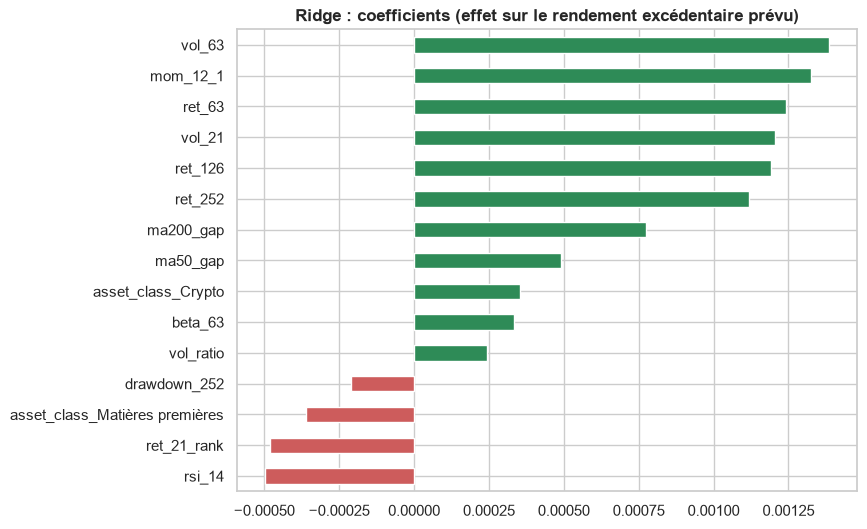

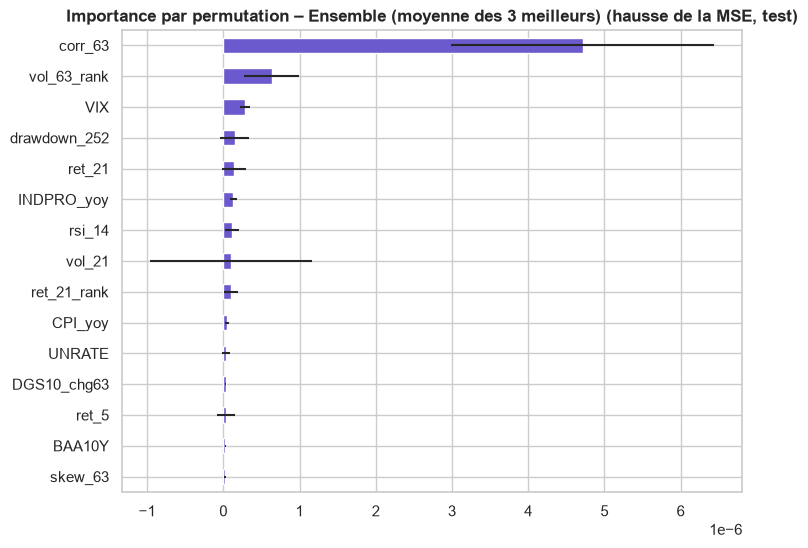

In [44]:
from sklearn.inspection import permutation_importance
from src.explain import make_explainer, shap_values, global_importance, local_explanation

ridge_pipe = fc_fitted["Ridge"]
names_r = [n.split("__", 1)[-1] for n in ridge_pipe.named_steps["pre"].get_feature_names_out()]
coef_r = pd.Series(ridge_pipe.named_steps["m"].coef_, index=names_r)
coef_r = coef_r.reindex(coef_r.abs().sort_values(ascending=False).index).head(15).sort_values()
coef_r.plot.barh(figsize=(8, 6), color=np.where(coef_r > 0, "seagreen", "indianred"))
plt.title("Ridge : coefficients (effet sur le rendement excédentaire prévu)")
savefig("12a_prevision_coefficients_ridge")
plt.show()

pi_fc = permutation_importance(best_fc, te[FEATS], te["target_reg"], scoring="neg_mean_squared_error",
                               n_repeats=3 if QUICK_RUN else 5, random_state=RANDOM_STATE, n_jobs=N_JOBS)
pi_fc = pd.DataFrame({"importance": pi_fc.importances_mean, "écart-type": pi_fc.importances_std},
                     index=FEATS).sort_values("importance", ascending=False)
pi_fc.to_csv(RESULTS_DIR / "agent_prevision_importance_permutation.csv")
TOP_FEATURES = pi_fc.index[:10].tolist()
pi_fc.head(15).iloc[::-1].plot.barh(y="importance", xerr="écart-type", legend=False, figsize=(8, 6), color="slateblue")
plt.title(f"Importance par permutation – {best_fc_name} (hausse de la MSE, test)")
savefig("12_prevision_permutation")
plt.show()

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


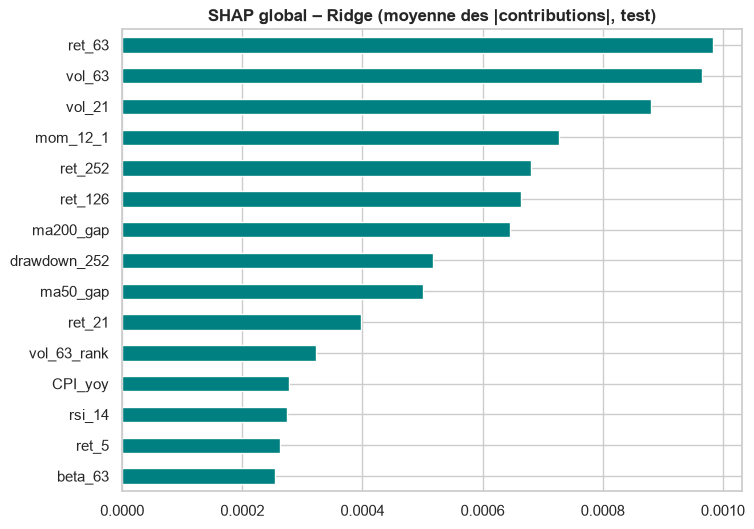

Variables les plus influentes (SHAP global) : {'ret_63': 0.00098, 'vol_63': 0.00097, 'vol_21': 0.00088, 'mom_12_1': 0.00073, 'ret_252': 0.00068, 'ret_126': 0.00066}


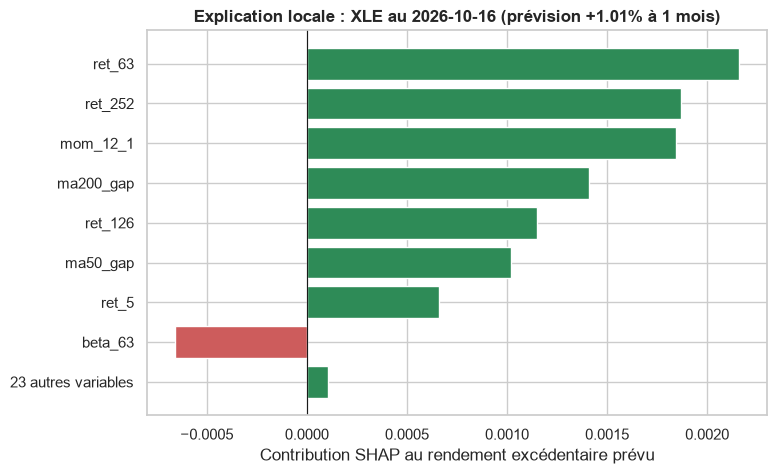

In [45]:
# SHAP : sur le modèle retenu s'il s'agit d'un pipeline unique, sinon sur le premier modèle de l'ensemble
shap_name = best_fc_name if not best_fc_name.startswith("Ensemble") else top3_oof[0]
shap_pipe = best_fc if not best_fc_name.startswith("Ensemble") else clone(fc_fitted[shap_name]).fit(trva[FEATS], trva["target_reg"])
explainer_fc = make_explainer(shap_pipe, trva[FEATS])
X_sh = te[FEATS].sample(400 if QUICK_RUN else 2000, random_state=RANDOM_STATE)
sv_fc = shap_values(shap_pipe, explainer_fc, X_sh)
imp_fc = global_importance(sv_fc).head(15)
imp_fc.iloc[::-1].plot.barh(figsize=(8, 6), color="teal")
plt.title(f"SHAP global – {shap_name} (moyenne des |contributions|, test)")
savefig("13_prevision_shap")
plt.show()
print("Variables les plus influentes (SHAP global) :", imp_fc.head(6).round(5).to_dict())

last_d = te.index.get_level_values("date").max()
te_last = te.xs(last_d, level="date", drop_level=False)
top_asset = pd.Series(shap_pipe.predict(te_last[FEATS]), index=te_last.index).idxmax()
row = te_last.loc[[top_asset]][FEATS]
s_loc = shap_values(shap_pipe, explainer_fc, row).iloc[0]
loc = local_explanation(s_loc, row.iloc[0], top=8).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(loc["libellé"], loc["contribution"], color=np.where(loc["contribution"] > 0, "seagreen", "indianred"))
plt.axvline(0, color="k", lw=.8)
plt.title(f"Explication locale : {top_asset[1]} au {last_d.date()} "
          f"(prévision {shap_pipe.predict(row)[0]:+.2%} à 1 mois)")
plt.xlabel("Contribution SHAP au rendement excédentaire prévu")
savefig("14_prevision_shap_local")
plt.show()

In [46]:
err_fc = te[["fwd_ret", "target_reg", "asset_class"]].copy()
err_fc["prévision"] = test_preds[best_fc_name]
err_fc["année"] = err_fc.index.get_level_values("date").year
by_class = err_fc.groupby("asset_class").apply(lambda g: pd.Series({
    "n": len(g), "MSE modèle": ((g["target_reg"] - g["prévision"]) ** 2).mean(),
    "MSE prévision nulle": (g["target_reg"] ** 2).mean(),
    "rendement excédentaire moyen réalisé": g["target_reg"].mean(), "prévision moyenne": g["prévision"].mean()}))
by_year = err_fc.groupby("année").apply(lambda g: pd.Series({
    "n": len(g), "IC": information_coefficient(g["prévision"], g["fwd_ret"]).mean(),
    "R² hors échantillon": 1 - ((g["target_reg"] - g["prévision"]) ** 2).mean() / (g["target_reg"] ** 2).mean()}))
display(by_class)
display(by_year)
by_class.to_csv(RESULTS_DIR / "agent_prevision_erreurs_par_classe.csv")
by_year.to_csv(RESULTS_DIR / "agent_prevision_erreurs_par_annee.csv")

forecast_bundle = {"pipeline": best_fc, "features": FEATS, "ic": IC_USED, "active": FC_ACTIVE, "task": "régression",
                   "top_features": TOP_FEATURES, "model_name": best_fc_name, "params": fc_info.get(best_fc_name, {}),
                   "ic_hors_pli": IC_VAL}
chrono("4d. Prévision : test et interprétabilité")

,n,MSE modèle,MSE prévision nulle,rendement excédentaire moyen réalisé,prévision moyenne
asset_class,,,,,
Actions,"3,133.0000",0.0016,0.0017,0.0021,0.0003
Crypto,241.0000,0.0184,0.0185,0.0139,0.0208
Immobilier,241.0000,0.0011,0.0011,-0.0049,-0.0021
Matières premières,723.0000,0.0052,0.0050,0.0065,0.0013
Monétaire,241.0000,0.0009,0.0010,-0.0061,-0.0050
Obligations,"1,446.0000",0.0007,0.0007,-0.0082,-0.0041


,n,IC,R² hors échantillon
année,,,
2022,"1,250.0000",-0.0232,-0.0339
2023,"1,250.0000",0.1658,0.0307
2024,"1,275.0000",0.1567,0.0615
2025,"1,250.0000",0.1701,0.0290
2026,"1,000.0000",0.0127,-0.0572


⏱ 4d. Prévision : test et interprétabilité : 15 s (cumul 7.0 min)


## 5. Agent Régime et Agent Alerte – apprentissage non supervisé

### 5.1 Objectif et variables
L'agent Régime classe chaque journée de marché en **régimes** (Calme / Neutre / Stress) **sans étiquette** : c'est un problème de **clustering** (cours 2). L'état du marché à la date *t* est décrit par 5 variables **stationnaires** :
- rendement du S&P 500 sur 1 mois ;
- log-volatilité réalisée du S&P 500 sur 1 mois ;
- drawdown du S&P 500 (écart au plus haut sur 1 an) ;
- log du VIX (volatilité implicite) ;
- variation sur 3 mois du spread de crédit Baa − Trésor.

**Pourquoi des variables stationnaires** : la version 1 du projet utilisait des niveaux (pente de courbe, spread). La courbe des taux s'est inversée de 2022 à 2024, un niveau jamais vu à l'entraînement, et le modèle classait alors 91 % du test en « Stress ». Les logarithmes et les variations restent dans la plage de l'entraînement.

Les modèles sont ajustés sur **2011-2019 uniquement**, après standardisation apprise sur cette période, puis appliqués date par date (filtrage, sans regarder le futur).

### 5.2 Les quatre familles de clustering du cours
| Famille | Méthode | Principe | Nombre de groupes |
|---|---|---|---|
| Partition | **K-means** | minimise l'inertie intra-classe $J=\frac1n\sum_i\lVert x_i-\mu_{c^{(i)}}\rVert^2$ | fixé (coude, silhouette) |
| Hiérarchique | **CAH, critère de Ward** | fusionne à chaque étape les deux groupes dont la fusion augmente le moins l'inertie intra : $\frac{n_a n_b}{n_a+n_b}d^2(\mu_a,\mu_b)$ | choisi en coupant le dendrogramme |
| Densité | **DBSCAN** | un groupe = une zone dense ; les points isolés sont du **bruit** | déterminé par ε et min_samples |
| Probabiliste | **Mélange gaussien (GMM)** estimé par **EM** | $p(x)=\sum_k\pi_k\,\mathcal N(x;\mu_k,\Sigma_k)$ ; maximise la log-vraisemblance | fixé (critère BIC) |

**Règle fixée à l'avance** : l'agent Régime doit fournir des **probabilités d'appartenance** $\gamma_{ik}$ (affichées dans l'application, et réutilisées comme variables en 5.5). Seul le GMM en produit : c'est donc lui qui est utilisé par le système. Les trois autres méthodes servent de **comparaison** (indices de qualité) et de **contrôle de robustesse** (les régimes trouvés concordent-ils ?).

Jours d'entraînement : 2391 | variables : ['mkt_ret_21', 'mkt_logvol_21', 'mkt_drawdown', 'logVIX', 'credit_chg63']


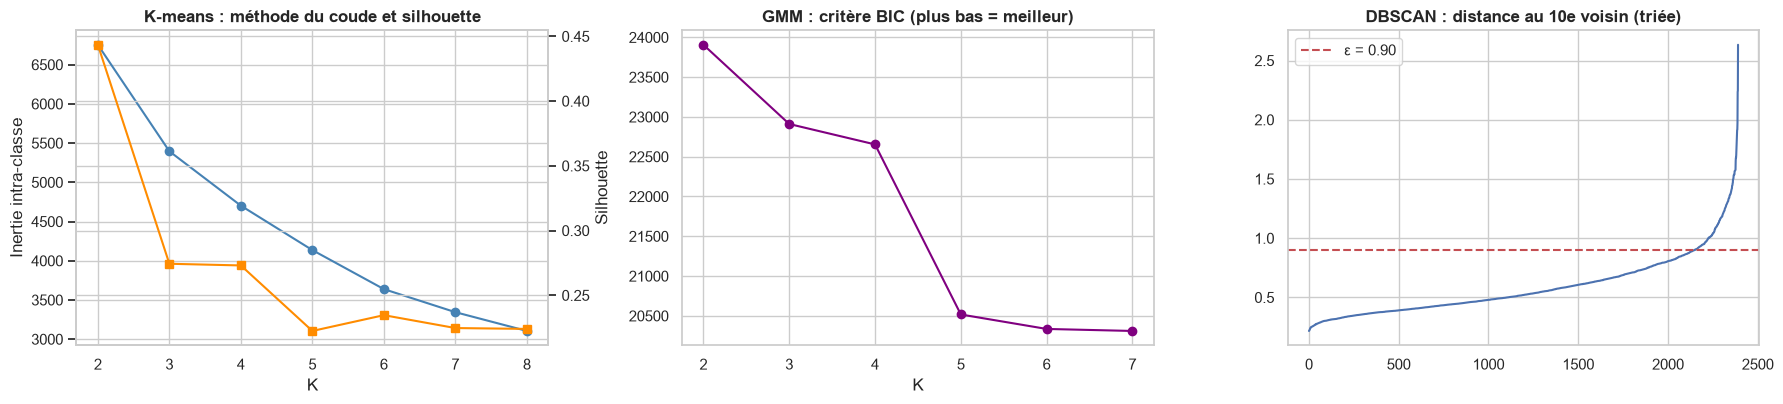

In [47]:
from scipy.cluster.hierarchy import dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from src.features import compute_market_features, REGIME_FEATURES
from src.regimes import (kmeans_elbow, gmm_bic, k_distance, fit_four_families, compare_families,
                         describe_clusters, label_by_volatility)

mkt_feat = compute_market_features(prices, macro)
reg_cols = [c for c in REGIME_FEATURES if c in mkt_feat]
M_tr = mkt_feat.loc[:TRAIN_END, reg_cols].dropna()
reg_scaler = StandardScaler().fit(M_tr)
Z_tr = reg_scaler.transform(M_tr)
print("Jours d'entraînement :", len(M_tr), "| variables :", reg_cols)

elbow = kmeans_elbow(Z_tr)
bic = gmm_bic(Z_tr)
kd = k_distance(Z_tr, k=10)
EPS = float(np.quantile(kd, 0.90))     # règle : ε = 90e centile des distances au 10e voisin
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
ax2 = axes[0].twinx()
elbow["inertie intra J_w"].plot(ax=axes[0], marker="o", color="steelblue", label="inertie intra")
elbow["silhouette"].plot(ax=ax2, marker="s", color="darkorange", label="silhouette")
axes[0].set_title("K-means : méthode du coude et silhouette")
axes[0].set_ylabel("Inertie intra-classe")
ax2.set_ylabel("Silhouette")
bic.plot(ax=axes[1], marker="o", color="purple")
axes[1].set_title("GMM : critère BIC (plus bas = meilleur)")
axes[2].plot(kd)
axes[2].axhline(EPS, color="r", ls="--", label=f"ε = {EPS:.2f}")
axes[2].set_title("DBSCAN : distance au 10e voisin (triée)")
axes[2].legend()
plt.tight_layout()
savefig("15_regime_choix_k")
plt.show()

**Choix K = 3** : le coude de K-means est peu marqué et le BIC du GMM continue de baisser au-delà de 3 (avec 2 400 jours, des groupes plus fins sont toujours un peu plus vraisemblables). On retient **3 régimes**, nombre directement **interprétable** et utilisable par un conseiller (Calme / Neutre / Stress). Le cours le rappelle : il faut choisir un nombre de groupes qui « met en lumière des structures intéressantes », pas seulement celui qui optimise un critère.

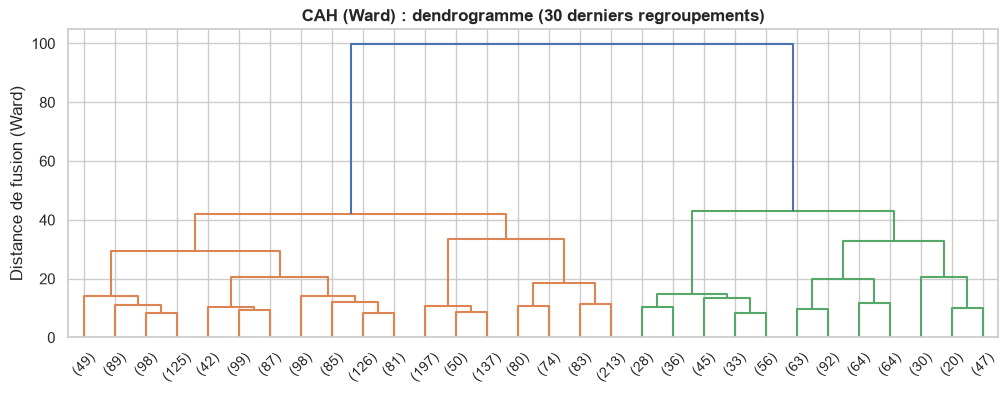

,nb clusters,% bruit,silhouette,Davies-Bouldin,Calinski-Harabasz,inertie intra J_w,inertie inter J_b,% inertie expliquée,accord avec le GMM (indice de Rand ajusté)
K-means,3.0000,0.0000,0.2744,1.2872,"1,451.3946","5,395.8944","6,559.1056",54.8650,0.2653
CAH (Ward),3.0000,0.0000,0.3584,1.1827,"1,164.5748","6,052.0744","5,902.9256",49.3762,0.2471
DBSCAN,3.0000,3.9314,0.4810,0.6327,98.9408,"8,627.6321",744.2239,7.9411,0.0079
GMM (EM),3.0000,0.0000,0.1198,1.7925,794.8703,"7,177.0743","4,777.9257",39.9659,1.0000


In [48]:
K = 3
fitted_cl = fit_four_families(Z_tr, k=K, eps=EPS, min_samples=10)
plt.figure(figsize=(12, 4))
dendrogram(fitted_cl["CAH (Ward)"][0], truncate_mode="lastp", p=30, color_threshold=None)
plt.title("CAH (Ward) : dendrogramme (30 derniers regroupements)")
plt.ylabel("Distance de fusion (Ward)")
savefig("15b_regime_dendrogramme")
plt.show()

cl_scores = compare_families(Z_tr, fitted_cl)
gmm_lab = fitted_cl["GMM (EM)"][1]
cl_scores["accord avec le GMM (indice de Rand ajusté)"] = [
    adjusted_rand_score(gmm_lab[lab >= 0], lab[lab >= 0]) for _, (_, lab) in fitted_cl.items()]
cl_scores.to_csv(RESULTS_DIR / "agent_regime_comparaison_clustering.csv")
RESULTS["regime_clustering"] = cl_scores
cl_scores

**Comment lire les indices** : **silhouette** (entre −1 et 1, ↑ = groupes compacts et séparés), **Davies-Bouldin** (↓), **Calinski-Harabasz** (↑), **% d'inertie expliquée** $J_b/(J_w+J_b)$ (↑). Pour DBSCAN, les indices sont calculés sans les points de bruit.

Le GMM obtient en général des indices géométriques moins bons que K-means et la CAH : c'est attendu. Ses groupes sont des **ellipses qui se chevauchent** (covariances différentes par régime), alors que ces indices favorisent des groupes sphériques bien séparés. Le GMM capte en revanche une structure que les autres ignorent : le régime de stress est **beaucoup plus dispersé** que le régime calme. L'**indice de Rand ajusté** mesure l'accord entre partitions (1 = identiques, 0 = accord dû au hasard).

### 5.3 Description des régimes du GMM (cours 2, « Décrire les clusters »)

In [49]:
gmm = fitted_cl["GMM (EM)"][0]
centers = pd.DataFrame(reg_scaler.inverse_transform(gmm.means_), columns=reg_cols)
label_map = label_by_volatility(centers, "mkt_logvol_21")
prof = describe_clusters(M_tr, gmm_lab)
prof.index = [label_map.get(i, i) if isinstance(i, (int, np.integer)) else i for i in prof.index]
prof["vol. annualisée"] = np.exp(prof["mkt_logvol_21"])
prof.loc["p-valeur Kruskal-Wallis", "vol. annualisée"] = np.nan
display(prof)

M_all = mkt_feat[reg_cols].dropna()
proba_all = pd.DataFrame(gmm.predict_proba(reg_scaler.transform(M_all)), index=M_all.index)
proba_all.columns = [label_map[c] for c in proba_all.columns]
proba_all = proba_all.T.groupby(level=0).sum().T[["Calme", "Neutre", "Stress"]]
reg_series = proba_all.idxmax(axis=1)

,effectif,% période,mkt_ret_21,mkt_logvol_21,mkt_drawdown,logVIX,credit_chg63,vol. annualisée
Stress,649.0000,27.1435,0.0010,-1.6927,-0.0703,3.0513,0.2001,0.1840
Calme,779.0000,32.5805,0.0289,-2.4578,-0.0017,2.5246,-0.1120,0.0856
Neutre,963.0000,40.2760,0.0052,-2.2197,-0.0182,2.7589,-0.0814,0.1086
p-valeur Kruskal-Wallis,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,NaN


### 5.4 Validation économique hors échantillon
Un bon régime doit **annoncer** le risque à venir. On mesure, après chaque jour classé dans un régime, la volatilité réalisée et le rendement du S&P 500 **sur le mois suivant**. Le **η²** (part de la variance de la volatilité future expliquée par le régime) résume le pouvoir informatif du découpage. La validation 2020-2021 sert à juger le modèle ; les chiffres du test sont seulement **descriptifs** et ne servent à aucun choix.

In [50]:
fwd_ret_spy = prices["SPY"].shift(-21) / prices["SPY"] - 1
fwd_vol_spy = returns["SPY"].rolling(21).std().shift(-21) * np.sqrt(252)


def regime_eval(start, end):
    idx = reg_series.loc[start:end].index
    df = pd.DataFrame({"régime": reg_series.loc[idx], "rdt SPY 21 j futur": fwd_ret_spy.reindex(idx),
                       "vol. réalisée future": fwd_vol_spy.reindex(idx)}).dropna()
    tab = df.groupby("régime").agg(fréquence=("régime", "size"), **{
        "rdt moyen 21 j futur": ("rdt SPY 21 j futur", "mean"), "vol. future moyenne": ("vol. réalisée future", "mean")})
    tab["fréquence"] /= tab["fréquence"].sum()
    gm = df["vol. réalisée future"].mean()
    eta2 = sum(len(g) * (g["vol. réalisée future"].mean() - gm) ** 2 for _, g in df.groupby("régime")) / \
        ((df["vol. réalisée future"] - gm) ** 2).sum()
    return tab.reindex(["Calme", "Neutre", "Stress"]), float(eta2)


reg_eval = {}
for nom, (a, b) in {"Entraînement 2011-2019": (None, TRAIN_END), "Validation 2020-2021": ("2020-01-01", VAL_END),
                    "Test 2022 → (descriptif)": ("2022-01-01", None)}.items():
    tab, eta2 = regime_eval(a, b)
    print(f"{nom} : η² = {eta2:.2f}")
    display(tab)
    reg_eval[nom] = tab.assign(eta2=eta2)
reg_tab = pd.concat(reg_eval, names=["période", "régime"])
reg_tab.to_csv(RESULTS_DIR / "agent_regime_validation.csv")
RESULTS["regime"] = reg_tab
assert reg_eval["Validation 2020-2021"]["fréquence"].max() < 0.8, "Un régime domine : vérifier la stationnarité"

Entraînement 2011-2019 : η² = 0.21


,fréquence,rdt moyen 21 j futur,vol. future moyenne
régime,,,
Calme,0.3258,0.0069,0.0967
Neutre,0.4028,0.0099,0.1226
Stress,0.2714,0.0214,0.1740


Validation 2020-2021 : η² = 0.12


,fréquence,rdt moyen 21 j futur,vol. future moyenne
régime,,,
Calme,0.1347,-0.0323,0.2021
Neutre,0.5188,0.0149,0.1452
Stress,0.3465,0.0407,0.2693


Test 2022 → (descriptif) : η² = 0.29


,fréquence,rdt moyen 21 j futur,vol. future moyenne
régime,,,
Calme,0.2139,0.0072,0.1148
Neutre,0.3806,0.0111,0.1277
Stress,0.4055,0.0124,0.2061


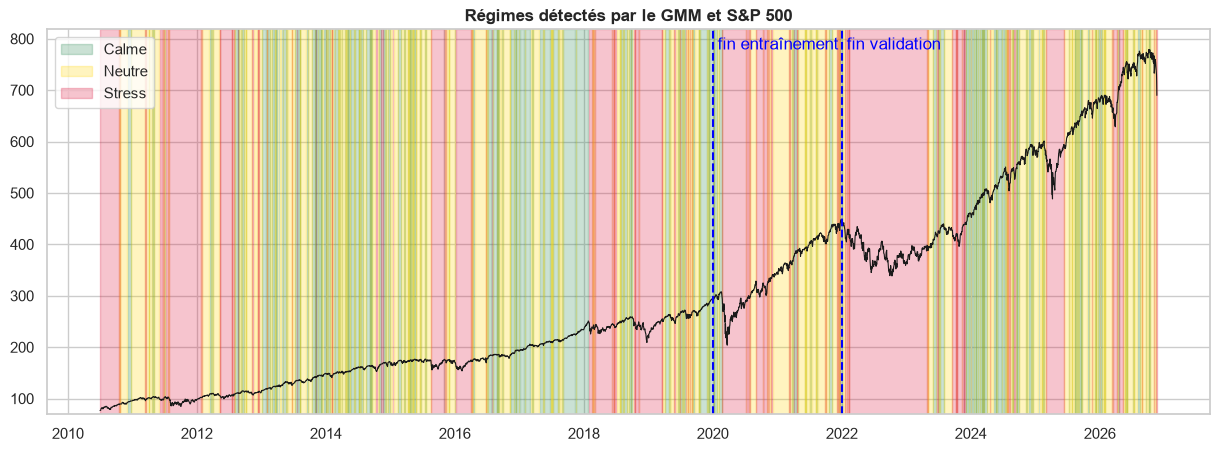

col_0,Calme,Neutre,Stress
de \ vers,,,
Calme,83.3%,15.4%,1.3%
Neutre,10.1%,85.6%,4.3%
Stress,0.9%,5.7%,93.4%


⏱ 5a. Agent Régime : 10 s (cumul 7.2 min)


In [51]:
colors = {"Calme": "seagreen", "Neutre": "gold", "Stress": "crimson"}
fig, ax = plt.subplots(figsize=(15, 5))
spy = prices["SPY"].reindex(reg_series.index)
ax.plot(spy.index, spy.values, color="k", lw=.8)
for reg, col in colors.items():
    ax.fill_between(spy.index, 0, spy.max() * 1.05, where=(reg_series == reg).values, color=col, alpha=.25, label=reg)
ax.set_ylim(spy.min() * .9, spy.max() * 1.05)
for d, lab in ((TRAIN_END, "fin entraînement"), (VAL_END, "fin validation")):
    ax.axvline(pd.Timestamp(d), color="blue", ls="--")
    ax.text(pd.Timestamp(d), spy.max(), f" {lab}", color="blue")
ax.legend(loc="upper left")
ax.set_title("Régimes détectés par le GMM et S&P 500")
savefig("16_regimes")
plt.show()
trans = pd.crosstab(reg_series.shift(1), reg_series, normalize="index")
display(trans.rename_axis("de \\ vers").style.format("{:.1%}"))

regime_bundle = {"model": gmm, "scaler": reg_scaler, "features": reg_cols, "fill": M_tr.median().to_dict(),
                 "label_map": label_map}
mkt_feat.to_csv(DATA_PROC / "market_features.csv")
reg_series.rename("regime").to_csv(DATA_PROC / "regimes.csv")
chrono("5a. Agent Régime")

**Lecture** : sur les trois périodes, le régime « Stress » est suivi de la volatilité future la plus élevée : l'agent **repère bien le risque**. Une limite apparaît en validation : le régime « Calme » y est suivi d'une volatilité plus forte que le régime « Neutre ». C'est l'effet de **février 2020** : le marché était calme juste avant le krach du COVID. L'agent **réagit** au risque (avec quelques jours de retard) mais ne l'**anticipe** pas : aucune variable de marché ne pouvait annoncer une pandémie. En revanche, il n'annonce pas de baisse : les périodes de stress ont souvent été suivies de **rebonds** (rendement futur moyen plus élevé), ce qui rendra coûteuse une réduction systématique de l'exposition en régime de stress (point arbitré sur la validation en section 7). La matrice de transition montre une forte **persistance** des régimes (diagonale proche de 1), ce qui rend la détection en temps réel exploitable.

### 5.5 Le GMM comme extraction de variables (cours 2, remarque 2)
Les probabilités a posteriori $\gamma_{ik}$ (« responsabilités ») mesurent le degré d'appartenance de la journée *i* à chaque régime *k*. On les ajoute comme **3 nouvelles variables** de l'agent Prévision : un modèle peut ainsi apprendre que certains actifs réagissent différemment selon le régime de marché.

**Protocole** : pour le modèle Ridge et pour le meilleur modèle à base d'arbres, mêmes hyperparamètres qu'en 4.5, on compare la version **sans** et **avec** les $\gamma_{ik}$ par le test de Diebold-Mariano.
- **Test principal : la validation 2020-2021** (modèles ajustés sur 2011-2019 ; le GMM aussi : aucun recouvrement).
- Test complémentaire : prévisions hors pli 2013-2021. Limite : le GMM a été ajusté sur 2011-2019 et a donc « vu » les états de marché de ces années (sans jamais voir de rendement futur). Ce test est légèrement optimiste pour la version avec γ.

In [52]:
gamma_cols = ["γ Calme", "γ Neutre", "γ Stress"]
gam = proba_all.rename(columns=dict(zip(["Calme", "Neutre", "Stress"], gamma_cols)))


def add_gamma(df):
    g = gam.reindex(df.index.get_level_values("date")).fillna(1 / 3)
    g.index = df.index
    return pd.concat([df, g], axis=1)


tr_g, va_g, trva_g = add_gamma(tr), add_gamma(va), add_gamma(trva)
FEATS_G, NUM_G = FEATS + gamma_cols, NUM_F + gamma_cols
tree_names = [n for n in cands.index if any(k in n for k in ("Forêt", "Boosting", "LightGBM", "XGBoost", "CatBoost", "Arbre"))]
gamma_models = ["Ridge", tree_names[0]]
rows_g, losses_g = {}, {}
for n in gamma_models:
    m = fc_fitted[n].named_steps["m"]
    p_sans = fc_fitted[n].predict(va[FEATS])
    pipe_g = make_pipeline(clone(m), NUM_G, CAT_FEATURES).fit(tr_g[FEATS_G], tr_g["target_reg"])
    p_avec = pipe_g.predict(va_g[FEATS_G])
    oof_avec = oof_predictions(make_pipeline(clone(m), NUM_G, CAT_FEATURES), trva_g, FEATS_G, cv_oof)
    l_val = {"sans": loss_by_date(va["target_reg"], p_sans), "avec": loss_by_date(va["target_reg"], p_avec)}
    l_oof = {"sans": loss_by_date(y_oof, oof[n].reindex(y_oof.index)),
             "avec": loss_by_date(y_oof, oof_avec.reindex(y_oof.index))}
    dv, do = diebold_mariano(l_val["sans"], l_val["avec"]), diebold_mariano(l_oof["sans"], l_oof["avec"])
    rows_g[n] = {"MSE val. sans γ": l_val["sans"].mean(), "MSE val. avec γ": l_val["avec"].mean(),
                 "DM validation": dv["DM"], "p validation": dv["p-valeur"],
                 "IC val. sans γ": forecast_report(p_sans, va)["IC moyen"],
                 "IC val. avec γ": forecast_report(p_avec, va_g)["IC moyen"],
                 "DM hors pli": do["DM"], "p hors pli": do["p-valeur"]}
gamma_tab = pd.DataFrame(rows_g).T
gamma_tab.to_csv(RESULTS_DIR / "agent_prevision_apport_gamma.csv")
RESULTS["prevision_apport_gamma"] = gamma_tab
print("DM > 0 et p < 0,05 : la version AVEC les probabilités de régime est meilleure.")
gamma_tab

DM > 0 et p < 0,05 : la version AVEC les probabilités de régime est meilleure.


,MSE val. sans γ,MSE val. avec γ,DM validation,p validation,IC val. sans γ,IC val. avec γ,DM hors pli,p hors pli
Ridge,0.0050,0.0050,-1.6538,0.1015,0.1566,0.1553,-1.4254,0.1547
Arbre de décision,0.0051,0.0051,NaN,NaN,0.1151,0.1151,NaN,NaN


**Lecture** : les probabilités de régime n'apportent **aucune amélioration significative** (p > 0,05 dans tous les cas). Pour un arbre de décision peu profond, les prévisions sont même strictement identiques (DM non calculable) : l'arbre n'utilise aucune des trois nouvelles variables. L'information du régime est déjà contenue dans les variables de volatilité et le VIX. Résultat négatif, mais instructif : le GMM sert à décrire le marché et à gérer le risque, pas à prévoir les rendements relatifs.

### 5.6 Agent Alerte : détection d'anomalies (cours 1 et 2)
Une **anomalie** est une observation rare qui se distingue nettement de la majorité des données. Ici, une **journée de marché anormale** (krach, choc de liquidité). Deux usages dans le système : (i) **alerter** le conseiller et le client, (ii) **contrôler la qualité** des données téléchargées.

| Type | Méthode | Principe |
|---|---|---|
| Statistique | **z-score** | $\lvert r_t-\bar r\rvert/\sigma > 4$ sur le rendement du S&P 500 |
| Statistique | **Test de Grubbs** | teste si la valeur la plus extrême est aberrante sous hypothèse gaussienne ; répété tant qu'il rejette |
| ML | **Gaussienne multivariée** | densité $p(x;\mu,\Sigma)$ estimée sur l'entraînement ; anomalie si $p(x) \le \epsilon$ |
| ML | **Isolation Forest** | une anomalie s'isole en peu de coupures aléatoires |
| ML | **LOF** (Local Outlier Factor) | densité locale nettement plus faible que celle de ses voisins |
| ML | **One-Class SVM** | frontière qui entoure les données « normales » |

Il n'existe pas d'étiquette « anomalie » sur les marchés : la validation est **qualitative** (les crises connues sont-elles détectées ?) et repose sur l'**accord entre méthodes**. Seuils et paramètres sont appris sur 2011-2019 (taux d'anomalies attendu : 2 %).

In [53]:
from src.anomalies import zscore_flags, grubbs_iterative, fit_detectors, detect, event_recall

r_spy = returns["SPY"]
z_flags = zscore_flags(r_spy, TRAIN_END, threshold=4.0)
g_flags = grubbs_iterative(r_spy.loc[:TRAIN_END], alpha=0.01)
print(f"z-score > 4 : {int(z_flags.sum())} jours (dont {int(z_flags.loc[:TRAIN_END].sum())} en entraînement) | "
      f"Grubbs (entraînement) : {int(g_flags.sum())} jours aberrants")

detectors = fit_detectors(M_tr, contamination=0.02)
flags = detect(detectors, M_all)
flags["z-score S&P 500"] = z_flags.reindex(flags.index).fillna(False)
rates = flags.drop(columns="nb détecteurs").groupby(np.where(flags.index <= TRAIN_END, "2011-2019 (entraînement)",
                                                             "2020 → (hors échantillon)")).mean()
display(rates.style.format("{:.1%}"))
recall_ev = event_recall(flags)
display(recall_ev.replace({True: "✔", False: "✘"}))
display(flags.drop(columns="nb détecteurs").astype(float).corr().round(2))

z-score > 4 : 42 jours (dont 15 en entraînement) | Grubbs (entraînement) : 11 jours aberrants


,Gaussienne multivariée,Isolation Forest,LOF,One-Class SVM,z-score S&P 500
2011-2019 (entraînement),2.0%,2.0%,1.9%,2.0%,0.5%
2020 → (hors échantillon),22.3%,10.5%,23.5%,27.4%,1.6%


,Gaussienne multivariée,Isolation Forest,LOF,One-Class SVM,z-score S&P 500
Crise de la dette US / euro (août 2011),✔,✔,✔,✔,✔
Dévaluation du yuan (août 2015),✔,✔,✘,✔,✔
Volmageddon (février 2018),✔,✘,✔,✔,✔
Krach COVID (mars 2020),✔,✔,✔,✔,✔
Choc inflation / taux (juin 2022),✔,✔,✔,✔,✔
Choc de liquidité (août 2024),✔,✘,✔,✔,✘


,Gaussienne multivariée,Isolation Forest,LOF,One-Class SVM,z-score S&P 500
Gaussienne multivariée,1.0000,0.5900,0.6900,0.8000,0.1700
Isolation Forest,0.5900,1.0000,0.4100,0.4500,0.2700
LOF,0.6900,0.4100,1.0000,0.7500,0.0900
One-Class SVM,0.8000,0.4500,0.7500,1.0000,0.1300
z-score S&P 500,0.1700,0.2700,0.0900,0.1300,1.0000


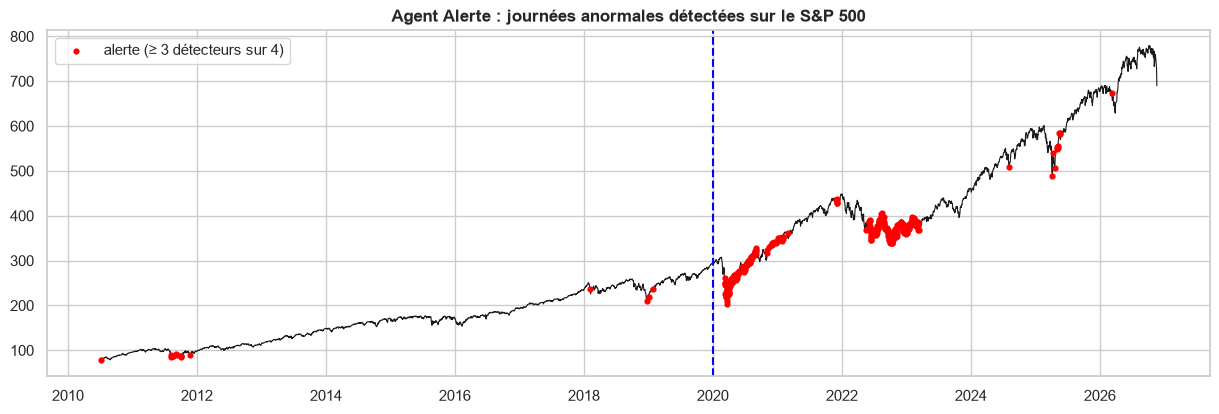

Jours en alerte : 0.6% en entraînement, 19.2% ensuite
⏱ 5b. γ du GMM et Agent Alerte : 4 s (cumul 7.2 min)


In [54]:
ALERT_MIN = 3     # alerte si au moins 3 des 4 détecteurs ML signalent la journée (vote majoritaire)
alert = flags["nb détecteurs"] >= ALERT_MIN
fig, ax = plt.subplots(figsize=(15, 4.5))
spy_a = prices["SPY"].reindex(flags.index)
ax.plot(spy_a.index, spy_a.values, color="k", lw=.8)
ax.scatter(spy_a.index[alert], spy_a[alert], color="red", s=12, label=f"alerte (≥ {ALERT_MIN} détecteurs sur 4)", zorder=3)
ax.axvline(pd.Timestamp(TRAIN_END), color="blue", ls="--")
ax.legend()
ax.set_title("Agent Alerte : journées anormales détectées sur le S&P 500")
savefig("16b_anomalies")
plt.show()
print(f"Jours en alerte : {alert.loc[:TRAIN_END].mean():.1%} en entraînement, {alert.loc[TRAIN_END:].mean():.1%} ensuite")
alert_bundle = {"detectors": detectors, "features": reg_cols, "min_votes": ALERT_MIN}
chrono("5b. γ du GMM et Agent Alerte")

**Lecture** : toutes les crises connues sont signalées par plusieurs méthodes, et les détecteurs multivariés s'accordent largement entre eux. Le z-score, qui ne regarde que le rendement du jour, est peu corrélé aux autres : il repère les chocs brutaux d'une journée, alors que les méthodes multivariées repèrent des **états** de marché anormaux qui durent (volatilité, VIX et spread de crédit élevés ensemble).

**Dérive des données** (*data drift*, défi du ML vu au cours 1) : les détecteurs signalent environ 2 % des jours sur l'entraînement, comme prévu, mais une part bien plus élevée après 2019. Le marché d'après 2020 est plus agité que celui des années 2010. Pour limiter les fausses alertes, l'agent Alerte n'alerte que si **au moins 3 des 4 détecteurs** sont d'accord ; il faudra **recalibrer** périodiquement les seuils sur des données récentes.

## 6. Système multi-agent : orchestration et allocation

### 6.1 Architecture (IA agentique)
Chaque agent est spécialisé, lit ce dont il a besoin sur un **tableau noir** (*blackboard*) partagé et y publie ses conclusions. Un **orchestrateur** fixe l'ordre d'intervention et gère une **boucle de négociation** entre l'agent Allocation et l'agent Risque.

```
Client  ──► Agent Profil ──────┐  profil retenu, alerte d'incohérence
Marché  ──► Agent Régime ──────┤  régime + probabilités → cible de risque ajustée
Marché  ──► Agent Alerte ──────┤  journée anormale ? (information du conseiller)
Panel   ──► Agent Prévision ───┤  rendements excédentaires prévus → α (0 si garde-fou)
Prix    ──► Agent Risque ──────┤  covariance de Ledoit-Wolf
                               ▼
              Agent Allocation ⇄ Agent Risque   (si une limite est dépassée : cible de volatilité × 0,9, jusqu'à 3 tours)
                               ▼
                       Agent Explication ──► recommandation justifiée + journal des échanges
```

### 6.2 L'agent Allocation : optimisation moyenne-variance avec a priori de Black-Litterman
L'agent résout, sous les contraintes du profil (poids maximal par ligne, plafond actions, part défensive minimale obligations + monétaire, plafond sur les obligations longues, budget de volatilité) :

$$\max_w\; w^T\mu \;-\; \frac{\lambda}{2}\,w^T\Sigma w \;-\; \frac{\gamma}{2}\,\lVert w - w_{préc}\rVert^2, \qquad \mu = \pi + \alpha, \qquad \pi = \lambda\,\Sigma\,w_{ref}$$

- $\Sigma$ : covariance estimée par **rétrécissement de Ledoit-Wolf** sur un an (plus stable que la covariance empirique avec 25 actifs) ;
- $\pi$ : rendements « d'équilibre » implicites de l'**allocation stratégique de référence** du profil $w_{ref}$. Sans signal, l'optimiseur retrouve exactement $w_{ref}$ (vérifié en 6.4) ;
- $\alpha$ : vues de l'agent Prévision, **nulles** ici puisque le garde-fou de 4.10 n'a pas activé le modèle ;
- $\lambda$ : aversion au risque du profil, augmentée en régime de stress ; $\gamma$ : pénalité de rotation (frein aux coûts de transaction).

In [55]:
from src.agents import PortfolioOrchestrator, AllocationAgent, RiskAgent
from src.allocation import ledoit_wolf_cov, risk_parity, hrp, to_target_vol

orchestrator = PortfolioOrchestrator(profile_bundle, regime_bundle, forecast_bundle, alert_bundle=alert_bundle)

# Clients fictifs : situation financière (variables du SCF, en dollars US) + réponses au questionnaire
# (indice de l'option choisie, de 0 = la plus prudente à 3 = la plus tolérante ; cf. src/questionnaire.py)
Q = lambda h, o, r, p, e, part, rev: {"Q_HORIZON": h, "Q_OBJECTIF": o, "Q_REACTION": r, "Q_PERTE": p,
                                     "Q_EXPERIENCE": e, "Q_PART": part, "Q_REVENUS": rev}
clients = {
    "A – retraité 68 ans": {"AGE": 68, "KIDS": 0, "INCOME": 45_000, "NETWORTH": 350_000, "ASSET": 380_000,
                            "DEBT": 30_000, "LEVRATIO": 0.08, "DEBT2INC": 0.6, "KNOWL": 5, "FINLIT": 2, "HHSEX": 1,
                            "EDCL": 2, "MARRIED": 1, "OCCAT1": 3, "LIFECL": 5, "HOUSECL": 1, "SAVED": 1,
                            **Q(1, 0, 1, 1, 1, 1, 2)},
    "B – cadre 41 ans": {"AGE": 41, "KIDS": 2, "INCOME": 110_000, "NETWORTH": 250_000, "ASSET": 520_000,
                         "DEBT": 270_000, "LEVRATIO": 0.52, "DEBT2INC": 2.4, "KNOWL": 7, "FINLIT": 3, "HHSEX": 1,
                         "EDCL": 4, "MARRIED": 1, "OCCAT1": 1, "LIFECL": 3, "HOUSECL": 1, "SAVED": 1,
                         **Q(2, 2, 2, 2, 2, 1, 2)},
    "C – entrepreneur 32 ans": {"AGE": 32, "KIDS": 0, "INCOME": 180_000, "NETWORTH": 600_000, "ASSET": 700_000,
                                "DEBT": 100_000, "LEVRATIO": 0.14, "DEBT2INC": 0.55, "KNOWL": 9, "FINLIT": 3, "HHSEX": 1,
                                "EDCL": 4, "MARRIED": 2, "OCCAT1": 2, "LIFECL": 1, "HOUSECL": 2, "SAVED": 1,
                                **Q(3, 3, 3, 3, 2, 2, 2)},
    # Cas d'incohérence : se déclare très tolérant, mais situation financière fragile
    "D – 26 ans, se déclare dynamique": {"AGE": 26, "KIDS": 1, "INCOME": 22_000, "NETWORTH": -8_000, "ASSET": 6_000,
                                         "DEBT": 14_000, "LEVRATIO": 2.3, "DEBT2INC": 0.64, "KNOWL": 2, "FINLIT": 1,
                                         "HHSEX": 2, "EDCL": 2, "MARRIED": 2, "OCCAT1": 1, "LIFECL": 1, "HOUSECL": 2,
                                         "SAVED": 0, **Q(3, 3, 3, 3, 1, 3, 2)},
}
last_date = panel.index.get_level_values("date").max()
demo = {name: orchestrator.recommend(last_date, prices, panel, mkt_feat, client=cl) for name, cl in clients.items()}
profil_tab = pd.DataFrame({n: {"Score questionnaire": f"{r['profile_detail']['questionnaire']['score']}/21",
                               "Tolérance déclarée": r["profile_detail"]["declare"],
                               "P(Prudent) – modèle": f"{r['profile_proba'].get('Prudent', np.nan):.0%}",
                               "Capacité (modèle)": r["profile_detail"]["capacite"],
                               "Profil retenu": r["profile"],
                               "Alerte conseiller": "oui" if r["profile_detail"]["alerte"] else "non",
                               "Vol. ex ante": f"{r['metrics']['vol_ex_ante']:.1%}"} for n, r in demo.items()}).T
profil_tab

,Score questionnaire,Tolérance déclarée,P(Prudent) – modèle,Capacité (modèle),Profil retenu,Alerte conseiller,Vol. ex ante
A – retraité 68 ans,7/21,Prudent,66%,Prudent,Prudent,non,4.5%
B – cadre 41 ans,13/21,Équilibré,40%,aucun plafond,Équilibré,non,6.7%
C – entrepreneur 32 ans,18/21,Dynamique,23%,aucun plafond,Dynamique,non,8.8%
"D – 26 ans, se déclare dynamique",18/21,Dynamique,76%,Prudent,Prudent,oui,4.5%


### 6.3 Recommandation expliquée et journal des échanges entre agents

### Recommandation au 20/11/2026

**Profil investisseur retenu** : Prudent – tolérance déclarée : questionnaire 18/21 → Dynamique ; capacité estimée par le modèle : Prudent (probabilité de profil prudent 76%).
⚠️ **Incohérence : le client se déclare Dynamique mais sa situation financière ressemble à celle des ménages prudents. Profil ramené à Prudent – à valider par le conseiller.**
**Régime de marché** : Stress (probabilité 100%) – la cible de volatilité est ajustée d'un facteur 0.75.
**Répartition par classe** : Obligations 47%, Monétaire 27%, Actions 18%, Matières premières 5%, Immobilier 3%.
**Risque ex ante** : volatilité annuelle 4.5%, VaR 95 % à 1 mois 2.1%, pire baisse sur la fenêtre d'estimation -3.1%.

**Principales positions :**
- SHY (Bons du Trésor US 1-3 ans) : 27.4% – écart de rendement prévu vs la moyenne des actifs : -0.5% à 1 mois (rang 25/25 – indicatif, non utilisé dans l'allocation).
- HYG (Obligations entreprises High Yield) : 11.4% – écart de rendement prévu vs l

,sender,key,summary,timestamp
0,Agent Profil,profile_detail,Tolérance déclarée : questionnaire 18/21 → Dyn...,11:37:12
1,Agent Profil,profile_alert,Incohérence : le client se déclare Dynamique m...,11:37:12
2,Agent Profil,profile,Profil retenu : Prudent,11:37:12
3,Agent Profil,profile_proba,profile_proba,11:37:12
4,Agent Régime,regime,Régime détecté : Stress (p=1.00),11:37:12
5,Agent Régime,regime_proba,regime_proba,11:37:12
6,Agent Alerte,alert,Marché sans anomalie détectée (1/4 détecteurs),11:37:12
7,Orchestrateur,vol_multiplier,Facteur de risque du régime Stress : 0.75,11:37:12
8,Agent Prévision,forecast_active,forecast_active,11:37:12
9,Agent Prévision,forecast,"Prévisions pour 25 actifs – favoris : XLK, QQQ...",11:37:12


,Classe,A – retraité 68 ans,B – cadre 41 ans,C – entrepreneur 32 ans,"D – 26 ans, se déclare dynamique"
EEM,Actions,0.9%,2.7%,4.1%,0.9%
EFA,Actions,0.3%,2.2%,3.7%,0.3%
IWM,Actions,0.0%,1.7%,3.2%,0.0%
QQQ,Actions,1.9%,3.3%,4.8%,1.9%
SPY,Actions,2.0%,3.4%,4.8%,2.0%
XLE,Actions,1.7%,3.2%,4.7%,1.7%
XLF,Actions,2.4%,3.7%,5.2%,2.4%
XLI,Actions,1.9%,3.4%,4.9%,1.9%
XLK,Actions,1.5%,3.1%,4.6%,1.5%
XLP,Actions,2.2%,3.6%,5.0%,2.2%


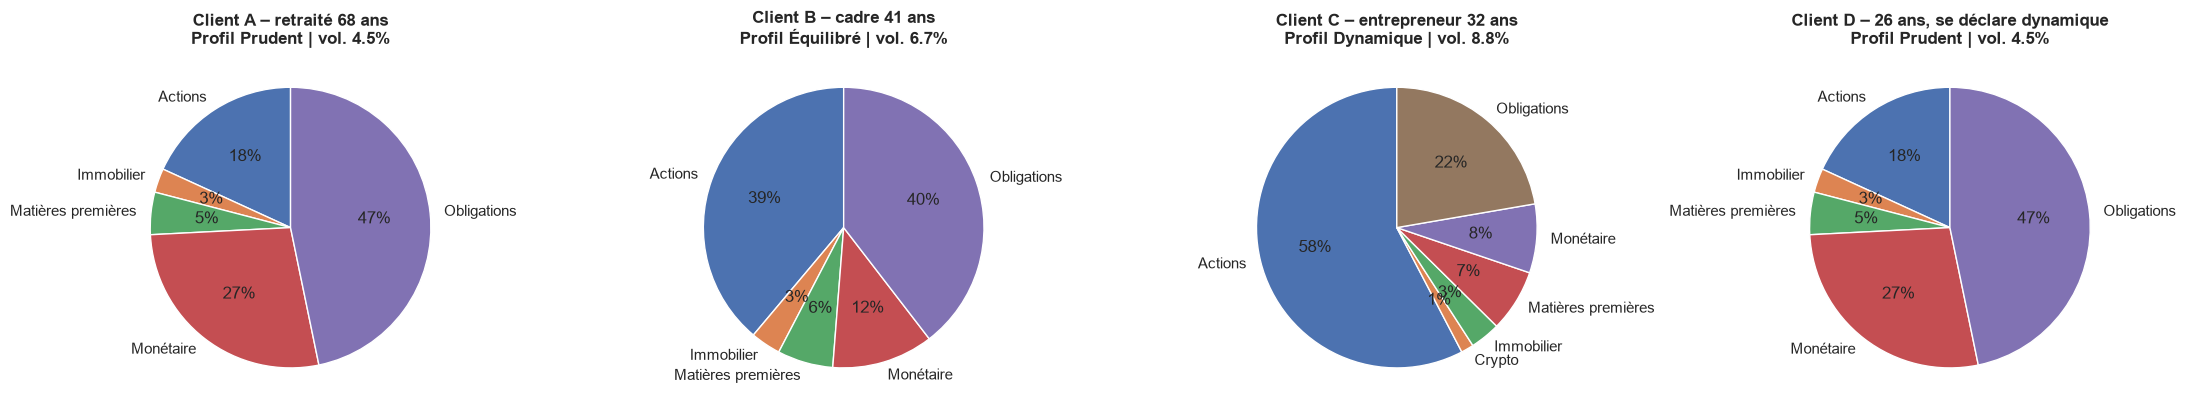

In [56]:
res_d = demo["D – 26 ans, se déclare dynamique"]
print(res_d["explanation"])
print("\nJournal des échanges (client D) :")
display(res_d["log"])

alloc_tab = pd.DataFrame({n: r["weights"] for n, r in demo.items()}).fillna(0)
alloc_tab = alloc_tab[(alloc_tab > 0.005).any(axis=1)]
alloc_tab.insert(0, "Classe", alloc_tab.index.map(ASSET_CLASS))
display(alloc_tab.sort_values("Classe").style.format({c: "{:.1%}" for c in demo}))
fig, axes = plt.subplots(1, len(demo), figsize=(5.5 * len(demo), 5))
for ax, (n, r) in zip(axes, demo.items()):
    ex = pd.Series(r["metrics"]["expositions"])
    ex = ex[ex > 0.005]
    ax.pie(ex, labels=ex.index, autopct="%1.0f%%", startangle=90)
    ax.set_title(f"Client {n}\nProfil {r['profile']} | vol. {r['metrics']['vol_ex_ante']:.1%}")
plt.tight_layout()
savefig("17_demo_allocations")
plt.show()

**Lecture** : le client D se déclare dynamique (questionnaire), mais sa situation financière (revenu faible, patrimoine négatif, endettement) le rapproche des ménages prudents : le profil est ramené au plus prudent des deux et une **alerte** est adressée au conseiller. Le journal montre la séquence complète des échanges entre agents, y compris la décision du garde-fou de l'agent Prévision : ses prévisions sont affichées à titre indicatif, mais n'entrent pas dans l'allocation.

**À noter** : à la date de la démonstration, le marché est en régime **Stress** (volatilité élevée). La cible de risque de chaque profil est donc réduite, ce qui explique des volatilités ex ante inférieures aux cibles nominales (6 %, 10 %, 16 %). L'intensité de cette réduction sera choisie sur la période de validation en section 7.

### 6.4 Vérification de la propriété de Black-Litterman
Sans vue ($\alpha = 0$), avec l'aversion de base, une cible de volatilité non contraignante et sans portefeuille précédent, l'optimiseur doit retrouver **exactement** l'allocation de référence $w_{ref}$ : on vérifie l'écart maximal, en points de pourcentage, à plusieurs dates. En régime de stress (aversion plus forte, cible de volatilité plus basse), le portefeuille s'écarte au contraire **volontairement** de la référence, vers moins de risque.

In [57]:
bl_rows = []
for d in [pd.Timestamp("2019-06-28"), pd.Timestamp("2022-06-30"), last_date]:
    d = prices.index[prices.index <= d][-1]
    R = returns.loc[:d].tail(LOOKBACK_COV)
    R = R.loc[:, R.notna().mean() >= 0.9]
    cov_d = RiskAgent().estimate(R)
    for prof in PROFILE_CLASSES:
        c = PROFILE_CONSTRAINTS[prof]
        w_ref = PortfolioOrchestrator.benchmark_weights(prof, list(cov_d.index))
        pi = pd.Series(c["risk_aversion"] * cov_d.values @ w_ref.values, index=cov_d.index)
        w_a = AllocationAgent().optimize(pi, cov_d, c, 10.0, c["risk_aversion"], None)
        m_s = REGIME_MULTIPLIER_GRID["modérée"]["Stress"]
        w_b = AllocationAgent().optimize(pi, cov_d, c, c["target_vol"] * m_s, c["risk_aversion"] / m_s, None)
        bl_rows.append({"date": d.date(), "profil": prof, "vol. de la référence": float(np.sqrt(w_ref @ cov_d @ w_ref)),
                        "cible de vol.": c["target_vol"], "écart max (propriété)": (w_a - w_ref).abs().max(),
                        "écart max (régime Stress)": (w_b - w_ref).abs().max()})
bl_check = pd.DataFrame(bl_rows).set_index(["date", "profil"])
bl_check.to_csv(RESULTS_DIR / "verification_black_litterman.csv")
assert bl_check["écart max (propriété)"].max() < 0.005, "La propriété de Black-Litterman n'est pas vérifiée"
bl_check.style.format("{:.2%}")

### 6.5 Allocations de référence fondées uniquement sur le risque
Pour juger l'agent Allocation, on calcule à la même date trois allocations qui n'utilisent **aucune prévision de rendement** :
- **Parité de risque** (*Equal Risk Contribution*) : chaque actif contribue autant au risque total, $RC_i = w_i(\Sigma w)_i/\sigma_p$ égales.
- **HRP** (*Hierarchical Risk Parity*) : les actifs sont regroupés par **classification hiérarchique** (comme la CAH, sur la distance $d_{ij}=\sqrt{\tfrac12(1-\rho_{ij})}$), puis le risque est réparti récursivement entre les groupes. Robuste, car il n'inverse pas la matrice de covariance.
- **1/N** : poids égaux.

Chacune est ramenée à la volatilité cible du profil en la mélangeant avec la poche monétaire (SHY), pour comparer **à risque égal**.

In [58]:
R_last = returns.loc[:last_date].tail(LOOKBACK_COV)
cov_last = ledoit_wolf_cov(R_last)
refs = {"Parité de risque": risk_parity(cov_last), "HRP": hrp(cov_last),
        "1/N": pd.Series(1 / len(cov_last), index=cov_last.index)}
rows_ref = []
for prof in PROFILE_CLASSES:
    tv = PROFILE_CONSTRAINTS[prof]["target_vol"]
    r_ma = orchestrator.recommend(last_date, prices, panel, mkt_feat, profile=prof, explain=False)
    cands_w = {"Multi-agent": r_ma["weights"], **{k: to_target_vol(w, cov_last, tv) for k, w in refs.items()}}
    for nom, w in cands_w.items():
        w = w.reindex(cov_last.index).fillna(0)
        cls = w.groupby(w.index.map(ASSET_CLASS)).sum()
        rows_ref.append({"profil": prof, "stratégie": nom, "vol. ex ante": float(np.sqrt(w @ cov_last.values @ w)),
                         "Actions + immo.": cls.get("Actions", 0) + cls.get("Immobilier", 0),
                         "Obligations": cls.get("Obligations", 0), "Monétaire": cls.get("Monétaire", 0),
                         "Matières premières": cls.get("Matières premières", 0), "Crypto": cls.get("Crypto", 0),
                         "nb lignes > 1 %": int((w > 0.01).sum())})
ref_tab = pd.DataFrame(rows_ref).set_index(["profil", "stratégie"])
display(ref_tab.style.format({c: "{:.1%}" for c in ref_tab.columns if c != "nb lignes > 1 %"}))
chrono("6. Système multi-agent")

⏱ 6. Système multi-agent : 9 s (cumul 7.4 min)


**Lecture** : à risque égal, les allocations fondées uniquement sur le risque (parité de risque, HRP) sont dominées par les obligations et le monétaire, qui sont les actifs les moins volatils. L'agent Allocation, qui part de l'allocation stratégique du profil, conserve davantage d'actions pour les profils Équilibré et Dynamique, conformément à leur objectif de croissance. Le backtest de la section 7 dira laquelle de ces approches a le mieux fonctionné hors échantillon.

## 7. Backtest walk-forward sur la période de test (2022 → fin)

### 7.1 Protocole (aucune information future)
- **Rebalancement mensuel** (dernier jour de bourse du mois) sur toute la période de test.
- **Covariance** estimée sur les 252 derniers jours ; **coûts de transaction** de 10 points de base par unité échangée.
- Si l'agent Prévision est activé, son modèle est **ré-entraîné chaque 1er janvier** avec les seules cibles connues à cette date (fenêtre croissante + embargo).
- Deux réglages ne sont pas appris par un modèle : la **pénalité de rotation γ** et l'**intensité de la réduction du risque en régime de stress**. Ils sont choisis sur la **validation 2020-2021**, jamais sur le test.

**Stratégies comparées**

| Stratégie | Type | Niveau de risque |
|---|---|---|
| **Multi-agent** (par profil) | Système proposé | cible du profil |
| Référence stratégique (par profil) | Allocation de référence du profil, rebalancée chaque mois, sans optimisation ni régime | proche de la cible |
| 1/N à volatilité cible (par profil) | Poids égaux mélangés avec la poche monétaire pour ne pas dépasser la cible | ≤ cible |
| Parité de risque à volatilité cible (par profil) | Contributions au risque égales, puis même mélange | ≤ cible |
| HRP à volatilité cible (par profil) | Parité de risque hiérarchique, puis même mélange | ≤ cible |
| 1/N, 60/40, variance minimale, Markowitz historique | Références classiques (un seul portefeuille) | libre |

Les références « à volatilité cible » permettent une comparaison **à risque comparable** : comparer le profil Prudent (cible 6 %) au 1/N brut (≈ 12 % de volatilité) ne serait pas équitable. **Limite** : sans emprunt (pas de levier), on peut seulement *réduire* le risque d'un portefeuille en ajoutant du monétaire, pas l'augmenter. La parité de risque et HRP, naturellement peu risquées (≈ 5 à 7 %), restent donc **en dessous** des cibles des profils Équilibré (10 %) et Dynamique (16 %). Pour ces profils, la comparaison porte sur le **ratio de Sharpe** (rendement par unité de risque) plutôt que sur le rendement brut.

In [59]:
from src.backtest import (perf_metrics, simulate, equal_weight, sixty_forty, min_variance, markowitz_historical,
                          rebalance_dates, vol_targeted_equal_weight)

emb = pd.Timedelta(days=EMBARGO_DAYS)
panel_dates = set(panel.index.get_level_values("date"))


def forecast_model_trained_until(cutoff):
    # Modèle de prévision entraîné avec les seules cibles connues à la date `cutoff`
    d_all = panel_s.index.get_level_values("date")
    data = panel_s[d_all <= cutoff - emb]
    return build_forecast_model(best_fc_name).fit(data[FEATS], data["target_reg"])


def run_multi_agent(dates, prof, reg_bundle, fc_bundle):
    orch = PortfolioOrchestrator(None, reg_bundle, fc_bundle)
    W_, prev_ = {}, None
    for d in dates:
        r = orch.recommend(d, prices, panel, mkt_feat, profile=prof, prev_w=prev_, explain=False)
        W_[d], prev_ = r["weights"], r["weights"]
    return W_

### 7.2 Choix des réglages sur la validation (2020-2021)
Grille : γ ∈ {0,5 ; 2 ; 5 ; 10} × réduction du risque en régime de stress {aucune, légère, modérée, forte} (cible de volatilité × 1,00 / 0,90 / 0,75 / 0,60 en régime Stress). Critère : **ratio de Sharpe moyen des trois profils** sur 2020-2021. Le modèle de prévision éventuel est celui entraîné sur la seule période d'entraînement.

In [60]:
val_reb = [d for d in rebalance_dates(prices.index, pd.Timestamp(TRAIN_END) - pd.Timedelta(days=7),
                                      pd.Timestamp(VAL_END) - emb) if d in panel_dates]
fc_val_bundle = {**forecast_bundle, "pipeline": build_forecast_model(best_fc_name).fit(tr[FEATS], tr["target_reg"])}
gammas = [0.5, 2.0, 5.0, 10.0] if not QUICK_RUN else [2.0, 10.0]
mult_grid = REGIME_MULTIPLIER_GRID if not QUICK_RUN else {k: REGIME_MULTIPLIER_GRID[k] for k in ("aucune", "modérée")}
cal_rows = {}
for mult_name, mult in mult_grid.items():
    for gamma in gammas:
        for prof in PROFILE_CLASSES:
            Wv = run_multi_agent(val_reb, prof, {**regime_bundle, "vol_multiplier": mult},
                                 {**fc_val_bundle, "turnover_penalty": gamma})
            rv, to_v = simulate(Wv, returns.loc[:VAL_END])
            m = perf_metrics(rv, rf_daily, to_v)
            cal_rows[(mult_name, gamma, prof)] = {"Sharpe": m["Sharpe"], "Max drawdown": m["Max drawdown"],
                                                  "Rotation annuelle": m["Rotation annuelle"]}
cal_tab = pd.DataFrame(cal_rows).T
cal_tab.index.names = ["réduction du risque", "γ", "profil"]
cal_summary = cal_tab.groupby(level=["réduction du risque", "γ"]).mean().sort_values("Sharpe", ascending=False)
best_mult_name, TURNOVER_GAMMA = cal_summary["Sharpe"].idxmax()
TURNOVER_GAMMA = float(TURNOVER_GAMMA)
regime_bundle["vol_multiplier"] = mult_grid[best_mult_name]
regime_bundle["vol_multiplier_name"] = best_mult_name
forecast_bundle["turnover_penalty"] = TURNOVER_GAMMA
cal_tab.to_csv(RESULTS_DIR / "choix_reglages_validation.csv")
RESULTS["reglages_validation"] = cal_summary
display(cal_summary.style.format({"Sharpe": "{:.3f}", "Max drawdown": "{:.2%}", "Rotation annuelle": "{:.2f}"}))
print(f"Réglages retenus sur la validation : réduction du risque « {best_mult_name} » "
      f"{mult_grid[best_mult_name]} ; γ = {TURNOVER_GAMMA}")

Réglages retenus sur la validation : réduction du risque « aucune » {'Calme': 1.0, 'Neutre': 1.0, 'Stress': 1.0} ; γ = 0.5


### 7.3 Simulation sur le test
Les réglages sont maintenant **figés**. On calcule, à chaque fin de mois du test, les allocations de toutes les stratégies, puis on simule leur valeur jour par jour (les poids dérivent avec les prix entre deux rebalancements).

In [61]:
test_start = pd.Timestamp(VAL_END) + pd.Timedelta(days=1)
reb = [d for d in rebalance_dates(prices.index, test_start - pd.Timedelta(days=7), last_date) if d in panel_dates]
print(f"{len(reb)} rebalancements : {reb[0].date()} → {reb[-1].date()}")

yearly_fc = {}


def fc_bundle_at(d):
    if not FC_ACTIVE:
        return forecast_bundle
    if d.year not in yearly_fc:
        yearly_fc[d.year] = {**forecast_bundle, "pipeline": forecast_model_trained_until(pd.Timestamp(f"{d.year}-01-01"))}
    return yearly_fc[d.year]


W = {}
for prof in PROFILE_CLASSES:
    variants = [("Multi-agent", False)] + ([("Multi-agent sans ML", True)] if FC_ACTIVE else [])
    for variant, sans_ml in variants:
        orch_t = PortfolioOrchestrator(None, regime_bundle, None)
        W_v, prev_ = {}, None
        for d in reb:
            fb = fc_bundle_at(d)
            orch_t.forecast_bundle = {**fb, "ic": 0.0} if sans_ml else fb
            orch_t.turnover_penalty = TURNOVER_GAMMA
            r = orch_t.recommend(d, prices, panel, mkt_feat, profile=prof, prev_w=prev_, explain=False)
            W_v[d], prev_ = r["weights"], r["weights"]
        W[f"{variant} – {prof}"] = W_v

for d in reb:
    window = returns.loc[:d].tail(LOOKBACK_COV)
    avail = window.columns[window.notna().mean() >= 0.9].tolist()
    cov_d = ledoit_wolf_cov(window[avail])
    rp_d, hrp_d = risk_parity(cov_d), hrp(cov_d)
    W.setdefault("Équipondérée 1/N", {})[d] = equal_weight(avail)
    W.setdefault("60/40", {})[d] = sixty_forty(avail)
    W.setdefault("Variance minimale", {})[d] = min_variance(window[avail])
    W.setdefault("Markowitz historique", {})[d] = markowitz_historical(window[avail])
    for prof in PROFILE_CLASSES:
        tv = PROFILE_CONSTRAINTS[prof]["target_vol"]
        W.setdefault(f"Référence stratégique – {prof}", {})[d] = PortfolioOrchestrator.benchmark_weights(prof, avail)
        W.setdefault(f"1/N vol. cible – {prof}", {})[d] = vol_targeted_equal_weight(window[avail], tv)
        W.setdefault(f"Parité de risque vol. cible – {prof}", {})[d] = to_target_vol(rp_d, cov_d, tv)
        W.setdefault(f"HRP vol. cible – {prof}", {})[d] = to_target_vol(hrp_d, cov_d, tv)
print(f"{len(W)} stratégies simulées")
chrono("7a. Backtest : réglages et simulation")

60 rebalancements : 2021-12-31 → 2026-11-20


19 stratégies simulées
⏱ 7a. Backtest : réglages et simulation : 358 s (cumul 13.3 min)


### 7.4 Performances sur le test
Mesures : rendement et volatilité annualisés, **ratio de Sharpe** (rendement excédentaire au taux sans risque / volatilité), **Sortino** (ne pénalise que la volatilité à la baisse), **perte maximale** (*max drawdown*), **Calmar** (rendement / perte maximale), VaR journalière à 95 %, **rotation annuelle** (somme des poids échangés par an).

In [62]:
bt_returns, bt_rows = {}, {}
for name, wd in W.items():
    r, turnover = simulate(wd, returns)
    bt_returns[name] = r
    bt_rows[name] = perf_metrics(r, rf_daily, turnover)
bt_returns = pd.DataFrame(bt_returns)
bt_table = pd.DataFrame(bt_rows).T
bt_table.to_csv(RESULTS_DIR / "backtest_performances_test.csv")
bt_returns.to_csv(RESULTS_DIR / "backtest_rendements_quotidiens.csv")
RESULTS["backtest"] = bt_table
ratio_cols = ("Sharpe", "Sortino", "Calmar", "Rotation annuelle")
fmt = {c: "{:.2%}" for c in bt_table.columns if c not in ratio_cols} | {c: "{:.2f}" for c in ratio_cols}
display(bt_table[[c for c in bt_table.columns]].style.format(fmt).background_gradient(subset=["Sharpe"], cmap="RdYlGn"))

,Rendement annualisé,Volatilité annualisée,Sharpe,Sortino,Max drawdown,Calmar,VaR 95% (jour),% jours positifs,Rotation annuelle
Multi-agent – Prudent,2.17%,6.27%,-0.26,-0.36,-14.96%,0.14,0.62%,53.79%,0.93
Multi-agent – Équilibré,4.73%,9.65%,0.12,0.16,-18.20%,0.26,0.93%,54.60%,0.74
Multi-agent – Dynamique,8.10%,13.35%,0.35,0.48,-19.94%,0.41,1.32%,53.46%,0.67
Équipondérée 1/N,7.09%,11.67%,0.30,0.42,-19.57%,0.36,1.10%,54.20%,0.60
60/40,5.11%,11.15%,0.15,0.21,-20.95%,0.24,1.10%,52.16%,0.39
Variance minimale,1.32%,4.86%,-0.53,-0.75,-13.67%,0.10,0.50%,53.38%,1.11
Markowitz historique,16.95%,19.50%,0.70,0.88,-23.16%,0.73,1.88%,54.60%,6.16
Référence stratégique – Prudent,3.17%,7.36%,-0.08,-0.11,-16.15%,0.20,0.76%,54.03%,0.46
1/N vol. cible – Prudent,4.76%,6.90%,0.13,0.18,-12.93%,0.37,0.69%,54.52%,0.81
Parité de risque vol. cible – Prudent,4.13%,6.57%,0.04,0.06,-14.11%,0.29,0.63%,55.66%,0.90


**Comparaison à risque égal, profil par profil** : c'est le tableau qui permet de juger le système.

In [63]:
cols_rc = ["Rendement annualisé", "Volatilité annualisée", "Sharpe", "Max drawdown", "Rotation annuelle"]
strat_par_profil = ["Multi-agent", "Multi-agent sans ML", "Référence stratégique", "1/N vol. cible",
                    "Parité de risque vol. cible", "HRP vol. cible"]
rc = []
for prof in PROFILE_CLASSES:
    for s in strat_par_profil:
        key = f"{s} – {prof}"
        if key in bt_table.index:
            rc.append(bt_table.loc[key, cols_rc].rename((prof, s)))
risk_comp = pd.DataFrame(rc)
risk_comp.index = pd.MultiIndex.from_tuples(risk_comp.index, names=["profil", "stratégie"])
risk_comp.to_csv(RESULTS_DIR / "backtest_risque_comparable.csv")
RESULTS["risque_comparable"] = risk_comp
risk_comp.style.format({k: v for k, v in fmt.items() if k in risk_comp.columns})

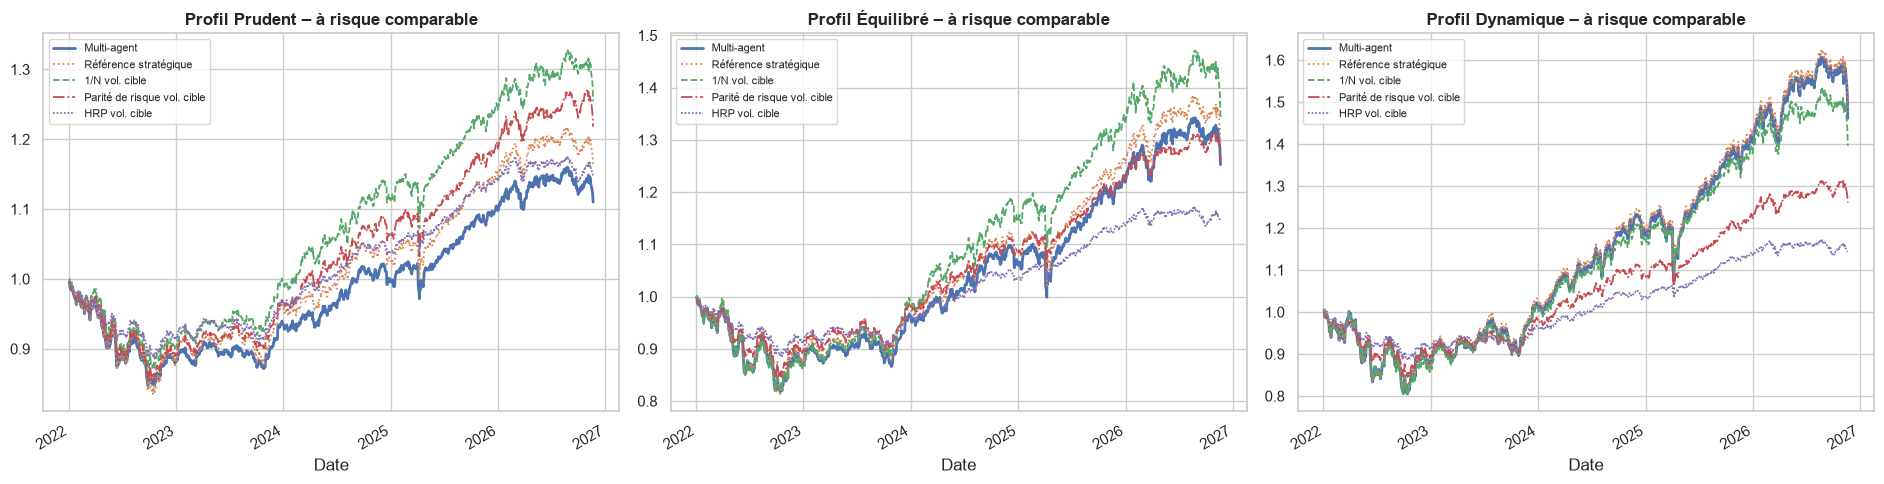

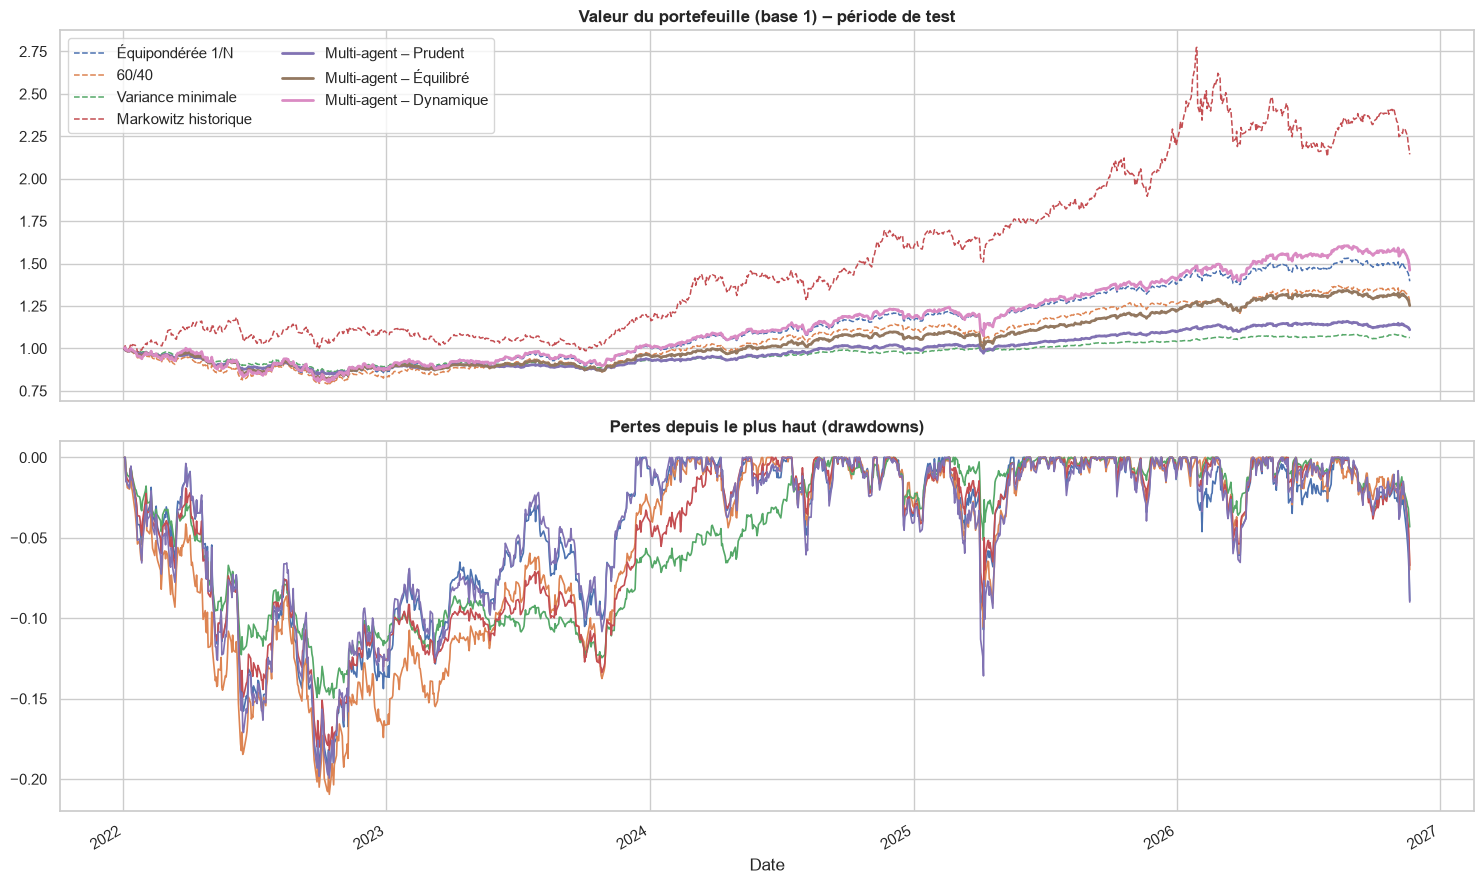

In [64]:
wealth = (1 + bt_returns.fillna(0)).cumprod()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, prof in zip(axes, PROFILE_CLASSES):
    for s, style in (("Multi-agent", "-"), ("Référence stratégique", ":"), ("1/N vol. cible", "--"),
                     ("Parité de risque vol. cible", "-."), ("HRP vol. cible", (0, (1, 1)))):
        wealth[f"{s} – {prof}"].plot(ax=ax, ls=style, lw=2 if s == "Multi-agent" else 1.3, label=s)
    ax.set_title(f"Profil {prof} – à risque comparable")
    ax.legend(fontsize=8)
plt.tight_layout()
savefig("18b_backtest_risque_comparable")
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
bench = ["Équipondérée 1/N", "60/40", "Variance minimale", "Markowitz historique"]
for c in bench:
    wealth[c].plot(ax=axes[0], ls="--", lw=1.1)
for prof in PROFILE_CLASSES:
    wealth[f"Multi-agent – {prof}"].plot(ax=axes[0], lw=2)
axes[0].set_title("Valeur du portefeuille (base 1) – période de test")
axes[0].legend(ncol=2)
dd = wealth / wealth.cummax() - 1
for c in bench[:2] + [f"Multi-agent – {p}" for p in PROFILE_CLASSES]:
    dd[c].plot(ax=axes[1], lw=1.2)
axes[1].set_title("Pertes depuis le plus haut (drawdowns)")
plt.tight_layout()
savefig("18_backtest_valeur_drawdown")
plt.show()

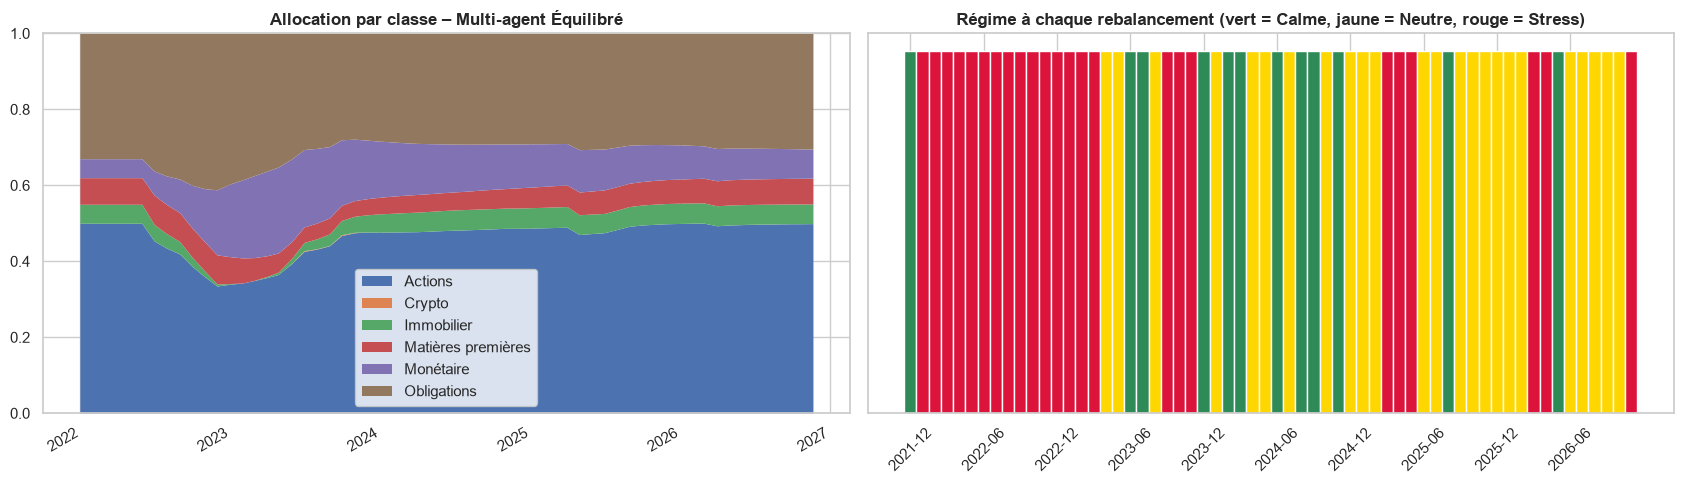

In [65]:
wq = pd.DataFrame(W["Multi-agent – Équilibré"]).T.fillna(0)
wq_cls = wq.T.groupby(wq.columns.map(ASSET_CLASS)).sum().T
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
wq_cls.plot.area(ax=axes[0], linewidth=0)
axes[0].set_ylim(0, 1)
axes[0].set_title("Allocation par classe – Multi-agent Équilibré")
reg_at = reg_series.reindex(wq.index, method="ffill")
axes[1].bar(range(len(reg_at)), 1, color=reg_at.map(colors), width=1)
axes[1].set_xticks(range(0, len(reg_at), 6))
axes[1].set_xticklabels([d.strftime("%Y-%m") for d in reg_at.index[::6]], rotation=45)
axes[1].set_yticks([])
axes[1].set_title("Régime à chaque rebalancement (vert = Calme, jaune = Neutre, rouge = Stress)")
plt.tight_layout()
savefig("19_backtest_allocations")
plt.show()

### 7.5 Significativité statistique : bootstrap par blocs
Sur 4 à 5 ans, les écarts de ratio de Sharpe sont très bruités. On estime un intervalle de confiance à 95 % de la **différence de Sharpe** entre le système et chaque référence de même risque, par **bootstrap par blocs** : on rééchantillonne des blocs de 21 jours consécutifs, ce qui préserve l'autocorrélation et le regroupement de volatilité. Si l'intervalle contient 0, la différence n'est **pas statistiquement établie**.

In [66]:
def block_bootstrap_sharpe_diff(r1, r2, n_boot=2000 if not QUICK_RUN else 300, block=21, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    pair = pd.concat([r1, r2], axis=1).dropna()
    df = pair.sub(rf_daily.reindex(pair.index).fillna(0), axis=0).values      # rendements excédentaires
    n = len(df)
    nb = int(np.ceil(n / block))
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block, nb)])[:n]
        s = df[idx]
        sh = s.mean(0) / s.std(0) * np.sqrt(252)
        diffs.append(sh[0] - sh[1])
    diffs = np.array(diffs)
    obs = df.mean(0) / df.std(0) * np.sqrt(252)
    return {"diff. de Sharpe observée": obs[0] - obs[1], "IC 95 % bas": np.quantile(diffs, .025),
            "IC 95 % haut": np.quantile(diffs, .975), "P(diff ≤ 0)": (diffs <= 0).mean()}


sig = {}
for p in PROFILE_CLASSES:
    for ref in [s for s in strat_par_profil[1:] if f"{s} – {p}" in bt_returns]:
        sig[f"{p} : Multi-agent vs {ref}"] = block_bootstrap_sharpe_diff(bt_returns[f"Multi-agent – {p}"],
                                                                        bt_returns[f"{ref} – {p}"])
sig = pd.DataFrame(sig).T
sig["significatif (5 %)"] = np.where((sig["IC 95 % bas"] > 0) | (sig["IC 95 % haut"] < 0), "oui", "non")
sig.to_csv(RESULTS_DIR / "backtest_significativite.csv")
RESULTS["significativite"] = sig
display(sig)
chrono("7b. Backtest : résultats et significativité")

,diff. de Sharpe observée,IC 95 % bas,IC 95 % haut,P(diff ≤ 0),significatif (5 %)
Prudent : Multi-agent vs Référence stratégique,-0.1811,-0.3813,0.0616,0.9280,non
Prudent : Multi-agent vs 1/N vol. cible,-0.3930,-0.7069,-0.1275,0.9965,oui
Prudent : Multi-agent vs Parité de risque vol. cible,-0.3050,-0.5488,-0.1172,0.9990,oui
Prudent : Multi-agent vs HRP vol. cible,-0.0360,-0.2352,0.2531,0.5010,non
Équilibré : Multi-agent vs Référence stratégique,-0.0574,-0.1511,0.0624,0.7890,non
Équilibré : Multi-agent vs 1/N vol. cible,-0.1313,-0.3712,0.0535,0.9240,non
Équilibré : Multi-agent vs Parité de risque vol. cible,-0.0242,-0.2252,0.2031,0.5650,non
Équilibré : Multi-agent vs HRP vol. cible,0.3565,0.0367,0.7901,0.0160,oui
Dynamique : Multi-agent vs Référence stratégique,-0.0103,-0.0510,0.0423,0.5900,non
Dynamique : Multi-agent vs 1/N vol. cible,0.0481,-0.0981,0.1906,0.2655,non


⏱ 7b. Backtest : résultats et significativité : 12 s (cumul 13.5 min)


**Lecture**
- **Adéquation aux profils** : le risque réalisé croît bien du profil Prudent (≈ 6 %) au profil Dynamique (≈ 13 %), dans le budget de chaque profil. C'est la première mission du système, et elle est remplie.
- **Profil Dynamique** : le multi-agent fait aussi bien que sa référence stratégique et que le 1/N à volatilité cible (écarts de Sharpe non significatifs).
- **Profil Équilibré** : légèrement en dessous de la référence stratégique et du 1/N à volatilité cible, sans que l'écart soit significatif.
- **Profil Prudent** : c'est le point faible. Il fait **significativement moins bien** que le 1/N à volatilité cible et que la parité de risque. Sur 2022-2026, les portefeuilles prudents qui détenaient davantage d'actions diversifiées et moins d'obligations ont mieux traversé la hausse des taux. La contrainte de part défensive minimale (50 %), même élargie au monétaire, a pesé.
- Les écarts significatifs **favorables** au multi-agent (face à HRP) sont à relativiser : HRP est nettement moins risqué (≈ 4,5 % de volatilité), donc la comparaison n'est pas à risque égal.

**En résumé** : sur cette période, l'optimisation n'ajoute pas de rendement par rapport à des règles simples de même risque, ce qui est cohérent avec la littérature (DeMiguel et al., 2009). La valeur du système tient à l'adéquation au profil, au contrôle du risque et à l'explication des recommandations.

## 8. Agent d'apprentissage par renforcement (PPO)

### 8.1 Formulation (cours 1, « exemple en gestion de portefeuille »)
Un **agent** interagit avec un **environnement** : à chaque pas de temps il observe un état $s_t$, choisit une action $a_t$ selon sa politique $\pi(a\mid s)$, reçoit une récompense $r_t$ et un nouvel état $s_{t+1}$. Il cherche la politique qui maximise la **récompense cumulée actualisée** $G_t = \sum_{k\ge0}\gamma^k r_{t+k}$, où $\gamma\in[0,1[$ est le facteur d'actualisation.

| Composante | Dans ce projet |
|---|---|
| Agent | le gestionnaire de portefeuille automatisé (réseau de neurones 2 × 64) |
| Environnement | le marché historique, rejoué **mois par mois** (environnement `Gymnasium` personnalisé, `src/rl_env.py`) |
| État $s_t$ | 5 variables de régime + 3 probabilités $\gamma_{ik}$ du GMM + rendements à 1 et 3 mois et volatilité à 3 mois de chaque classe + poids actuels (25 nombres) |
| Action $a_t$ | allocation entre **5 classes d'actifs** (actions, immobilier, obligations, monétaire, matières premières), réparties à parts égales dans chaque classe |
| Récompense $r_t$ | $\sum_j R_j - \frac{\lambda}{2}\sum_j R_j^2 - c\,\lVert w_t - w_{t-1}\rVert_1$ : rendement du mois − pénalité de risque (aversion λ du profil) − coûts de transaction |
| Politique $\pi$ | apprise par **PPO** (*Proximal Policy Optimization*, bibliothèque `stable-baselines3`) |

**PPO** appartient aux méthodes **fondées sur la politique** (cours 1) : un réseau de neurones de poids θ reçoit l'état et renvoie directement une distribution sur les actions $\pi(a\mid s;\theta)$. Le dilemme **exploration / exploitation** est géré par le caractère aléatoire de cette distribution pendant l'entraînement (l'agent essaie des allocations variées), puis la politique est utilisée de façon déterministe en évaluation.

**Contraintes du profil** : l'action brute (5 nombres) passe par un softmax (poids positifs de somme 1), puis est **projetée** sur l'ensemble des poids admissibles du profil (plafond actions, part défensive minimale, plafonds monétaire et matières premières). L'agent ne peut donc jamais proposer un portefeuille interdit.

**Protocole honnête** : entraînement sur 2011-2019 (épisodes de 24 mois tirés au hasard), choix entre plusieurs graines aléatoires sur la **validation 2020-2021**, puis **une seule évaluation** sur le test, comparée aux stratégies de la section 7.

**Limites assumées** : environ 108 mois d'entraînement seulement, c'est très peu pour l'apprentissage par renforcement ; le Bitcoin est exclu de l'environnement (pas d'historique avant 2014) ; le **budget de volatilité** du profil n'est pas une contrainte stricte comme dans l'agent Allocation, il est seulement **pénalisé** dans la récompense (terme $\frac{\lambda}{2}\sum_j R_j^2$) : la volatilité réalisée peut donc dépasser la cible.

In [67]:
from stable_baselines3 import PPO
from src.rl_env import class_returns, PortfolioEnv, rollout, RL_CLASSES

cls_ret = class_returns(returns, ASSET_CLASS)
Z_state = pd.DataFrame(reg_scaler.transform(mkt_feat[reg_cols].ffill().fillna(M_tr.median())),
                       index=mkt_feat.index, columns=reg_cols)
state_feats = pd.concat([Z_state, proba_all], axis=1)
RL_STEPS = 3_000 if QUICK_RUN else 30_000
RL_SEEDS = [0] if QUICK_RUN else [0, 1]
rl_start, rl_val, rl_test = "2011-03-01", ("2020-01-01", VAL_END), (reb[0], last_date)


def make_env(prof, start, end, random_start=True, seed=0):
    c = PROFILE_CONSTRAINTS[prof]
    return PortfolioEnv(cls_ret, state_feats, c, c["risk_aversion"], start, end, random_start=random_start, seed=seed)


rl_models, rl_val_rows = {}, {}
for prof in PROFILE_CLASSES:
    for seed in RL_SEEDS:
        t0 = time.time()
        model = PPO("MlpPolicy", make_env(prof, rl_start, TRAIN_END, seed=seed), gamma=0.9, n_steps=256, batch_size=64,
                    learning_rate=3e-4, ent_coef=0.0, seed=seed, verbose=0,
                    policy_kwargs={"net_arch": [64, 64]}).learn(RL_STEPS)
        r_val, _ = rollout(model, make_env(prof, *rl_val, random_start=False))
        m = perf_metrics(r_val, rf_daily)
        rl_val_rows[(prof, seed)] = {"Sharpe validation": m["Sharpe"], "Rendement annualisé": m["Rendement annualisé"],
                                     "Volatilité": m["Volatilité annualisée"], "durée (s)": time.time() - t0}
        rl_models[(prof, seed)] = model
        print(f"✓ PPO {prof:<10} graine {seed} : Sharpe validation = {m['Sharpe']:.2f} ({time.time() - t0:.0f} s)")
rl_val_tab = pd.DataFrame(rl_val_rows).T
rl_val_tab.index.names = ["profil", "graine"]
best_seed = rl_val_tab["Sharpe validation"].groupby(level="profil").idxmax()
display(rl_val_tab)

✓ PPO Prudent    graine 0 : Sharpe validation = 0.73 (99 s)


✓ PPO Prudent    graine 1 : Sharpe validation = 0.68 (91 s)


✓ PPO Équilibré  graine 0 : Sharpe validation = 0.66 (84 s)


✓ PPO Équilibré  graine 1 : Sharpe validation = 0.64 (83 s)


✓ PPO Dynamique  graine 0 : Sharpe validation = 0.59 (73 s)


✓ PPO Dynamique  graine 1 : Sharpe validation = 0.62 (69 s)


Sharpe validation  Rendement annualisé  Volatilité  \
profil    graine                                                       
Prudent   0                  0.7258               0.0879      0.1241   
          1                  0.6827               0.0799      0.1204   
Équilibré 0                  0.6582               0.1153      0.1909   
          1                  0.6389               0.1141      0.1968   
Dynamique 0                  0.5902               0.1313      0.2677   
          1                  0.6150               0.1407      0.2727   

                  durée (s)  
profil    graine             
Prudent   0         98.6792  
          1         91.0195  
Équilibré 0         84.0774  
          1         83.4395  
Dynamique 0         72.9943  
          1         68.5529

### 8.2 Évaluation unique sur le test et comparaison

In [68]:
rl_rows, rl_returns, rl_weights = {}, {}, {}
for prof in PROFILE_CLASSES:
    model = rl_models[best_seed[prof]]
    r_te, w_te = rollout(model, make_env(prof, *rl_test, random_start=False))
    turnover = w_te.diff().abs().sum(1).sum() / (len(r_te) / 252)
    rl_returns[f"PPO – {prof}"], rl_weights[prof] = r_te, w_te
    model.save(MODELS_DIR / f"agent_rl_ppo_{prof}.zip")
for name, r in rl_returns.items():
    prof = name.split(" – ")[1]
    rl_rows[name] = perf_metrics(r, rf_daily, rl_weights[prof].diff().abs().sum(1).sum() / (len(r) / 252))
comp_rl = pd.concat([pd.DataFrame(rl_rows).T,
                     bt_table.loc[[f"{s} – {p}" for p in PROFILE_CLASSES
                                   for s in ("Multi-agent", "Référence stratégique", "1/N vol. cible")]]])
comp_rl = comp_rl.loc[[f"{s} – {p}" for p in PROFILE_CLASSES
                       for s in ("PPO", "Multi-agent", "Référence stratégique", "1/N vol. cible")]]
comp_rl.to_csv(RESULTS_DIR / "agent_rl_comparaison_test.csv")
RESULTS["rl_test"] = comp_rl
display(comp_rl[["Rendement annualisé", "Volatilité annualisée", "Sharpe", "Max drawdown", "Rotation annuelle"]]
        .style.format({"Sharpe": "{:.2f}", "Rotation annuelle": "{:.2f}", "Rendement annualisé": "{:.2%}",
                       "Volatilité annualisée": "{:.2%}", "Max drawdown": "{:.2%}"}))

sig_rl = {}
for p in PROFILE_CLASSES:
    for ref in ("Multi-agent", "Référence stratégique", "1/N vol. cible"):
        sig_rl[f"{p} : PPO vs {ref}"] = block_bootstrap_sharpe_diff(rl_returns[f"PPO – {p}"], bt_returns[f"{ref} – {p}"])
sig_rl = pd.DataFrame(sig_rl).T
sig_rl["significatif (5 %)"] = np.where((sig_rl["IC 95 % bas"] > 0) | (sig_rl["IC 95 % haut"] < 0), "oui", "non")
sig_rl.to_csv(RESULTS_DIR / "agent_rl_significativite.csv")
RESULTS["rl_significativite"] = sig_rl
display(sig_rl)

C:\Users\HP\AppData\Local\Temp\ipykernel_38200\44487541.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  turnover = w_te.diff().abs().sum(1).sum() / (len(r_te) / 252)
C:\Users\HP\AppData\Local\Temp\ipykernel_38200\44487541.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  turnover = w_te.diff().abs().sum(1).sum() / (len(r_te) / 252)


C:\Users\HP\AppData\Local\Temp\ipykernel_38200\44487541.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  turnover = w_te.diff().abs().sum(1).sum() / (len(r_te) / 252)
C:\Users\HP\AppData\Local\Temp\ipykernel_38200\44487541.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  rl_rows[name] = perf_metrics(r, rf_daily, rl_weights[prof].diff().abs().sum(1).sum() / (len(r) / 252))


,Rendement annualisé,Volatilité annualisée,Sharpe,Max drawdown,Rotation annuelle
PPO – Prudent,1.91%,8.46%,-0.20,-18.75%,3.62
Multi-agent – Prudent,2.17%,6.27%,-0.26,-14.96%,0.93
Référence stratégique – Prudent,3.17%,7.36%,-0.08,-16.15%,0.46
1/N vol. cible – Prudent,4.76%,6.90%,0.13,-12.93%,0.81
PPO – Équilibré,1.94%,11.39%,-0.12,-23.53%,5.64
Multi-agent – Équilibré,4.73%,9.65%,0.12,-18.20%,0.74
Référence stratégique – Équilibré,5.38%,10.47%,0.17,-18.64%,0.52
1/N vol. cible – Équilibré,6.20%,10.50%,0.25,-17.98%,0.95
PPO – Dynamique,1.67%,14.99%,-0.08,-28.35%,6.63
Multi-agent – Dynamique,8.10%,13.35%,0.35,-19.94%,0.67


,diff. de Sharpe observée,IC 95 % bas,IC 95 % haut,P(diff ≤ 0),significatif (5 %)
Prudent : PPO vs Multi-agent,0.0572,-0.2950,0.3573,0.4440,non
Prudent : PPO vs Référence stratégique,-0.1239,-0.3625,0.1107,0.8670,non
Prudent : PPO vs 1/N vol. cible,-0.3357,-0.7473,-0.0255,0.9840,oui
Équilibré : PPO vs Multi-agent,-0.2394,-0.5885,0.0690,0.9485,non
Équilibré : PPO vs Référence stratégique,-0.2968,-0.6118,0.0045,0.9735,non
Équilibré : PPO vs 1/N vol. cible,-0.3707,-0.8194,-0.0257,0.9825,oui
Dynamique : PPO vs Multi-agent,-0.4326,-0.8351,-0.1141,0.9935,oui
Dynamique : PPO vs Référence stratégique,-0.4429,-0.8241,-0.1261,0.9960,oui
Dynamique : PPO vs 1/N vol. cible,-0.3845,-0.8325,-0.0380,0.9850,oui


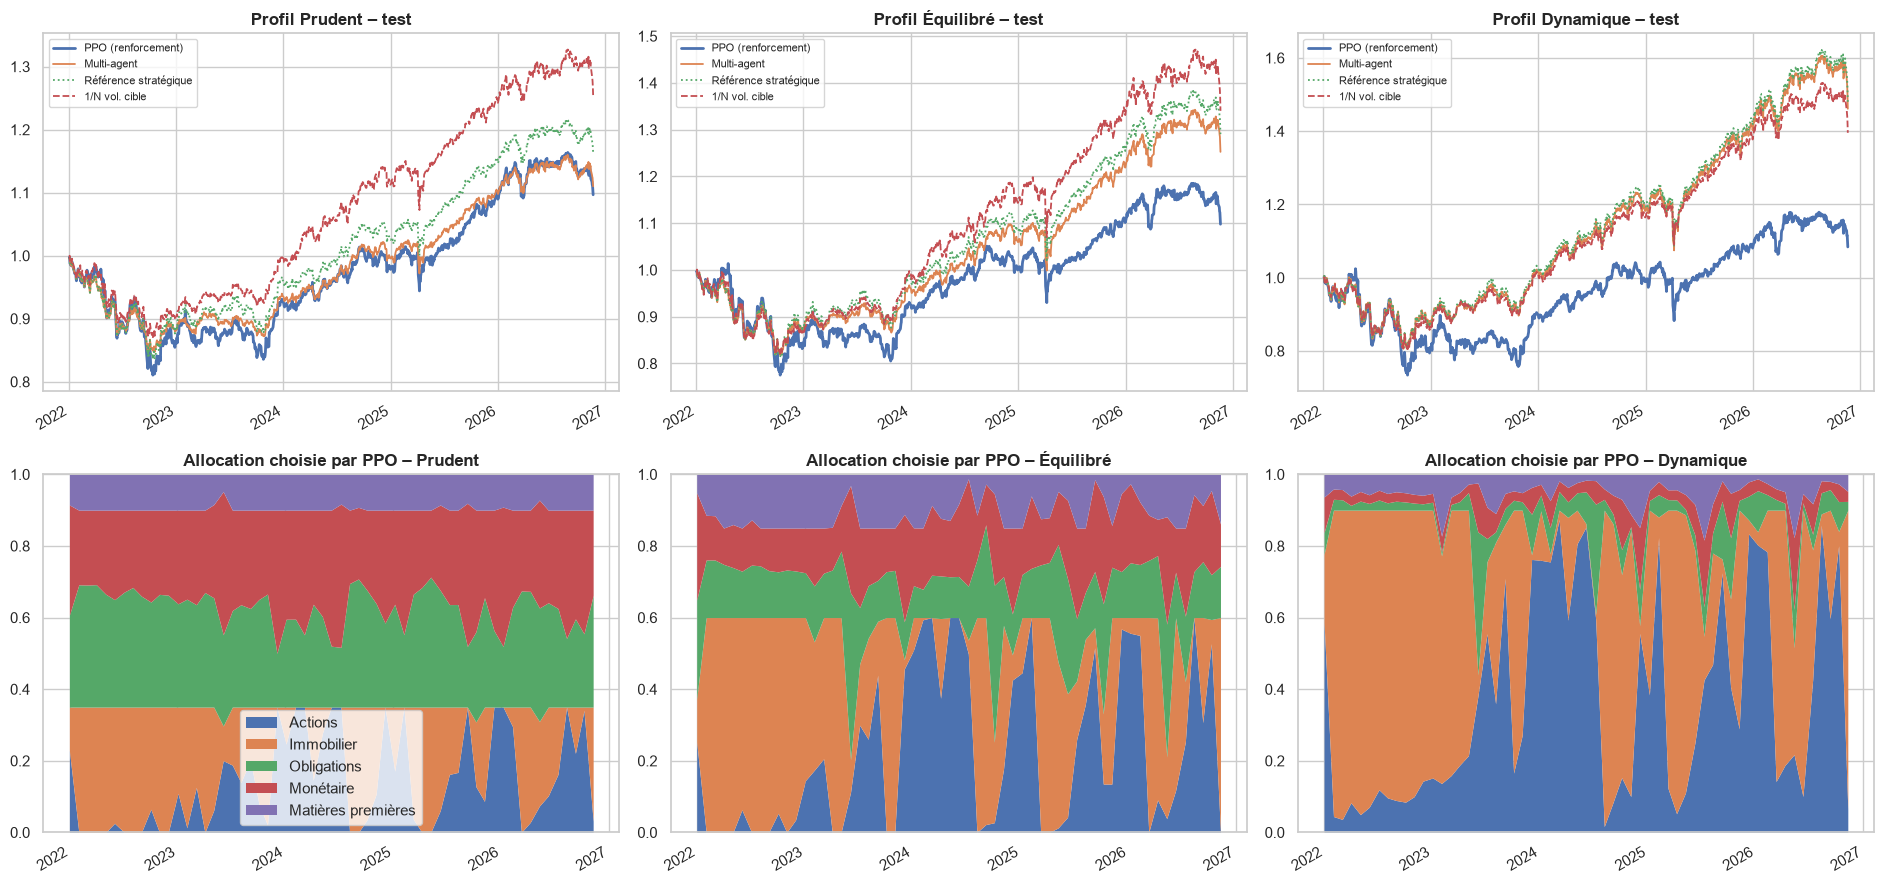

⏱ 8. Apprentissage par renforcement (PPO) : 507 s (cumul 22.0 min)


In [69]:
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for j, prof in enumerate(PROFILE_CLASSES):
    ax = axes[0, j]
    w_rl = (1 + rl_returns[f"PPO – {prof}"]).cumprod()
    w_rl.plot(ax=ax, lw=2, label="PPO (renforcement)")
    for s, style in (("Multi-agent", "-"), ("Référence stratégique", ":"), ("1/N vol. cible", "--")):
        (1 + bt_returns[f"{s} – {prof}"].reindex(w_rl.index).fillna(0)).cumprod().plot(ax=ax, ls=style, lw=1.3, label=s)
    ax.set_title(f"Profil {prof} – test")
    ax.legend(fontsize=8)
    rl_weights[prof].plot.area(ax=axes[1, j], linewidth=0, legend=(j == 0))
    axes[1, j].set_ylim(0, 1)
    axes[1, j].set_title(f"Allocation choisie par PPO – {prof}")
plt.tight_layout()
savefig("20_rl_ppo")
plt.show()
chrono("8. Apprentissage par renforcement (PPO)")

**Règle de décision (fixée à l'avance)** : l'agent PPO ne remplace l'optimiseur classique dans l'application que s'il le bat de façon **significative** (intervalle de confiance du bootstrap entièrement au-dessus de 0) pour un profil. Dans le cas contraire, il reste une **démonstration** de la méthode, et l'application garde l'agent Allocation fondé sur l'optimisation moyenne-variance, plus stable et plus facile à expliquer.

**Lecture** : l'agent PPO obtient de bons résultats sur la validation 2020-2021, mais ils ne se maintiennent pas sur le test : son ratio de Sharpe est négatif pour les trois profils. Il fait **significativement moins bien** que le 1/N à volatilité cible pour les trois profils, et que le multi-agent et la référence stratégique pour le profil Dynamique. Sa volatilité dépasse aussi la cible du profil, puisque le budget de risque n'est que pénalisé. C'est le symptôme classique d'un **surapprentissage** : environ 108 mois d'entraînement ne suffisent pas pour apprendre une politique robuste à un changement de contexte (hausse des taux de 2022). Conformément à la règle, l'application conserve l'optimiseur classique.

## 9. Sauvegarde des artefacts pour l'application

Étape 6 de la méthode du cours : une fois l'évaluation terminée et les choix figés, le modèle à **déployer** peut être ré-entraîné sur **toutes** les données disponibles (plus de données → estimation plus précise), avec les hyperparamètres et le seuil déjà choisis.
- **Agent Profil** : régression logistique ré-entraînée sur toute l'enquête SCF 2022 (même seuil de décision).
- **Agent Prévision** : modèle ré-entraîné avec toutes les cibles connues à la date des données (garde-fou inchangé).
- **Agents Régime et Alerte** : modèles ajustés sur 2011-2019, conservés tels quels (ce sont eux qui ont été validés).

In [70]:
profile_final = clone(profile_bundle["pipeline"]).fit(X_p, y_int)
joblib.dump({**profile_bundle, "pipeline": profile_final}, MODELS_DIR / "agent_profil.joblib")
joblib.dump(regime_bundle, MODELS_DIR / "agent_regime.joblib")
joblib.dump(alert_bundle, MODELS_DIR / "agent_alerte.joblib")
fc_final = {**forecast_bundle, "pipeline": forecast_model_trained_until(last_date + pd.Timedelta(days=366))}
joblib.dump(fc_final, MODELS_DIR / "agent_prevision.joblib")

recent_dates = panel.index.get_level_values("date").unique().sort_values()[-260:]
panel.loc[panel.index.get_level_values("date").isin(recent_dates)].to_csv(DATA_PROC / "panel_recent.csv")
mkt_feat.to_csv(DATA_PROC / "market_features.csv")
proba_all.to_csv(DATA_PROC / "regimes_probabilites.csv")
flags.to_csv(DATA_PROC / "anomalies.csv")

meta = {"date_donnees": str(last_date.date()), "mode_rapide": QUICK_RUN,
        "modele_profil": best_profile_name, "seuil_profil": THRESH,
        "modele_prevision": best_fc_name, "prevision_active": FC_ACTIVE, "IC_hors_pli": IC_VAL, "IC_utilise": IC_USED,
        "penalite_rotation": TURNOVER_GAMMA, "reduction_risque_regime": best_mult_name,
        "variables_prevision": FEATS, "top_variables": TOP_FEATURES, "alerte_min_votes": ALERT_MIN,
        "rl_graines_retenues": {p: int(best_seed[p][1]) for p in PROFILE_CLASSES}}
(MODELS_DIR / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Artefacts enregistrés :", sorted(p.name for p in MODELS_DIR.iterdir() if p.suffix in (".joblib", ".json", ".zip")))
chrono("9. Sauvegarde")

Artefacts enregistrés : ['agent_alerte.joblib', 'agent_prevision.joblib', 'agent_profil.joblib', 'agent_regime.joblib', 'agent_rl_ppo_Dynamique.zip', 'agent_rl_ppo_Prudent.zip', 'agent_rl_ppo_Équilibré.zip', 'metadata.json']
⏱ 9. Sauvegarde : 5 s (cumul 22.1 min)


## 10. Synthèse des résultats et conclusion

La cellule suivante regroupe tous les tableaux de résultats dans `results/resultats_synthese.md`, utilisé pour le rapport et la présentation.

In [71]:
def to_md(df: pd.DataFrame) -> str:
    df = df.copy()
    if isinstance(df.index, pd.MultiIndex):
        df.index = [" / ".join(map(str, i)) for i in df.index]
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].map(lambda v: "" if pd.isna(v) else f"{v:.4f}")
    try:
        return df.to_markdown()
    except ImportError:
        return "```\n" + df.to_string() + "\n```"


titres = {
    "profil_validation": "Agent Profil – comparaison des modèles (validation)",
    "profil_desequilibre": "Agent Profil – corrections du déséquilibre (validation)",
    "profil_test": "Agent Profil – modèle retenu (test)",
    "profil_externe": "Agent Profil – validation externe (SCF 2019)",
    "prevision_validation": "Agent Prévision – comparaison des modèles (validation 2020-2021)",
    "prevision_trois_evaluations": "Agent Prévision – trois méthodes d'évaluation",
    "prevision_diebold_mariano": "Agent Prévision – prévisions hors pli 2013-2021 et tests de Diebold-Mariano",
    "prevision_test": "Agent Prévision – test (2022 → fin)",
    "regime_clustering": "Agent Régime – comparaison des 4 familles de clustering",
    "regime": "Agent Régime – validation économique",
    "prevision_apport_gamma": "Apport des probabilités du GMM comme variables (Diebold-Mariano)",
    "reglages_validation": "Réglages de l'allocation choisis sur la validation",
    "backtest": "Backtest – performances sur le test",
    "risque_comparable": "Backtest – comparaison à risque comparable",
    "significativite": "Backtest – significativité (bootstrap par blocs)",
    "rl_test": "Renforcement (PPO) – comparaison sur le test",
    "rl_significativite": "Renforcement (PPO) – significativité",
}
md_txt = [f"# Synthèse des résultats\n\nDonnées jusqu'au {last_date.date()} – mode rapide : {QUICK_RUN}\n\n"
          f"- Agent Profil : **{best_profile_name}** (seuil {THRESH:.2f})\n"
          f"- Agent Prévision : **{best_fc_name}** – {'activé' if FC_ACTIVE else 'non activé (garde-fou, α = 0)'} "
          f"(IC hors pli = {IC_VAL:.4f})\n"
          f"- Réglages : réduction du risque « {best_mult_name} », γ = {TURNOVER_GAMMA}\n"]
for key, titre in titres.items():
    if key in RESULTS:
        md_txt.append(f"\n## {titre}\n\n{to_md(RESULTS[key])}\n")
md_txt.append("\n## Temps de calcul par étape (s)\n\n" + to_md(pd.Series(DUREES, name="secondes").to_frame()) + "\n")
(RESULTS_DIR / "resultats_synthese.md").write_text("\n".join(md_txt), encoding="utf-8")
chrono("10. Synthèse")
print(f"Synthèse écrite dans {RESULTS_DIR / 'resultats_synthese.md'}")
print(f"Durée totale d'exécution du notebook : {(time.time() - _T0) / 60:.1f} min")

⏱ 10. Synthèse : 0 s (cumul 22.1 min)
Synthèse écrite dans C:\Users\HP\Downloads\Projet_MultiAgent_Portefeuille\results\resultats_synthese.md
Durée totale d'exécution du notebook : 22.1 min


### Conclusion

**Ce que le système apporte.** Une chaîne complète, automatisée et déployée — données ouvertes → profil du client → lecture du régime de marché → alerte → prévisions → allocation sous contraintes → contrôle des risques → explication — évaluée sans fuite de données, avec des baselines, des tests statistiques et une ablation. Chaque famille de méthodes du cours y joue un rôle précis : classification supervisée (Profil), régression sur données temporelles (Prévision), réduction de dimension (ACP), clustering (Régime), détection d'anomalies (Alerte), renforcement (PPO), interprétabilité (SHAP).

**Ce que montrent les résultats.**
1. **Agent Profil** : la régression logistique, le modèle le plus simple, fait aussi bien que les ensembles d'arbres ; ses performances se maintiennent sur une autre vague de l'enquête (2019). La capacité à supporter des pertes s'explique bien par la situation financière.
2. **Agent Prévision** : malgré 13 modèles, une ACP et des variables de régime, **aucun modèle ne bat de façon significative la prévision nulle** au test de Diebold-Mariano, ni sur 2013-2021 ni sur le test. Le signal le plus fort de 2011-2021, la prime des actifs risqués, s'est retourné en 2022 : c'est une **dérive des données**. Le garde-fou décidé à l'avance a correctement empêché ces prévisions d'influencer l'allocation. La comparaison des trois méthodes d'évaluation montre aussi qu'un **hold-out unique aurait été trompeur**.
3. **Agent Régime** : les régimes repèrent bien le **risque** à venir (volatilité future plus élevée en régime Stress), mais pas la **direction** du marché ; réduire l'exposition en régime de stress n'a pas été retenu sur la validation. L'**agent Alerte** détecte toutes les crises connues.
4. **Allocation** : le risque réalisé respecte le budget de chaque profil. Pour les profils Équilibré et Dynamique, le multi-agent fait jeu égal avec les références simples de même risque ; pour le profil Prudent, il fait significativement moins bien que le 1/N et la parité de risque à volatilité cible.
5. **Renforcement** : l'agent PPO, prometteur sur la validation, ne se généralise pas au test (Sharpe négatif, significativement moins bon que les références) : surapprentissage dû au faible nombre de mois d'entraînement.

La valeur du système tient donc à l'**adéquation au profil**, au **contrôle du risque** et à l'**explicabilité** des recommandations, non à une surperformance.

Ces conclusions sont **cohérentes avec la littérature** sur l'efficience des marchés (DeMiguel et al., 2009 : la stratégie 1/N est difficile à battre hors échantillon).

**Limites**
- Période de test courte (≈ 5 ans) et déjà consultée lors des versions précédentes du projet ; tous les choix de cette version ont été figés sur la validation.
- Modèle de profil estimé sur des ménages américains ; à recalibrer avec un questionnaire local (MiFID II / AMMC) pour un déploiement au Maroc.
- Univers d'ETF cotés en dollars ; change et fiscalité non pris en compte ; coûts de transaction simplifiés.
- Détecteurs d'anomalies à recalibrer périodiquement (dérive après 2019).

**Perspectives** : réseaux récurrents (LSTM) sur des historiques plus longs ; apprentissage semi-supervisé pour exploiter des clients non étiquetés ; explication en langage naturel par un grand modèle de langage ; données alternatives (sentiment de presse).

> *Projet réalisé à des fins pédagogiques : les recommandations ne constituent pas un conseil en investissement.*